# EDA: `application_train.csv`

One row per loan application. This is the main table and the only one that carries `TARGET`.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)

## Stage 1: Structure

Shape, dtypes, duplicates, key uniqueness, column groups.

In [2]:
app = pd.read_csv('../data/raw/application_train.csv')

print(app.shape)
print(f"{app.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")

(307511, 122)


530 MB in memory


In [3]:
app.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.022,0.0198,0.0,0.0,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.079,0.0554,0.0,0.0,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

### 1.1 Dtypes

In [4]:
print(app.dtypes.astype(str).value_counts())

float64    65
int64      41
object     16
Name: count, dtype: int64


The pandas dtype says how a column is stored, not what it is. A 0/1 flag is stored as `int64`, and a count with missing values is stored as `float64`. The cell below classifies each column by what it actually holds.

In [5]:
def semantic_type(s):
    values = s.dropna()
    n_unique = values.nunique()
    if n_unique == 2:
        return 'binary'
    if not pd.api.types.is_numeric_dtype(s):
        return 'categorical'
    if (values % 1 == 0).all() and n_unique <= 60:
        return 'discrete'
    return 'continuous'

col_info = pd.DataFrame({
    'dtype': app.dtypes.astype(str),
    'n_unique': app.nunique(),
    'semantic_type': app.apply(semantic_type),
})
col_info.loc['SK_ID_CURR', 'semantic_type'] = 'id'

pd.crosstab(col_info['semantic_type'], col_info['dtype'], margins=True)

dtype,float64,int64,object,All
semantic_type,,,,
binary,0,33,4,37
categorical,0,0,12,12
continuous,54,3,0,57
discrete,11,4,0,15
id,0,1,0,1
All,65,41,16,122


In [6]:
# float columns that only ever hold whole numbers: counts stored as float because of missing values
float_cols = col_info.index[col_info['dtype'] == 'float64']
whole = [c for c in float_cols if (app[c].dropna() % 1 == 0).all()]
col_info.loc[whole].assign(missing=app[whole].isna().sum())

,dtype,n_unique,semantic_type,missing
OWN_CAR_AGE,float64,62,continuous,202929
CNT_FAM_MEMBERS,float64,17,discrete,2
OBS_30_CNT_SOCIAL_CIRCLE,float64,33,discrete,1021
DEF_30_CNT_SOCIAL_CIRCLE,float64,10,discrete,1021
OBS_60_CNT_SOCIAL_CIRCLE,float64,33,discrete,1021
DEF_60_CNT_SOCIAL_CIRCLE,float64,9,discrete,1021
DAYS_LAST_PHONE_CHANGE,float64,3773,continuous,1
AMT_REQ_CREDIT_BUREAU_HOUR,float64,5,discrete,41519
AMT_REQ_CREDIT_BUREAU_DAY,float64,9,discrete,41519
AMT_REQ_CREDIT_BUREAU_WEEK,float64,9,discrete,41519


In [7]:
# text columns: cardinality and values
text_cols = app.select_dtypes(exclude='number').columns
for c in text_cols:
    values = app[c].dropna().unique()
    shown = ', '.join(map(str, values[:8])) + (' ...' if len(values) > 8 else '')
    print(f"{c:<28} {len(values):>3}  {shown}")

NAME_CONTRACT_TYPE             2  Cash loans, Revolving loans
CODE_GENDER                    3  M, F, XNA
FLAG_OWN_CAR                   2  N, Y
FLAG_OWN_REALTY                2  Y, N
NAME_TYPE_SUITE                7  Unaccompanied, Family, Spouse, partner, Children, Other_A, Other_B, Group of people
NAME_INCOME_TYPE               8  Working, State servant, Commercial associate, Pensioner, Unemployed, Student, Businessman, Maternity leave
NAME_EDUCATION_TYPE            5  Secondary / secondary special, Higher education, Incomplete higher, Lower secondary, Academic degree
NAME_FAMILY_STATUS             6  Single / not married, Married, Civil marriage, Widow, Separated, Unknown


NAME_HOUSING_TYPE              6  House / apartment, Rented apartment, With parents, Municipal apartment, Office apartment, Co-op apartment
OCCUPATION_TYPE               18  Laborers, Core staff, Accountants, Managers, Drivers, Sales staff, Cleaning staff, Cooking staff ...
WEEKDAY_APPR_PROCESS_START     7  WEDNESDAY, MONDAY, THURSDAY, SUNDAY, SATURDAY, FRIDAY, TUESDAY
ORGANIZATION_TYPE             58  Business Entity Type 3, School, Government, Religion, Other, XNA, Electricity, Medicine ...
FONDKAPREMONT_MODE             4  reg oper account, org spec account, reg oper spec account, not specified
HOUSETYPE_MODE                 3  block of flats, terraced house, specific housing
WALLSMATERIAL_MODE             7  Stone, brick, Block, Panel, Mixed, Wooden, Others, Monolithic
EMERGENCYSTATE_MODE            2  No, Yes


In [8]:
# numeric columns with a single value carry no information
constant = col_info.index[col_info['n_unique'] <= 1].tolist()
print('constant columns:', constant)

constant columns: []


### 1.2 Duplicates and key uniqueness

In [9]:
print('SK_ID_CURR unique:      ', app['SK_ID_CURR'].is_unique)
print('SK_ID_CURR missing:     ', app['SK_ID_CURR'].isna().sum())
print('SK_ID_CURR range:       ', app['SK_ID_CURR'].min(), 'to', app['SK_ID_CURR'].max())
print('duplicate rows:         ', app.duplicated().sum())

# the same application entered twice would get two IDs, so also compare rows with the ID left out
features = app.columns.drop(['SK_ID_CURR', 'TARGET'])
print('duplicates ignoring ID: ', app.duplicated(subset=features).sum())

SK_ID_CURR unique:       True
SK_ID_CURR missing:      0
SK_ID_CURR range:        100002 to 456255


duplicate rows:          0


duplicates ignoring ID:  0


In [10]:
# is the file ordered by ID, and does the default rate drift along it?
print('sorted by SK_ID_CURR:', app['SK_ID_CURR'].is_monotonic_increasing)
app.groupby(pd.qcut(app['SK_ID_CURR'], 10), observed=True)['TARGET'].agg(['size', 'mean']).round(4)

sorted by SK_ID_CURR: True


,size,mean
SK_ID_CURR,,
"(100001.999, 135692.0]",30752,0.0801
"(135692.0, 171327.0]",30751,0.0801
"(171327.0, 207121.0]",30751,0.0826
"(207121.0, 242626.0]",30751,0.0829
"(242626.0, 278202.0]",30751,0.0821
"(278202.0, 313865.0]",30751,0.0801
"(313865.0, 349428.0]",30751,0.0809
"(349428.0, 384696.0]",30751,0.0797
"(384696.0, 420729.0]",30751,0.0797


### 1.3 Column groups

The 122 columns fall into 14 groups by subject. The assert checks that every column is assigned to exactly one group.

In [11]:
cols = app.columns

groups = {
    'id_target': ['SK_ID_CURR', 'TARGET'],
    'loan': ['NAME_CONTRACT_TYPE', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE'],
    'demographics': ['CODE_GENDER', 'DAYS_BIRTH', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS',
                     'NAME_FAMILY_STATUS', 'NAME_EDUCATION_TYPE', 'NAME_TYPE_SUITE'],
    'income_employment': ['AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE',
                          'ORGANIZATION_TYPE', 'DAYS_EMPLOYED'],
    'assets_housing': ['FLAG_OWN_CAR', 'OWN_CAR_AGE', 'FLAG_OWN_REALTY', 'NAME_HOUSING_TYPE'],
    'region': ['REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY'],
    'address_mismatch': [c for c in cols if c.startswith(('REG_', 'LIVE_'))],
    'contact': ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE',
                'FLAG_PHONE', 'FLAG_EMAIL'],
    'timing': ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
               'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START'],
    'external_scores': [c for c in cols if c.startswith('EXT_SOURCE_')],
    'building': [c for c in cols if c.endswith(('_AVG', '_MODE', '_MEDI'))],
    'social_circle': [c for c in cols if 'SOCIAL_CIRCLE' in c],
    'documents': [c for c in cols if c.startswith('FLAG_DOCUMENT_')],
    'bureau_enquiries': [c for c in cols if c.startswith('AMT_REQ_CREDIT_BUREAU_')],
}

assigned = [c for members in groups.values() for c in members]
assert len(assigned) == len(set(assigned)), 'a column is in two groups'
assert set(assigned) == set(cols), set(cols) ^ set(assigned)

col_info['group'] = pd.Series({c: g for g, members in groups.items() for c in members})
col_info['missing_pct'] = (app.isna().mean() * 100).round(2)

summary = col_info.groupby('group', sort=False).agg(
    n_columns=('dtype', 'size'),
    binary=('semantic_type', lambda s: (s == 'binary').sum()),
    categorical=('semantic_type', lambda s: (s == 'categorical').sum()),
    discrete=('semantic_type', lambda s: (s == 'discrete').sum()),
    continuous=('semantic_type', lambda s: (s == 'continuous').sum()),
    avg_missing_pct=('missing_pct', 'mean'),
).round(1)
summary

,n_columns,binary,categorical,discrete,continuous,avg_missing_pct
group,,,,,,
id_target,2,1,0,0,0,0.0
loan,4,1,0,0,3,0.0
demographics,7,0,4,2,1,0.1
assets_housing,4,2,1,0,1,16.5
income_employment,5,0,3,0,2,6.3
region,3,0,0,2,1,0.0
timing,5,0,1,1,3,0.0
contact,6,6,0,0,0,0.0
address_mismatch,6,6,0,0,0,0.0


In [12]:
# full column inventory, used by the later stages
col_info[['group', 'dtype', 'semantic_type', 'n_unique', 'missing_pct']]

,group,dtype,semantic_type,n_unique,missing_pct
SK_ID_CURR,id_target,int64,id,307511,0.00
TARGET,id_target,int64,binary,2,0.00
NAME_CONTRACT_TYPE,loan,object,binary,2,0.00
CODE_GENDER,demographics,object,categorical,3,0.00
FLAG_OWN_CAR,assets_housing,object,binary,2,0.00
FLAG_OWN_REALTY,assets_housing,object,binary,2,0.00
CNT_CHILDREN,demographics,int64,discrete,15,0.00
AMT_INCOME_TOTAL,income_employment,float64,continuous,2548,0.00
AMT_CREDIT,loan,float64,continuous,5603,0.00
AMT_ANNUITY,loan,float64,continuous,13672,0.00


### Stage 1 findings

**Shape and types**
- 307,511 rows and 122 columns, about 530 MB in memory. The 16 text columns account for a large share of that.
- Stored as 65 float, 41 integer and 16 text columns. By content: 37 binary, 12 categorical, 15 discrete, 57 continuous and 1 ID.
- 13 float columns only ever hold whole numbers (family members, social circle counts, bureau enquiries, car age, days since phone change). They are floats only because they have missing values.
- `CODE_GENDER` shows 3 values because of `XNA`. It is binary once that placeholder is treated as missing.
- No column is constant.

**Key and duplicates**
- `SK_ID_CURR` is unique and never missing, so the table is one row per application.
- No duplicate rows, and none when the ID and target are left out, so no application was entered twice under two IDs.
- The file is sorted by `SK_ID_CURR`, and the default rate is flat across ID deciles (7.9% to 8.3%). The ID carries no signal and row order is not a leakage risk.

**Column groups**
- 14 groups. The building block is 47 of the 122 columns and is 58% missing on average.
- 33 of the 37 binary columns sit in three groups: documents (20), contact (6) and address mismatch (6).
- The groups with meaningful missingness are building (58%), external scores (26%), assets (17%, all from `OWN_CAR_AGE`), bureau enquiries (13.5%) and employment (6%, all from `OCCUPATION_TYPE`).

**Decisions**
- Keep `SK_ID_CURR` as the join key only. Never use it as a feature.
- Treat `XNA` in `CODE_GENDER` as missing.
- Use `col_info` (group, semantic type, missing rate) to drive the later stages, so binary, categorical, discrete and continuous columns each get the right analysis.

## Stage 2: Target

Class balance, and the baseline any model must beat.

### 2.1 Class balance

In [13]:
y = app['TARGET']

balance = pd.DataFrame({'count': y.value_counts(), 'share_pct': (y.value_counts(normalize=True) * 100).round(2)})
balance.index = balance.index.map({0: '0 = repaid', 1: '1 = payment difficulties'})
print(balance)

default_rate = y.mean()
se = np.sqrt(default_rate * (1 - default_rate) / len(y))
print(f"\ndefault rate:     {default_rate:.4f}  (95% interval {default_rate - 1.96 * se:.4f} to {default_rate + 1.96 * se:.4f})")
print(f"imbalance ratio:  {(y == 0).sum() / (y == 1).sum():.1f} repaid for every 1 default")
print(f"missing targets:  {y.isna().sum()}")

                           count  share_pct
TARGET                                     
0 = repaid                282686      91.93
1 = payment difficulties   24825       8.07

default rate:     0.0807  (95% interval 0.0798 to 0.0817)
imbalance ratio:  11.4 repaid for every 1 default
missing targets:  0


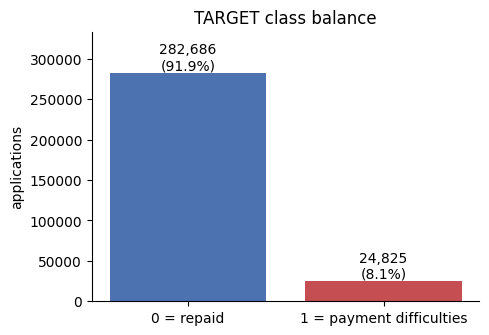

In [14]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = y.value_counts().sort_index()
bars = ax.bar(['0 = repaid', '1 = payment difficulties'], counts.values, color=['#4C72B0', '#C44E52'])
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / len(y):.1%})", ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.18)
ax.set_ylabel('applications')
ax.set_title('TARGET class balance')
sns.despine()
plt.show()

### 2.2 Baselines with no information

What a model scores when it knows nothing about the applicant. Accuracy and recall use a 0.5 threshold.

In [15]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

def log_loss_clipped(y_true, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def score(y_true, p):
    pred = (p >= 0.5).astype(int)
    return {
        'roc_auc': roc_auc_score(y_true, p),
        'pr_auc': average_precision_score(y_true, p),
        'log_loss': log_loss_clipped(y_true, p),
        'brier': brier_score_loss(y_true, p),
        'accuracy': (pred == y_true).mean(),
        'recall': pred[y_true == 1].mean(),
    }

rng = np.random.default_rng(42)
naive = {
    'always predict 0': np.zeros(len(y)),
    'always predict the default rate': np.full(len(y), default_rate),
    'random score': rng.random(len(y)),
}
pd.DataFrame({name: score(y.values, p) for name, p in naive.items()}).T.round(4)

,roc_auc,pr_auc,log_loss,brier,accuracy,recall
always predict 0,0.5000,0.0807,2.7883,0.0807,0.9193,0.0000
always predict the default rate,0.5000,0.0807,0.2805,0.0742,0.9193,0.0000
random score,0.5002,0.0809,0.9997,0.3333,0.4996,0.4994


### 2.3 Baselines from a single column

A model also has to beat what one existing column gives for free. The three external scores are the obvious candidates. Higher score means lower risk, so the risk score is the negative of the column. AUC is measured on the rows where the score exists.

In [16]:
ext = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']

rows = {}
for c in ext:
    present = app[c].notna()
    rows[c] = {
        'rows_with_score_pct': present.mean() * 100,
        'roc_auc': roc_auc_score(y[present], -app.loc[present, c]),
        'pr_auc': average_precision_score(y[present], -app.loc[present, c]),
    }

# mean of whichever of the three scores are present, covering almost every row
ext_mean = app[ext].mean(axis=1)
present = ext_mean.notna()
rows['mean of available EXT_SOURCE'] = {
    'rows_with_score_pct': present.mean() * 100,
    'roc_auc': roc_auc_score(y[present], -ext_mean[present]),
    'pr_auc': average_precision_score(y[present], -ext_mean[present]),
}
print('rows with none of the three scores:', (~present).sum())
pd.DataFrame(rows).T.round(4)

rows with none of the three scores: 172


,rows_with_score_pct,roc_auc,pr_auc
EXT_SOURCE_1,43.6189,0.6657,0.1465
EXT_SOURCE_2,99.7854,0.6561,0.1519
EXT_SOURCE_3,80.1747,0.6794,0.1583
mean of available EXT_SOURCE,99.9441,0.7165,0.1893


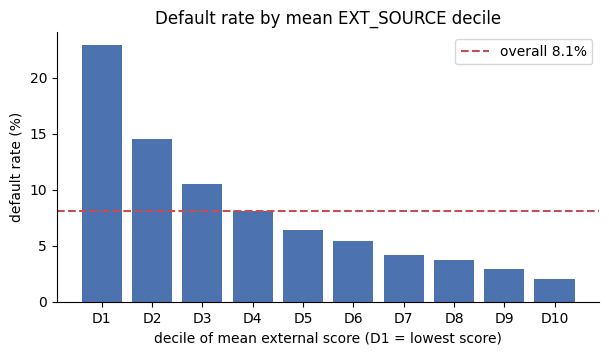

,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
size,30734.00,30734.00,30734.0,30734.00,30734.00,30733.00,30736.00,30732.00,30734.00,30734.00
default_rate_pct,22.93,14.51,10.5,8.11,6.43,5.39,4.15,3.74,2.92,2.04


In [17]:
# default rate by decile of the mean external score: how well one number separates the classes
deciles = pd.qcut(ext_mean, 10, labels=[f"D{i}" for i in range(1, 11)])
by_decile = app.groupby(deciles, observed=True)['TARGET'].agg(['size', 'mean'])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_decile.index.astype(str), by_decile['mean'] * 100, color='#4C72B0')
ax.axhline(default_rate * 100, color='#C44E52', linestyle='--', label=f"overall {default_rate:.1%}")
ax.set_xlabel('decile of mean external score (D1 = lowest score)')
ax.set_ylabel('default rate (%)')
ax.set_title('Default rate by mean EXT_SOURCE decile')
ax.legend()
sns.despine()
plt.show()

by_decile.assign(mean=(by_decile['mean'] * 100).round(2)).rename(columns={'mean': 'default_rate_pct'}).T

### 2.4 Validation scheme and its noise

Stratified 5-fold keeps the default rate the same in every fold. Scoring the single-column baseline on each fold shows how much AUC moves from the split alone, which is the size of difference that should not be read as an improvement.

In [18]:
from sklearn.model_selection import StratifiedKFold, KFold

risk = (-ext_mean).fillna((-ext_mean).median())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = []
for i, (_, val_idx) in enumerate(cv.split(app, y), start=1):
    folds.append({
        'fold': i,
        'rows': len(val_idx),
        'defaults': int(y.iloc[val_idx].sum()),
        'default_rate_pct': y.iloc[val_idx].mean() * 100,
        'baseline_roc_auc': roc_auc_score(y.iloc[val_idx], risk.iloc[val_idx]),
    })
folds = pd.DataFrame(folds).set_index('fold')
print(folds.round(4))
print(f"\nbaseline AUC across folds: mean {folds['baseline_roc_auc'].mean():.4f}, std {folds['baseline_roc_auc'].std():.4f}, "
      f"range {folds['baseline_roc_auc'].max() - folds['baseline_roc_auc'].min():.4f}")

plain = [y.iloc[val_idx].mean() * 100 for _, val_idx in KFold(n_splits=5, shuffle=True, random_state=42).split(app)]
print('default rate per fold without stratification:', np.round(plain, 2))

       rows  defaults  default_rate_pct  baseline_roc_auc
fold                                                     
1     61503      4965            8.0728            0.7156
2     61502      4965            8.0729            0.7224
3     61502      4965            8.0729            0.7155
4     61502      4965            8.0729            0.7217
5     61502      4965            8.0729            0.7070

baseline AUC across folds: mean 0.7165, std 0.0062, range 0.0154
default rate per fold without stratification: [8.05 8.03 8.26 7.97 8.05]


### Stage 2 findings

**Class balance**
- 24,825 defaults in 307,511 applications: a default rate of 8.07% (95% interval 7.98% to 8.17%), or 11.4 repaid loans for every default.
- No missing targets.

**Baselines with no information**
- Predicting "repaid" for everyone scores 91.93% accuracy and catches zero defaults. Accuracy is not a usable metric here.
- Any uninformed score gives ROC AUC 0.50 and PR AUC 0.081 (the default rate).
- Predicting the default rate for everyone gives log loss 0.2805 and Brier score 0.0742. These are the numbers to beat on calibration.

**Baseline from a single column**
- Each external score alone reaches ROC AUC 0.66 to 0.68.
- The mean of whichever external scores are present reaches ROC AUC 0.7165 and PR AUC 0.189, with no model and no training. Only 172 rows have none of the three.
- That single number separates the classes strongly: the default rate falls from 22.9% in the lowest decile to 2.0% in the highest.

**Validation**
- Stratified 5-fold puts exactly 4,965 defaults in every fold. Without stratification the fold default rate ranges from 7.97% to 8.26%.
- The same fixed score varies across folds by a standard deviation of 0.006 in AUC (range 0.015). The fold a model is scored on matters at that scale, so models must be compared fold by fold on identical folds, not by a single split.

**Decisions**
- Primary metric: ROC AUC (the competition metric). Report PR AUC alongside it, since it reflects the minority class.
- Validation: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, the same folds for every experiment.
- The bar for a real model is ROC AUC 0.7165, not 0.50. A model that does not clearly beat the mean external score has learned nothing beyond it.
- No resampling decision yet. AUC does not require balanced classes, so class weights or resampling are a modelling choice to test later, not a cleaning step.

## Stage 3: Missing values

Per-column rates, columns that go missing together, and whether missingness itself predicts default.

This stage counts true empty cells only. Placeholder values that stand in for missing (`365243`, `XNA`) are handled in stage 4.

### 3.1 Per-column rates

In [19]:
miss = app.isna()

missing = pd.DataFrame({
    'group': col_info['group'],
    'n_missing': miss.sum(),
    'missing_pct': (miss.mean() * 100).round(2),
})
missing = missing[missing['n_missing'] > 0].sort_values('n_missing', ascending=False)

print(f"columns with missing values: {len(missing)} of {app.shape[1]}")
print(f"cells missing overall:       {miss.values.mean():.1%}")

bands = pd.cut(miss.mean() * 100, [-0.001, 0, 1, 20, 50, 100],
               labels=['none', 'under 1%', '1% to 20%', '20% to 50%', 'over 50%'])
bands.value_counts().sort_index().rename('columns').to_frame()

columns with missing values: 67 of 122
cells missing overall:       24.4%


,columns
none,55
under 1%,10
1% to 20%,7
20% to 50%,9
over 50%,41


In [20]:
# every column with missing values outside the building block
missing[missing['group'] != 'building']

,group,n_missing,missing_pct
OWN_CAR_AGE,assets_housing,202929,65.99
EXT_SOURCE_1,external_scores,173378,56.38
OCCUPATION_TYPE,income_employment,96391,31.35
EXT_SOURCE_3,external_scores,60965,19.83
AMT_REQ_CREDIT_BUREAU_WEEK,bureau_enquiries,41519,13.50
AMT_REQ_CREDIT_BUREAU_MON,bureau_enquiries,41519,13.50
AMT_REQ_CREDIT_BUREAU_HOUR,bureau_enquiries,41519,13.50
AMT_REQ_CREDIT_BUREAU_YEAR,bureau_enquiries,41519,13.50
AMT_REQ_CREDIT_BUREAU_QRT,bureau_enquiries,41519,13.50
AMT_REQ_CREDIT_BUREAU_DAY,bureau_enquiries,41519,13.50


In [21]:
# the building block: 47 columns, summarised by measure
building = missing[missing['group'] == 'building'].copy()
building['measure'] = building.index.str.replace(r'_(AVG|MODE|MEDI)$', '', regex=True)
(building.groupby('measure')
         .agg(columns=('n_missing', 'size'), missing_pct_min=('missing_pct', 'min'), missing_pct_max=('missing_pct', 'max'))
         .sort_values('missing_pct_max', ascending=False))

,columns,missing_pct_min,missing_pct_max
measure,,,
COMMONAREA,3,69.87,69.87
NONLIVINGAPARTMENTS,3,69.43,69.43
FONDKAPREMONT,1,68.39,68.39
LIVINGAPARTMENTS,3,68.35,68.35
FLOORSMIN,3,67.85,67.85
YEARS_BUILD,3,66.50,66.50
LANDAREA,3,59.38,59.38
BASEMENTAREA,3,58.52,58.52
NONLIVINGAREA,3,55.18,55.18


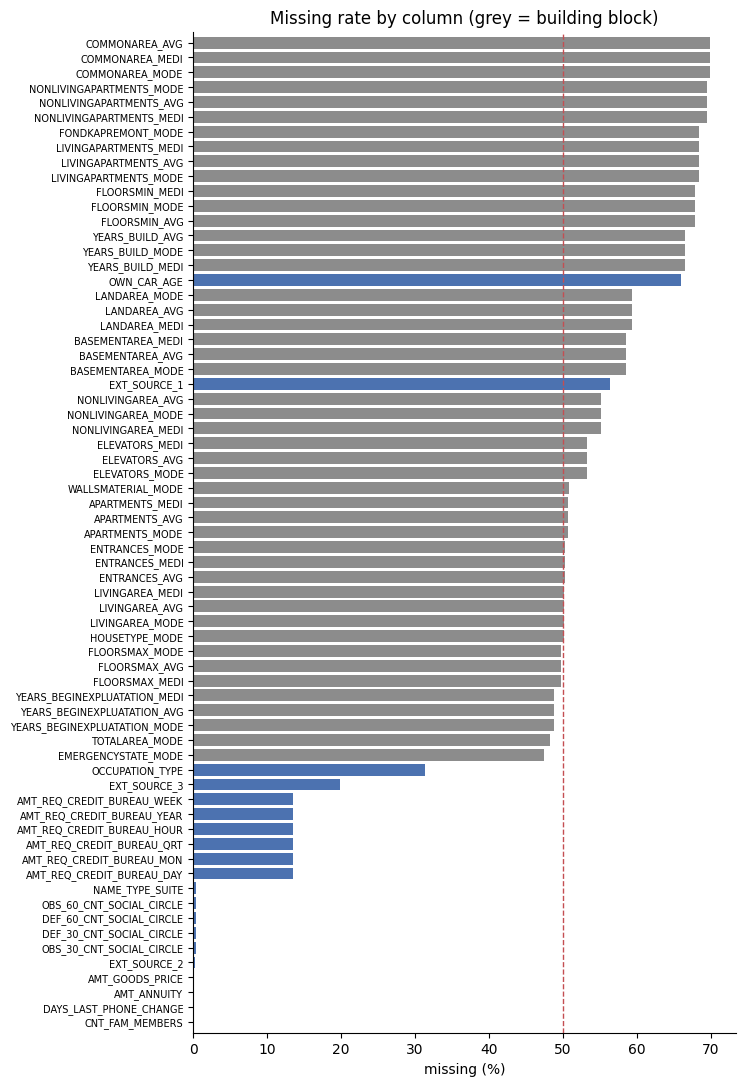

In [22]:
fig, ax = plt.subplots(figsize=(7, 13))
plot = missing.sort_values('missing_pct')
colors = np.where(plot['group'] == 'building', '#8C8C8C', '#4C72B0')
ax.barh(plot.index, plot['missing_pct'], color=colors)
ax.axvline(50, color='#C44E52', linestyle='--', linewidth=1)
ax.set_xlabel('missing (%)')
ax.set_title('Missing rate by column (grey = building block)')
ax.tick_params(axis='y', labelsize=7)
ax.margins(y=0.005)
sns.despine()
plt.show()

count    307511.0
mean         29.8
std          20.9
min           0.0
25%           5.0
50%          36.0
75%          49.0
max          61.0
dtype: float64

rows with no missing values: 8,602 (2.8%)


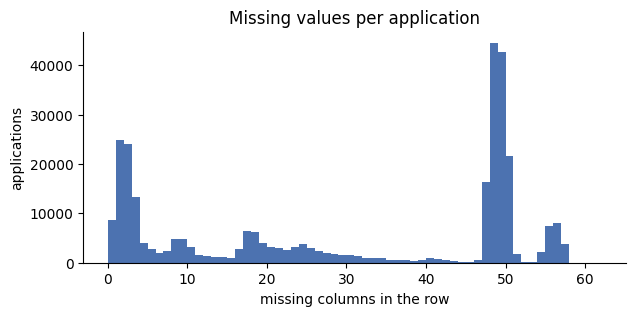

In [23]:
# missing values per row
per_row = miss.sum(axis=1)
print(per_row.describe().round(1))
print(f"\nrows with no missing values: {(per_row == 0).sum():,} ({(per_row == 0).mean():.1%})")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(per_row, bins=range(0, per_row.max() + 2), color='#4C72B0')
ax.set_xlabel('missing columns in the row')
ax.set_ylabel('applications')
ax.set_title('Missing values per application')
sns.despine()
plt.show()

### 3.2 Columns that go missing together

Two columns have the same missing pattern when they are empty on exactly the same rows. Grouping by pattern shows how many independent sources of missingness there really are.

In [24]:
patterns = {}
for c in missing.index:
    patterns.setdefault(miss[c].values.tobytes(), []).append(c)

pattern_table = pd.DataFrame([
    {'n_columns': len(members), 'missing_pct': round(miss[members[0]].mean() * 100, 2),
     'representative': members[0], 'columns': ', '.join(members)}
    for members in patterns.values()
]).sort_values('missing_pct', ascending=False).reset_index(drop=True)

print(f"{len(missing)} columns with missing values share {len(pattern_table)} distinct missing patterns")
with pd.option_context('display.max_colwidth', 150):
    display(pattern_table)

67 columns with missing values share 31 distinct missing patterns


,n_columns,missing_pct,representative,columns
0,3,69.87,COMMONAREA_MEDI,"COMMONAREA_MEDI, COMMONAREA_MODE, COMMONAREA_AVG"
1,3,69.43,NONLIVINGAPARTMENTS_MODE,"NONLIVINGAPARTMENTS_MODE, NONLIVINGAPARTMENTS_MEDI, NONLIVINGAPARTMENTS_AVG"
2,1,68.39,FONDKAPREMONT_MODE,FONDKAPREMONT_MODE
3,3,68.35,LIVINGAPARTMENTS_AVG,"LIVINGAPARTMENTS_AVG, LIVINGAPARTMENTS_MEDI, LIVINGAPARTMENTS_MODE"
4,3,67.85,FLOORSMIN_MEDI,"FLOORSMIN_MEDI, FLOORSMIN_MODE, FLOORSMIN_AVG"
5,3,66.50,YEARS_BUILD_MODE,"YEARS_BUILD_MODE, YEARS_BUILD_MEDI, YEARS_BUILD_AVG"
6,1,65.99,OWN_CAR_AGE,OWN_CAR_AGE
7,3,59.38,LANDAREA_AVG,"LANDAREA_AVG, LANDAREA_MEDI, LANDAREA_MODE"
8,3,58.52,BASEMENTAREA_MODE,"BASEMENTAREA_MODE, BASEMENTAREA_MEDI, BASEMENTAREA_AVG"
9,1,56.38,EXT_SOURCE_1,EXT_SOURCE_1


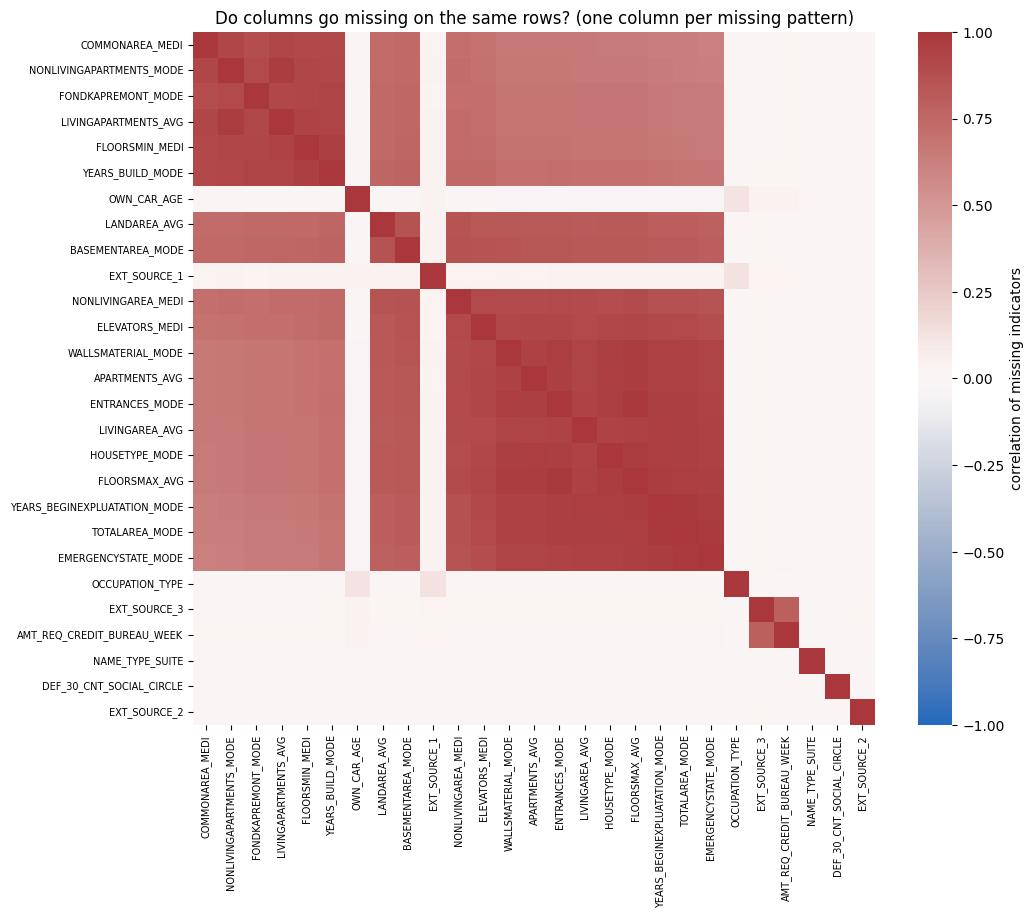

,a,b,corr,group_a,group_b
341,EXT_SOURCE_3,AMT_REQ_CREDIT_BUREAU_WEEK,0.795,external_scores,bureau_enquiries
209,EXT_SOURCE_1,OCCUPATION_TYPE,0.129,external_scores,income_employment
155,OWN_CAR_AGE,OCCUPATION_TYPE,0.124,assets_housing,income_employment
143,OWN_CAR_AGE,EXT_SOURCE_1,0.046,assets_housing,external_scores
180,BASEMENTAREA_MODE,EXT_SOURCE_1,0.042,building,external_scores
157,OWN_CAR_AGE,AMT_REQ_CREDIT_BUREAU_WEEK,0.042,assets_housing,bureau_enquiries
156,OWN_CAR_AGE,EXT_SOURCE_3,0.042,assets_housing,external_scores
202,EXT_SOURCE_1,ENTRANCES_MODE,0.041,external_scores,building
208,EXT_SOURCE_1,EMERGENCYSTATE_MODE,0.041,external_scores,building
207,EXT_SOURCE_1,TOTALAREA_MODE,0.041,external_scores,building


In [25]:
# correlation between missing indicators, one column per pattern, for patterns above 0.1% missing
reps = pattern_table.loc[pattern_table['missing_pct'] > 0.1, 'representative'].tolist()
miss_corr = miss[reps].astype(float).corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(miss_corr, cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={'label': 'correlation of missing indicators'})
ax.tick_params(labelsize=7)
ax.set_title('Do columns go missing on the same rows? (one column per missing pattern)')
plt.show()

# strongest pairs across different groups
pairs = (miss_corr.where(np.triu(np.ones(miss_corr.shape, dtype=bool), k=1)).stack()
                  .rename('corr').reset_index())
pairs.columns = ['a', 'b', 'corr']
pairs['group_a'] = pairs['a'].map(col_info['group'])
pairs['group_b'] = pairs['b'].map(col_info['group'])
pairs[pairs['group_a'] != pairs['group_b']].sort_values('corr', key=abs, ascending=False).head(10).round(3)

all 47 building columns missing: 47.4%
none missing:                    25.6%
some but not all missing:        27.0%


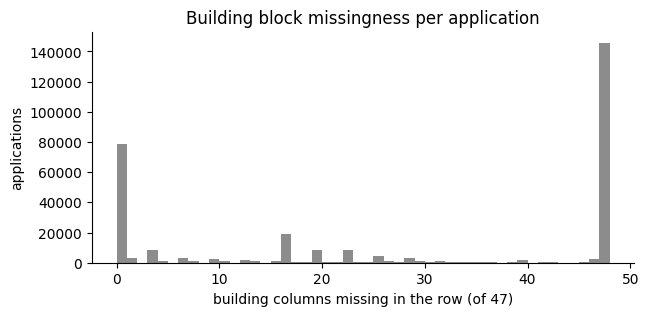

In [26]:
# is the building block all-or-nothing?
building_cols = groups['building']
n_building_missing = miss[building_cols].sum(axis=1)

print(f"all {len(building_cols)} building columns missing: {(n_building_missing == len(building_cols)).mean():.1%}")
print(f"none missing:                    {(n_building_missing == 0).mean():.1%}")
print(f"some but not all missing:        {((n_building_missing > 0) & (n_building_missing < len(building_cols))).mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(n_building_missing, bins=range(0, len(building_cols) + 2), color='#8C8C8C')
ax.set_xlabel('building columns missing in the row (of 47)')
ax.set_ylabel('applications')
ax.set_title('Building block missingness per application')
sns.despine()
plt.show()

In [27]:
# what explains the larger gaps?
print('OWN_CAR_AGE missing, by FLAG_OWN_CAR')
print((miss['OWN_CAR_AGE'].groupby(app['FLAG_OWN_CAR']).agg(['size', 'mean']).rename(columns={'mean': 'missing_rate'})).round(4))

print('\nOCCUPATION_TYPE missing, by NAME_INCOME_TYPE')
print((miss['OCCUPATION_TYPE'].groupby(app['NAME_INCOME_TYPE']).agg(['size', 'mean']).rename(columns={'mean': 'missing_rate'})
       .sort_values('size', ascending=False)).round(4))

print('\nEXT_SOURCE_3 missing, by whether the bureau enquiry counts are missing')
print(pd.crosstab(miss['AMT_REQ_CREDIT_BUREAU_YEAR'].map({True: 'enquiries missing', False: 'enquiries present'}),
                  miss['EXT_SOURCE_3'].map({True: 'EXT_3 missing', False: 'EXT_3 present'}), normalize='index').round(4))

print('\nEXT_SOURCE_1 missing rate, by age band (years)')
age_band = pd.cut(-app['DAYS_BIRTH'] / 365.25, [20, 30, 40, 50, 60, 70])
print(miss['EXT_SOURCE_1'].groupby(age_band, observed=True).mean().round(4))

OWN_CAR_AGE missing, by FLAG_OWN_CAR
                size  missing_rate
FLAG_OWN_CAR                      
N             202924           1.0
Y             104587           0.0

OCCUPATION_TYPE missing, by NAME_INCOME_TYPE
                        size  missing_rate
NAME_INCOME_TYPE                          
Working               158774        0.1570
Commercial associate   71617        0.1717
Pensioner              55362        0.9999
State servant          21703        0.1745
Unemployed                22        1.0000
Student                   18        0.2778
Businessman               10        0.2000
Maternity leave            5        0.2000

EXT_SOURCE_3 missing, by whether the bureau enquiry counts are missing


EXT_SOURCE_3                EXT_3 missing  EXT_3 present
AMT_REQ_CREDIT_BUREAU_YEAR                              
enquiries missing                  1.0000         0.0000
enquiries present                  0.0731         0.9269

EXT_SOURCE_1 missing rate, by age band (years)
DAYS_BIRTH
(20, 30]    0.4232
(30, 40]    0.4333
(40, 50]    0.5595
(50, 60]    0.6973
(60, 70]    0.8002
Name: EXT_SOURCE_1, dtype: float64


### 3.3 Does missingness predict default?

For each missing pattern, the default rate on rows where the column is empty against rows where it is filled. `relative_risk` above 1 means applicants with the value missing default more often. With 307,511 rows almost any gap is statistically significant, so the size of the gap is what matters.

In [28]:
from scipy.stats import chi2_contingency

rows = []
for _, p in pattern_table.iterrows():
    m = miss[p['representative']]
    if m.sum() < 500:
        continue
    rate_missing, rate_present = y[m].mean(), y[~m].mean()
    rows.append({
        'representative': p['representative'],
        'n_columns': p['n_columns'],
        'missing_pct': p['missing_pct'],
        'default_pct_missing': rate_missing * 100,
        'default_pct_present': rate_present * 100,
        'difference_pts': (rate_missing - rate_present) * 100,
        'relative_risk': rate_missing / rate_present,
        'indicator_auc': roc_auc_score(y, m.astype(int)),
        'p_value': chi2_contingency(pd.crosstab(m, y))[1],
    })
miss_signal = pd.DataFrame(rows).set_index('representative').sort_values('difference_pts', key=abs, ascending=False)
miss_signal.round({'default_pct_missing': 2, 'default_pct_present': 2, 'difference_pts': 2,
                   'relative_risk': 3, 'indicator_auc': 4, 'p_value': 4})

,n_columns,missing_pct,default_pct_missing,default_pct_present,difference_pts,relative_risk,indicator_auc,p_value
representative,,,,,,,,
DEF_30_CNT_SOCIAL_CIRCLE,4,0.33,3.53,8.09,-4.56,0.436,0.4990,0.0000
NAME_TYPE_SUITE,1,0.42,5.42,8.08,-2.67,0.670,0.4992,0.0005
AMT_REQ_CREDIT_BUREAU_WEEK,6,13.50,10.34,7.72,2.62,1.339,0.5206,0.0000
OCCUPATION_TYPE,1,31.35,6.51,8.79,-2.27,0.741,0.4671,0.0000
EMERGENCYSTATE_MODE,1,47.40,9.26,7.00,2.26,1.322,0.5379,0.0000
TOTALAREA_MODE,1,48.27,9.23,6.99,2.24,1.321,0.5378,0.0000
ENTRANCES_MODE,3,50.35,9.18,6.95,2.23,1.320,0.5375,0.0000
FLOORSMAX_AVG,3,49.76,9.19,6.97,2.23,1.320,0.5375,0.0000
YEARS_BEGINEXPLUATATION_MODE,3,48.78,9.20,6.99,2.21,1.316,0.5372,0.0000


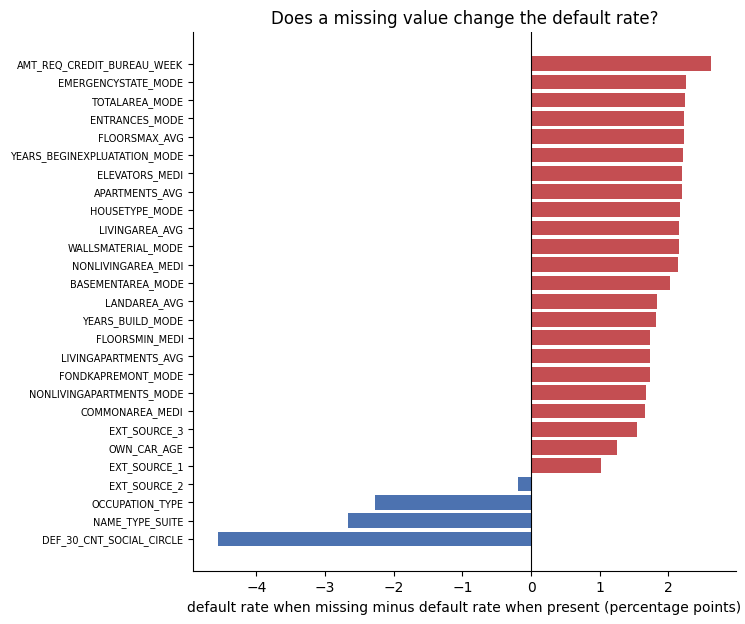

In [29]:
fig, ax = plt.subplots(figsize=(7, 7))
plot = miss_signal.sort_values('difference_pts')
ax.barh(plot.index, plot['difference_pts'], color=np.where(plot['difference_pts'] > 0, '#C44E52', '#4C72B0'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('default rate when missing minus default rate when present (percentage points)')
ax.set_title('Does a missing value change the default rate?')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

In [30]:
# does the amount of missing information matter?
count_bands = pd.cut(per_row, [-1, 0, 5, 20, 40, 50, 70], labels=['0', '1-5', '6-20', '21-40', '41-50', '51+'])
by_count = app.groupby(count_bands, observed=True)['TARGET'].agg(['size', 'mean'])
by_count['default_pct'] = (by_count.pop('mean') * 100).round(2)
print(by_count)
print(f"\nAUC of the missing-count per row as a score: {roc_auc_score(y, per_row):.4f}")

ext_missing = miss[ext].sum(axis=1)
by_ext = app.groupby(ext_missing)['TARGET'].agg(['size', 'mean'])
by_ext['default_pct'] = (by_ext.pop('mean') * 100).round(2)
by_ext.index.name = 'external scores missing'
print()
print(by_ext)

         size  default_pct
0        8602         6.11
1-5     68829         6.73
6-20    45873         7.12
21-40   33040         7.51
41-50  127634         8.83
51+     23533        11.25

AUC of the missing-count per row as a score: 0.5464

                           size  default_pct
external scores missing                     
0                        109589         7.30
1                        161013         8.18
2                         36737         9.92
3                           172         8.14


In [31]:
# occupation: is "missing" just pensioners, and how do the rest of the missing behave?
occ_missing = miss['OCCUPATION_TYPE']
pensioner = app['NAME_INCOME_TYPE'] == 'Pensioner'
check = app.groupby([occ_missing.map({True: 'occupation missing', False: 'occupation present'}),
                     pensioner.map({True: 'pensioner', False: 'not pensioner'})])['TARGET'].agg(['size', 'mean'])
check['default_pct'] = (check.pop('mean') * 100).round(2)
check

size  default_pct
OCCUPATION_TYPE    NAME_INCOME_TYPE                     
occupation missing not pensioner      41034         8.03
                   pensioner          55357         5.39
occupation present not pensioner     211115         8.79
                   pensioner              5         0.00

### Stage 3 findings

**Per-column rates**
- 67 of 122 columns have missing values, and 24.4% of all cells are empty.
- 55 columns are complete, 10 are under 1% missing, 7 are between 1% and 20%, 9 are between 20% and 50%, and 41 are over 50%.
- Outside the building block only five gaps matter: `OWN_CAR_AGE` (66.0%), `EXT_SOURCE_1` (56.4%), `OCCUPATION_TYPE` (31.4%), `EXT_SOURCE_3` (19.8%) and the six bureau enquiry counts (13.5%).
- Only 2.8% of rows are complete. The median row is missing 36 columns, so dropping incomplete rows is not an option.

**Columns that go missing together**
- The 67 columns share only 31 distinct missing patterns.
- The `_AVG`, `_MODE` and `_MEDI` versions of each building measure are always missing on the same rows, as are the six bureau enquiry counts and the four social circle counts.
- The building block is close to all-or-nothing: 47.4% of applicants have all 47 columns empty, 25.6% have none empty, and 27.0% are in between.
- `OWN_CAR_AGE` is missing for every applicant without a car and for almost none with one. Its missingness is the same information as `FLAG_OWN_CAR`.
- `OCCUPATION_TYPE` is missing for 99.99% of pensioners and for about 16% to 17% of the working categories.
- `EXT_SOURCE_3` is missing on every row where the bureau enquiry counts are missing (correlation 0.80 between the two indicators). This suggests `EXT_SOURCE_3` depends on the applicant having a credit bureau record, though the source of the score is not documented.
- `EXT_SOURCE_1` missingness rises with age, from 42% for applicants in their twenties to 80% for those over 60.

**Does missingness predict default?**
- Yes, modestly. Applicants with missing building information default at about 9.2% against 7.0% for those with it (relative risk 1.32).
- Missing bureau enquiry counts: 10.3% against 7.7% (relative risk 1.34).
- Missing `EXT_SOURCE_3`: 9.3% against 7.8%. Missing `EXT_SOURCE_1`: 8.5% against 7.5%. The default rate climbs with the number of external scores missing: 7.3% with none missing, 8.2% with one, 9.9% with two.
- Missing social circle counts: 3.5% against 8.1%, the largest gap, but on only 1,021 rows.
- Missing `OCCUPATION_TYPE` looks protective (6.5% against 8.8%), but that is mostly pensioners, who default at 5.4%. Among non-pensioners the gap is small (8.0% against 8.8%).
- The amount of missing information matters as a whole: the default rate rises from 6.1% for complete rows to 11.3% for rows missing 51 or more columns. The missing count alone scores ROC AUC 0.546.
- No single missing indicator is strong on its own (indicator AUC at most 0.538). They are supporting features, not main ones.

**Decisions**
- Do not drop rows, and do not drop a column for its missing rate alone. Whether the building columns earn their place is decided on signal in stages 8 and 9.
- Leave values empty for tree models that handle missing values natively. For linear models, impute and add indicators.
- Add one indicator per missing pattern, not per column. The useful ones are: building information missing (as a count of the 47, or an all-missing flag), bureau enquiries missing, and the number of external scores missing.
- Add the total missing count per row as a feature.
- No indicator for `OWN_CAR_AGE`, since `FLAG_OWN_CAR` already carries it.
- Treat missing `OCCUPATION_TYPE` as its own category.
- The tiny gaps (`AMT_ANNUITY` 12 rows, `CNT_FAM_MEMBERS` 2, `DAYS_LAST_PHONE_CHANGE` 1, `AMT_GOODS_PRICE` 278, `EXT_SOURCE_2` 660) need no indicator.

## Stage 4: Placeholders and anomalies

`365243`, `XNA`, impossible values, extreme outliers, and the cleaning rule for each.

### 4.1 Placeholders in numeric columns

A numeric placeholder shows up as a value sitting far away from everything else in the column, often on many rows. For each numeric column, the cell below measures the gap between the largest value and the next distinct value below it, in units of the column's 1st to 99th percentile spread. The same is done at the bottom end.

In [32]:
numeric_cols = [c for c in app.select_dtypes('number').columns
                if col_info.loc[c, 'semantic_type'] in ('continuous', 'discrete')]

rows = []
for c in numeric_cols:
    s = app[c].dropna()
    distinct = np.sort(s.unique())
    spread = s.quantile(0.99) - s.quantile(0.01)
    if len(distinct) < 3 or spread == 0:
        continue
    rows.append({'column': c, 'end': 'max', 'value': distinct[-1], 'next_value': distinct[-2],
                 'rows_at_value': int((s == distinct[-1]).sum()), 'gap_in_spreads': (distinct[-1] - distinct[-2]) / spread})
    rows.append({'column': c, 'end': 'min', 'value': distinct[0], 'next_value': distinct[1],
                 'rows_at_value': int((s == distinct[0]).sum()), 'gap_in_spreads': (distinct[1] - distinct[0]) / spread})

edges = pd.DataFrame(rows)
edges[edges['gap_in_spreads'] > 1].sort_values('gap_in_spreads', ascending=False).round(2)

,column,end,value,next_value,rows_at_value,gap_in_spreads
2,AMT_INCOME_TOTAL,max,117000000.0,18000090.0,1,231.58
136,AMT_REQ_CREDIT_BUREAU_QRT,max,261.0,19.0,1,121.00
122,OBS_30_CNT_SOCIAL_CIRCLE,max,348.0,47.0,1,30.10
126,OBS_60_CNT_SOCIAL_CIRCLE,max,344.0,47.0,1,29.70
124,DEF_30_CNT_SOCIAL_CIRCLE,max,34.0,8.0,1,13.00
128,DEF_60_CNT_SOCIAL_CIRCLE,max,24.0,7.0,1,8.50
0,CNT_CHILDREN,max,19.0,14.0,2,1.67


In [33]:
# the one true numeric placeholder: DAYS_EMPLOYED = 365243 (about 1,000 years)
placeholder = app['DAYS_EMPLOYED'] == 365243
print(f"DAYS_EMPLOYED == 365243: {placeholder.sum():,} rows ({placeholder.mean():.1%})")
print('other positive DAYS_EMPLOYED values:', ((app['DAYS_EMPLOYED'] > 0) & ~placeholder).sum())
print('365243 anywhere else in the table:', {c: int((app[c] == 365243).sum()) for c in numeric_cols if c != 'DAYS_EMPLOYED' and (app[c] == 365243).any()})

who = pd.DataFrame({
    'rows': app.groupby('NAME_INCOME_TYPE').size(),
    'with_placeholder': placeholder.groupby(app['NAME_INCOME_TYPE']).sum(),
})
who['placeholder_rate'] = (who['with_placeholder'] / who['rows']).round(4)
print()
print(who.sort_values('rows', ascending=False))

print('\nplaceholder rows by ORGANIZATION_TYPE == XNA, FLAG_EMP_PHONE and OCCUPATION_TYPE missing')
print(pd.DataFrame({
    'ORGANIZATION_TYPE is XNA': (app.loc[placeholder, 'ORGANIZATION_TYPE'] == 'XNA').mean(),
    'XNA rows that are placeholder': placeholder[app['ORGANIZATION_TYPE'] == 'XNA'].mean(),
    'FLAG_EMP_PHONE is 0': (app.loc[placeholder, 'FLAG_EMP_PHONE'] == 0).mean(),
    'FLAG_EMP_PHONE 0 rows that are placeholder': placeholder[app['FLAG_EMP_PHONE'] == 0].mean(),
    'OCCUPATION_TYPE missing': app.loc[placeholder, 'OCCUPATION_TYPE'].isna().mean(),
}, index=['share']).T.round(4))

print(f"\ndefault rate with placeholder: {y[placeholder].mean():.2%}   without: {y[~placeholder].mean():.2%}")

DAYS_EMPLOYED == 365243: 55,374 rows (18.0%)
other positive DAYS_EMPLOYED values: 0
365243 anywhere else in the table: {}

                        rows  with_placeholder  placeholder_rate
NAME_INCOME_TYPE                                                
Working               158774                 0            0.0000
Commercial associate   71617                 0            0.0000
Pensioner              55362             55352            0.9998
State servant          21703                 0            0.0000
Unemployed                22                22            1.0000
Student                   18                 0            0.0000
Businessman               10                 0            0.0000
Maternity leave            5                 0            0.0000

placeholder rows by ORGANIZATION_TYPE == XNA, FLAG_EMP_PHONE and OCCUPATION_TYPE missing
                                             share
ORGANIZATION_TYPE is XNA                    1.0000
XNA rows that are placeholder      

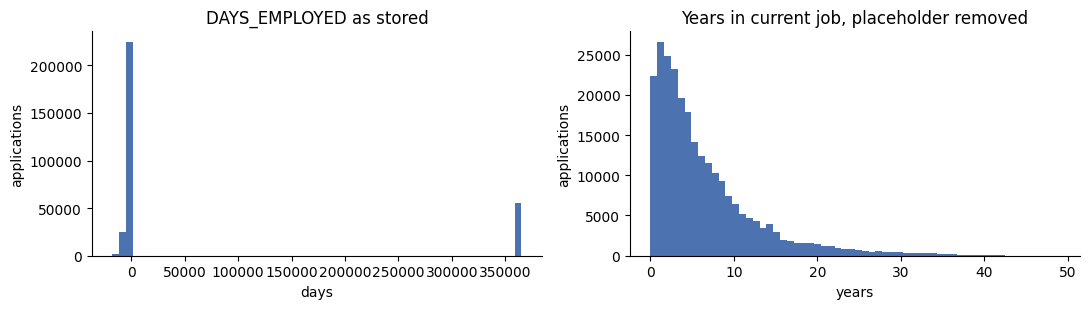

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(app['DAYS_EMPLOYED'], bins=60, color='#4C72B0')
axes[0].set_title('DAYS_EMPLOYED as stored')
axes[0].set_xlabel('days')
axes[1].hist(-app.loc[~placeholder, 'DAYS_EMPLOYED'] / 365.25, bins=60, color='#4C72B0')
axes[1].set_title('Years in current job, placeholder removed')
axes[1].set_xlabel('years')
for ax in axes:
    ax.set_ylabel('applications')
sns.despine()
plt.tight_layout()
plt.show()

### 4.2 Placeholders in text columns

In [35]:
placeholder_words = {'xna', 'xap', 'unknown', 'not specified', 'n/a', 'na', 'none', 'missing', ''}
catch_all_words = {'other', 'others', 'other_a', 'other_b'}

rows = []
for c in text_cols:
    for value, n in app[c].value_counts().items():
        key = str(value).strip().lower()
        if key in placeholder_words or key in catch_all_words:
            rows.append({'column': c, 'value': value,
                         'kind': 'placeholder' if key in placeholder_words else 'catch-all category',
                         'rows': n, 'share_pct': round(n / len(app) * 100, 3),
                         'default_pct': round(y[app[c] == value].mean() * 100, 2)})
pd.DataFrame(rows).sort_values(['kind', 'rows'], ascending=[False, False]).reset_index(drop=True)

,column,value,kind,rows,share_pct,default_pct
0,ORGANIZATION_TYPE,XNA,placeholder,55374,18.007,5.40
1,FONDKAPREMONT_MODE,not specified,placeholder,5687,1.849,7.54
2,CODE_GENDER,XNA,placeholder,4,0.001,0.00
3,NAME_FAMILY_STATUS,Unknown,placeholder,2,0.001,0.00
4,ORGANIZATION_TYPE,Other,catch-all category,16683,5.425,7.64
5,NAME_TYPE_SUITE,Other_B,catch-all category,1770,0.576,9.83
6,WALLSMATERIAL_MODE,Others,catch-all category,1625,0.528,8.31
7,NAME_TYPE_SUITE,Other_A,catch-all category,866,0.282,8.78


In [36]:
# missing rates once placeholders are counted as missing
with_placeholders = app.copy()
with_placeholders['DAYS_EMPLOYED'] = with_placeholders['DAYS_EMPLOYED'].replace(365243, np.nan)
with_placeholders[['CODE_GENDER', 'ORGANIZATION_TYPE']] = with_placeholders[['CODE_GENDER', 'ORGANIZATION_TYPE']].replace('XNA', np.nan)
with_placeholders['NAME_FAMILY_STATUS'] = with_placeholders['NAME_FAMILY_STATUS'].replace('Unknown', np.nan)
with_placeholders['FONDKAPREMONT_MODE'] = with_placeholders['FONDKAPREMONT_MODE'].replace('not specified', np.nan)

changed = ['DAYS_EMPLOYED', 'ORGANIZATION_TYPE', 'CODE_GENDER', 'NAME_FAMILY_STATUS', 'FONDKAPREMONT_MODE']
print(pd.DataFrame({'missing_pct_stored': app[changed].isna().mean() * 100,
                    'missing_pct_true': with_placeholders[changed].isna().mean() * 100}).round(3))
print(f"\ncolumns with missing values: {app.isna().any().sum()} as stored, {with_placeholders.isna().any().sum()} counting placeholders")
del with_placeholders

                    missing_pct_stored  missing_pct_true
DAYS_EMPLOYED                    0.000            18.007
ORGANIZATION_TYPE                0.000            18.007
CODE_GENDER                      0.000             0.001
NAME_FAMILY_STATUS               0.000             0.001
FONDKAPREMONT_MODE              68.386            70.236



columns with missing values: 67 as stored, 71 counting placeholders


### 4.3 Impossible and inconsistent values

Each check is a rule the data should satisfy. `violations` counts the rows that break it. Checks marked *info* are not impossible, only worth knowing.

In [37]:
age_days = -app['DAYS_BIRTH']
emp_days = -app['DAYS_EMPLOYED'].where(~placeholder)
normalised = [c for c in groups['building'] if pd.api.types.is_numeric_dtype(app[c])] + ext

checks = {
    'DAYS_BIRTH is positive': app['DAYS_BIRTH'] > 0,
    'DAYS_EMPLOYED is positive (placeholder excluded)': app['DAYS_EMPLOYED'].where(~placeholder) > 0,
    'DAYS_REGISTRATION is positive': app['DAYS_REGISTRATION'] > 0,
    'DAYS_ID_PUBLISH is positive': app['DAYS_ID_PUBLISH'] > 0,
    'DAYS_LAST_PHONE_CHANGE is positive': app['DAYS_LAST_PHONE_CHANGE'] > 0,
    'age under 18 or over 75': (age_days < 18 * 365.25) | (age_days > 75 * 365.25),
    'in current job longer than alive': emp_days > age_days,
    'started current job before age 14': (age_days - emp_days) < 14 * 365.25,
    'registration changed before birth': -app['DAYS_REGISTRATION'] > age_days,
    'ID document issued before birth': -app['DAYS_ID_PUBLISH'] > age_days,
    'phone changed before birth': -app['DAYS_LAST_PHONE_CHANGE'] > age_days,
    'children >= family members': app['CNT_CHILDREN'] >= app['CNT_FAM_MEMBERS'],
    'family members minus children is not 1 or 2 (info)': ~(app['CNT_FAM_MEMBERS'] - app['CNT_CHILDREN']).isin([1, 2]) & app['CNT_FAM_MEMBERS'].notna(),
    'more than 10 children (info)': app['CNT_CHILDREN'] > 10,
    'DEF_30 > OBS_30 social circle': app['DEF_30_CNT_SOCIAL_CIRCLE'] > app['OBS_30_CNT_SOCIAL_CIRCLE'],
    'DEF_60 > OBS_60 social circle': app['DEF_60_CNT_SOCIAL_CIRCLE'] > app['OBS_60_CNT_SOCIAL_CIRCLE'],
    'DEF_60 > DEF_30 social circle': app['DEF_60_CNT_SOCIAL_CIRCLE'] > app['DEF_30_CNT_SOCIAL_CIRCLE'],
    'OBS_60 > OBS_30 social circle': app['OBS_60_CNT_SOCIAL_CIRCLE'] > app['OBS_30_CNT_SOCIAL_CIRCLE'],
    'owns car but car age missing': (app['FLAG_OWN_CAR'] == 'Y') & app['OWN_CAR_AGE'].isna(),
    'no car but car age present': (app['FLAG_OWN_CAR'] == 'N') & app['OWN_CAR_AGE'].notna(),
    'car older than 60 years (info)': app['OWN_CAR_AGE'] > 60,
    'employer phone given but no employment': (app['FLAG_EMP_PHONE'] == 1) & placeholder,
    'no mobile phone (info)': app['FLAG_MOBIL'] == 0,
    'amount is zero or negative': (app[['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']] <= 0).any(axis=1),
    'annuity >= credit': app['AMT_ANNUITY'] >= app['AMT_CREDIT'],
    'annuity > income (info)': app['AMT_ANNUITY'] > app['AMT_INCOME_TOTAL'],
    'goods price > credit (info)': app['AMT_GOODS_PRICE'] > app['AMT_CREDIT'],
    'normalised column outside 0 to 1': ((app[normalised] < 0) | (app[normalised] > 1)).any(axis=1),
    'region rating outside 1 to 3': ~app['REGION_RATING_CLIENT'].isin([1, 2, 3]) | ~app['REGION_RATING_CLIENT_W_CITY'].isin([1, 2, 3]),
    'hour outside 0 to 23': ~app['HOUR_APPR_PROCESS_START'].between(0, 23),
    'bureau enquiry count is negative': (app[groups['bureau_enquiries']] < 0).any(axis=1),
}

consistency = pd.DataFrame([
    {'check': name, 'violations': int(mask.sum()), 'share_pct': round(mask.mean() * 100, 3),
     'default_pct': round(y[mask].mean() * 100, 2) if mask.sum() else np.nan}
    for name, mask in checks.items()
]).set_index('check')
consistency

,violations,share_pct,default_pct
check,,,
DAYS_BIRTH is positive,0,0.000,NaN
DAYS_EMPLOYED is positive (placeholder excluded),0,0.000,NaN
DAYS_REGISTRATION is positive,0,0.000,NaN
DAYS_ID_PUBLISH is positive,0,0.000,NaN
DAYS_LAST_PHONE_CHANGE is positive,0,0.000,NaN
age under 18 or over 75,0,0.000,NaN
in current job longer than alive,0,0.000,NaN
started current job before age 14,0,0.000,NaN
registration changed before birth,1,0.000,0.00


In [38]:
# values that pile up suspiciously
print('OWN_CAR_AGE, oldest values:')
print(app['OWN_CAR_AGE'].value_counts().sort_index().tail(12).to_string())

zero_phone = app['DAYS_LAST_PHONE_CHANGE'] == 0
print(f"\nDAYS_LAST_PHONE_CHANGE == 0: {zero_phone.sum():,} rows ({zero_phone.mean():.1%}), default rate {y[zero_phone].mean():.2%} against {y[~zero_phone].mean():.2%}")
print('next most common values:', app['DAYS_LAST_PHONE_CHANGE'].value_counts().head(4).to_dict())

zero_reg = app['DAYS_REGISTRATION'] == 0
zero_id = app['DAYS_ID_PUBLISH'] == 0
print(f"DAYS_REGISTRATION == 0: {zero_reg.sum():,} rows   DAYS_ID_PUBLISH == 0: {zero_id.sum():,} rows")

OWN_CAR_AGE, oldest values:
OWN_CAR_AGE
50.0       1
51.0       3
52.0       1
54.0      12
55.0       4
56.0       1
57.0       1
63.0       2
64.0    2443
65.0     891
69.0       1
91.0       2

DAYS_LAST_PHONE_CHANGE == 0: 37,672 rows (12.3%), default rate 9.67% against 7.85%
next most common values: {0.0: 37672, -1.0: 2812, -2.0: 2318, -3.0: 1763}
DAYS_REGISTRATION == 0: 80 rows   DAYS_ID_PUBLISH == 0: 16 rows


### 4.4 Extreme outliers

For every non-binary numeric column outside the building block. `max_over_p99` shows how far the largest value sits above the 99th percentile, and `rows_over_10x_p99` counts the rows more than ten times above it.

In [39]:
outlier_cols = [c for c in numeric_cols if col_info.loc[c, 'group'] != 'building']
clean_numeric = app[outlier_cols].copy()
clean_numeric['DAYS_EMPLOYED'] = clean_numeric['DAYS_EMPLOYED'].where(~placeholder)

q = clean_numeric.quantile([0, 0.01, 0.5, 0.99, 0.999, 1]).T
q.columns = ['min', 'p1', 'median', 'p99', 'p99.9', 'max']
q['skew'] = clean_numeric.skew()
q['max_over_p99'] = q['max'] / q['p99'].replace(0, np.nan)
q['rows_over_10x_p99'] = [(clean_numeric[c] > 10 * q.loc[c, 'p99']).sum() if q.loc[c, 'p99'] > 0 else np.nan for c in q.index]
q.sort_values('skew', key=abs, ascending=False).round(2)

,min,p1,median,p99,p99.9,max,skew,max_over_p99,rows_over_10x_p99
AMT_INCOME_TOTAL,25650.00,45000.00,147150.00,472500.00,900000.00,1.170000e+08,391.56,247.62,5.0
AMT_REQ_CREDIT_BUREAU_QRT,0.00,0.00,0.00,2.00,4.00,2.610000e+02,134.37,130.50,1.0
AMT_REQ_CREDIT_BUREAU_DAY,0.00,0.00,0.00,0.00,1.00,9.000000e+00,27.04,NaN,NaN
AMT_REQ_CREDIT_BUREAU_HOUR,0.00,0.00,0.00,0.00,1.00,4.000000e+00,14.53,NaN,NaN
OBS_30_CNT_SOCIAL_CIRCLE,0.00,0.00,0.00,10.00,17.00,3.480000e+02,12.14,34.80,1.0
OBS_60_CNT_SOCIAL_CIRCLE,0.00,0.00,0.00,10.00,16.00,3.440000e+02,12.07,34.40,1.0
AMT_REQ_CREDIT_BUREAU_WEEK,0.00,0.00,0.00,1.00,2.00,8.000000e+00,9.29,8.00,0.0
AMT_REQ_CREDIT_BUREAU_MON,0.00,0.00,0.00,4.00,12.00,2.700000e+01,7.80,6.75,0.0
DEF_60_CNT_SOCIAL_CIRCLE,0.00,0.00,0.00,2.00,3.00,2.400000e+01,5.28,12.00,1.0
DEF_30_CNT_SOCIAL_CIRCLE,0.00,0.00,0.00,2.00,4.00,3.400000e+01,5.18,17.00,1.0


In [40]:
# the extreme rows themselves
show = ['SK_ID_CURR', 'TARGET', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE']
print('highest incomes')
display(app.nlargest(6, 'AMT_INCOME_TOTAL')[show])

for c, limit in [('OBS_30_CNT_SOCIAL_CIRCLE', 50), ('DEF_30_CNT_SOCIAL_CIRCLE', 10), ('AMT_REQ_CREDIT_BUREAU_QRT', 20),
                 ('CNT_CHILDREN', 8), ('CNT_FAM_MEMBERS', 10), ('AMT_INCOME_TOTAL', 2_000_000)]:
    over = app[c] > limit
    top = np.sort(app.loc[over, c].unique())[::-1][:6].tolist()
    print(f"{c} > {limit:,}: {over.sum():>4} rows, {int(y[over].sum())} defaults, largest values {top}")

highest incomes


,SK_ID_CURR,TARGET,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,NAME_INCOME_TYPE,OCCUPATION_TYPE
12840,114967,1,117000000.0,562491.0,26194.5,Working,Laborers
203693,336147,0,18000090.0,675000.0,69295.5,Commercial associate,NaN
246858,385674,0,13500000.0,1400503.5,130945.5,Commercial associate,NaN
77768,190160,0,9000000.0,1431531.0,132601.5,Working,Managers
131127,252084,0,6750000.0,790830.0,52978.5,Working,Laborers
103006,219563,0,4500000.0,2250000.0,225000.0,Working,Managers


OBS_30_CNT_SOCIAL_CIRCLE > 50:    1 rows, 0 defaults, largest values [348.0]
DEF_30_CNT_SOCIAL_CIRCLE > 10:    1 rows, 0 defaults, largest values [34.0]
AMT_REQ_CREDIT_BUREAU_QRT > 20:    1 rows, 0 defaults, largest values [261.0]
CNT_CHILDREN > 8:   12 rows, 3 defaults, largest values [19, 14, 12, 11, 10, 9]
CNT_FAM_MEMBERS > 10:   11 rows, 2 defaults, largest values [20.0, 16.0, 15.0, 14.0, 13.0, 12.0]
AMT_INCOME_TOTAL > 2,000,000:   44 rows, 2 defaults, largest values [117000000.0, 18000090.0, 13500000.0, 9000000.0, 6750000.0, 4500000.0]


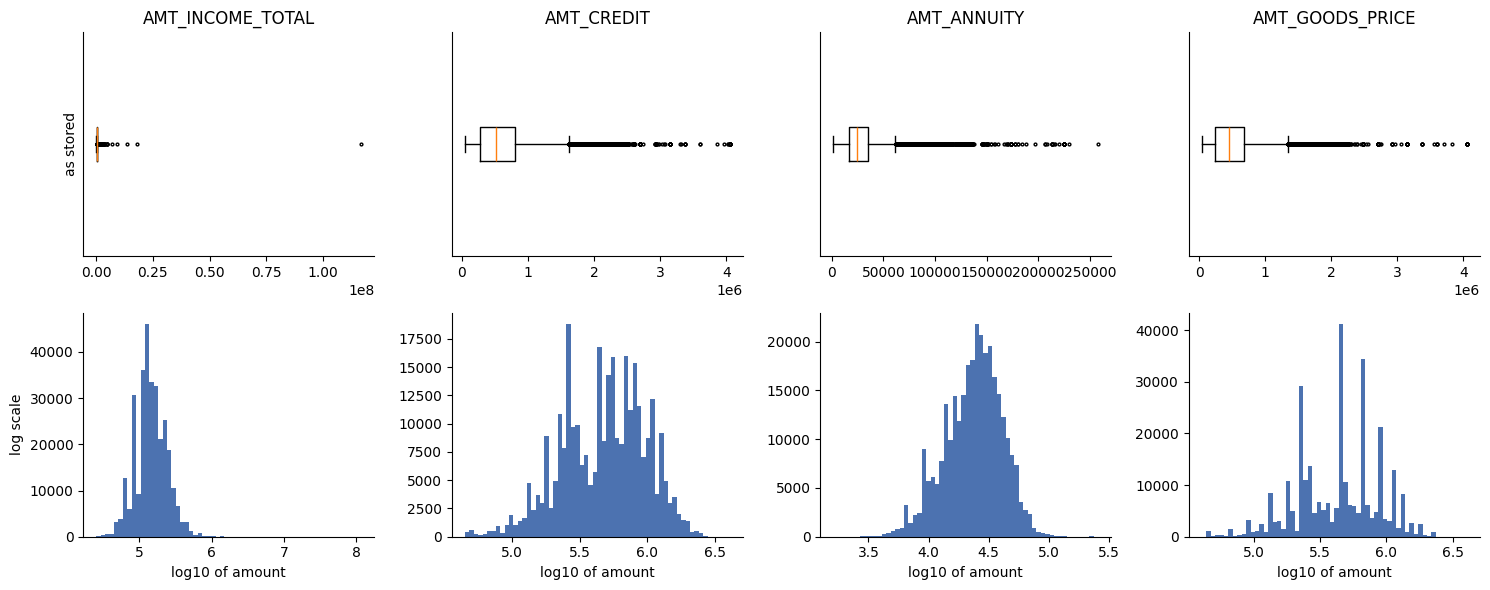

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for i, c in enumerate(['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']):
    axes[0, i].boxplot(app[c].dropna(), vert=False, flierprops={'markersize': 2})
    axes[0, i].set_title(c)
    axes[0, i].set_yticks([])
    axes[1, i].hist(np.log10(app[c].dropna()), bins=60, color='#4C72B0')
    axes[1, i].set_xlabel('log10 of amount')
axes[0, 0].set_ylabel('as stored')
axes[1, 0].set_ylabel('log scale')
sns.despine()
plt.tight_layout()
plt.show()

### 4.5 Cleaning rules, applied

The rules from this stage as one function, so the identical cleaning can be applied to `application_test.csv`. Thresholds are fixed constants, not percentiles of the data, so train and test are treated the same way. The raw `app` is left untouched and the later stages use `app_clean`.

In [42]:
# values above these limits are isolated single rows (section 4.1) and are treated as entry errors
OUTLIER_LIMITS = {
    'AMT_INCOME_TOTAL': 20_000_000,
    'OBS_30_CNT_SOCIAL_CIRCLE': 100,
    'OBS_60_CNT_SOCIAL_CIRCLE': 100,
    'DEF_30_CNT_SOCIAL_CIRCLE': 20,
    'DEF_60_CNT_SOCIAL_CIRCLE': 20,
    'AMT_REQ_CREDIT_BUREAU_QRT': 100,
}

def clean_application(df):
    df = df.copy()
    # placeholders that stand for a missing value
    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
    df['CODE_GENDER'] = df['CODE_GENDER'].replace('XNA', np.nan)
    df['NAME_FAMILY_STATUS'] = df['NAME_FAMILY_STATUS'].replace('Unknown', np.nan)
    # isolated extreme values
    for col, limit in OUTLIER_LIMITS.items():
        df[col] = df[col].where(~(df[col] > limit))
    return df

app_clean = clean_application(app)

# are the social circle outliers one applicant?
social = groups['social_circle']
odd = (app[social] > pd.Series(OUTLIER_LIMITS)[social]).any(axis=1)
display(app.loc[odd, ['SK_ID_CURR', 'TARGET'] + social])

changes = pd.DataFrame({
    'missing_before': app.isna().sum(),
    'missing_after': app_clean.isna().sum(),
})
changes['cells_set_to_missing'] = changes['missing_after'] - changes['missing_before']
print(changes[changes['cells_set_to_missing'] > 0])
print(f"\nrows: {len(app):,} before, {len(app_clean):,} after")
print(f"income skew: {app['AMT_INCOME_TOTAL'].skew():.1f} before, {app_clean['AMT_INCOME_TOTAL'].skew():.1f} after, "
      f"{np.log1p(app_clean['AMT_INCOME_TOTAL']).skew():.2f} after log")

,SK_ID_CURR,TARGET,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE
148403,272071,0,348.0,34.0,344.0,24.0


                           missing_before  missing_after  cells_set_to_missing
CODE_GENDER                             0              4                     4
AMT_INCOME_TOTAL                        0              1                     1
NAME_FAMILY_STATUS                      0              2                     2
DAYS_EMPLOYED                           0          55374                 55374
OBS_30_CNT_SOCIAL_CIRCLE             1021           1022                     1
DEF_30_CNT_SOCIAL_CIRCLE             1021           1022                     1
OBS_60_CNT_SOCIAL_CIRCLE             1021           1022                     1
DEF_60_CNT_SOCIAL_CIRCLE             1021           1022                     1
AMT_REQ_CREDIT_BUREAU_QRT           41519          41520                     1

rows: 307,511 before, 307,511 after
income skew: 391.6 before, 27.0 after, 0.16 after log


### Stage 4 findings

**Numeric placeholder**
- `DAYS_EMPLOYED = 365243` on 55,374 rows (18.0%). It is the only numeric placeholder in the table, and there are no other positive values in that column.
- It marks applicants with no current employer: 55,352 pensioners and all 22 unemployed. On those rows `ORGANIZATION_TYPE` is always `XNA`, `OCCUPATION_TYPE` is always missing and `FLAG_EMP_PHONE` is always 0.
- These applicants default at 5.40% against 8.66% for everyone else, so the fact of having no employer is informative and must survive cleaning. `FLAG_EMP_PHONE` and `ORGANIZATION_TYPE = XNA` already carry it.

**Text placeholders**
- `ORGANIZATION_TYPE = XNA` (55,374 rows), `FONDKAPREMONT_MODE = not specified` (5,687), `CODE_GENDER = XNA` (4), `NAME_FAMILY_STATUS = Unknown` (2).
- Counting placeholders as missing, 71 columns have gaps instead of 67, and `DAYS_EMPLOYED` and `ORGANIZATION_TYPE` go from 0% to 18.0% missing.

**Impossible and inconsistent values**
- The table is internally consistent. Of 31 checks, 26 have no violations: no positive day counts, no one employed longer than they have been alive, family size always equals children plus one or two adults, social circle defaults never exceed observations, normalised columns stay within 0 to 1.
- The only true inconsistencies are 1 row with a registration change dated before birth and 5 car owners with no car age.
- `OWN_CAR_AGE` has a spike of 3,334 rows at 64 and 65 years, against a handful of rows for any age from 50 to 63. This looks like a default value for an unknown car age, though it is not documented.
- `DAYS_LAST_PHONE_CHANGE = 0` on 37,672 rows (12.3%), more than ten times the next most common value. Those applicants default at 9.67% against 7.85%. It may mean a phone changed on the application day or an unknown date. Either way it carries signal.

**Extreme outliers**
- Six columns have a single value far outside everything else: `AMT_INCOME_TOTAL` at 117 million (next highest 18 million), `AMT_REQ_CREDIT_BUREAU_QRT` at 261 (next 19), and the four social circle counts at 348, 344, 34 and 24 (next 47, 47, 8 and 7).
- The four social circle values belong to one applicant. The 117 million income belongs to a laborer borrowing 562,491.
- Income skew falls from 392 to 27 once that one row is removed, and to 0.16 after a log transform. The four amount columns are all right-skewed and close to symmetric on a log scale.
- The large family counts (up to 19 children) are consistent with the family member counts on the same rows, so they are kept.

**Cleaning rules** (implemented in `clean_application`)

| Issue | Rule | Cells affected |
|---|---|---:|
| `DAYS_EMPLOYED = 365243` | Set to missing | 55,374 |
| `CODE_GENDER = XNA` | Set to missing | 4 |
| `NAME_FAMILY_STATUS = Unknown` | Set to missing | 2 |
| `AMT_INCOME_TOTAL` above 20 million | Set to missing | 1 |
| Social circle counts above 100 (observed) or 20 (defaulted) | Set to missing | 4 |
| `AMT_REQ_CREDIT_BUREAU_QRT` above 100 | Set to missing | 1 |
| `ORGANIZATION_TYPE = XNA` | Keep as a category. It means "no employer", which is a real answer | 0 |
| `FONDKAPREMONT_MODE = not specified` | Keep as a category. Its default rate (7.5%) differs from truly missing rows (8.6%) | 0 |
| `OWN_CAR_AGE` of 64 or 65 | Keep. Flag it as a feature in stage 11 | 0 |
| `DAYS_LAST_PHONE_CHANGE = 0` | Keep. Flag it as a feature in stage 11 | 0 |
| Large family counts | Keep | 0 |

- No rows are dropped. The table stays at 307,511 rows, and the same function can be applied to test.
- The outlier rules touch 3 applicants out of 307,511. They matter for ratio features and linear models, not for tree models on the raw columns.
- Skewed amounts are left as they are here. Log transforms are a modelling step, needed for linear models and not for trees.

## Stage 5: Numeric features

Distributions, skew, outliers, and default rate across bins. Uses `app_clean` from stage 4.

There are 72 non-binary numeric columns: 29 outside the building block (the "core" columns) and 43 inside it. The core columns get full treatment. The building block is summarised, since its columns are near-duplicates of each other (stage 9 covers that).

In [43]:
core_num = [c for c in numeric_cols if col_info.loc[c, 'group'] != 'building']
building_num = [c for c in numeric_cols if col_info.loc[c, 'group'] == 'building']
core_continuous = [c for c in core_num if col_info.loc[c, 'semantic_type'] == 'continuous']
core_discrete = [c for c in core_num if col_info.loc[c, 'semantic_type'] == 'discrete']
print(len(core_num), 'core columns:', len(core_continuous), 'continuous,', len(core_discrete), 'discrete')
print(len(building_num), 'building columns')

def readable(col, s):
    # DAYS_ columns are negative day counts; show them as positive years
    if col.startswith('DAYS_'):
        return -s / 365.25, f"{col} (years before application)"
    return s, col

29 core columns: 14 continuous, 15 discrete
43 building columns


### 5.1 Summary statistics

In [44]:
def summarise(cols):
    d = app_clean[cols]
    out = d.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T.drop(columns='count')
    out['skew'] = d.skew()
    out['kurtosis'] = d.kurt()
    out['zeros_pct'] = (d == 0).mean() * 100
    out['n_unique'] = d.nunique()
    out['missing_pct'] = d.isna().mean() * 100
    return out

core_stats = summarise(core_num)
core_stats.round(3)

,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,zeros_pct,n_unique,missing_pct
CNT_CHILDREN,0.417,0.722,0.000,0.000,0.000,0.000,1.000,3.000,1.900000e+01,1.975,7.904,70.037,15,0.000
AMT_INCOME_TOTAL,168417.993,108811.807,25650.000,45000.000,112500.000,147150.000,202500.000,472500.000,1.800009e+07,26.976,3343.780,0.000,2547,0.000
AMT_CREDIT,599026.000,402490.777,45000.000,76410.000,270000.000,513531.000,808650.000,1854000.000,4.050000e+06,1.235,1.934,0.000,5603,0.000
AMT_ANNUITY,27108.574,14493.737,1615.500,6182.910,16524.000,24903.000,34596.000,70006.500,2.580255e+05,1.580,7.707,0.000,13672,0.004
AMT_GOODS_PRICE,538396.207,369446.461,40500.000,67500.000,238500.000,450000.000,679500.000,1800000.000,4.050000e+06,1.349,2.432,0.000,1002,0.090
REGION_POPULATION_RELATIVE,0.021,0.014,0.000,0.002,0.010,0.019,0.029,0.073,7.300000e-02,1.488,3.260,0.000,81,0.000
DAYS_BIRTH,-16036.995,4363.989,-25229.000,-24419.000,-19682.000,-15750.000,-12413.000,-8263.000,-7.489000e+03,-0.116,-1.049,0.000,17460,0.000
DAYS_EMPLOYED,-2384.169,2338.360,-17912.000,-11338.280,-3175.000,-1648.000,-767.000,-111.000,0.000000e+00,-1.968,4.753,0.001,12573,18.007
DAYS_REGISTRATION,-4986.120,3522.886,-24672.000,-13879.000,-7479.500,-4504.000,-2010.000,-50.000,0.000000e+00,-0.591,-0.321,0.026,15688,0.000
DAYS_ID_PUBLISH,-2994.202,1509.450,-7197.000,-5447.000,-4299.000,-3254.000,-1720.000,-61.000,0.000000e+00,0.349,-1.107,0.005,6168,0.000


In [45]:
# building block, one row per measure (the _AVG version)
avg_cols = [c for c in building_num if c.endswith('_AVG')] + ['TOTALAREA_MODE']
building_stats = summarise(avg_cols)[['min', '50%', 'mean', 'max', 'skew', 'zeros_pct', 'missing_pct']]
building_stats['ones_pct'] = (app_clean[avg_cols] == 1).mean() * 100
building_stats.round(3)

,min,50%,mean,max,skew,zeros_pct,missing_pct,ones_pct
APARTMENTS_AVG,0.0,0.088,0.117,1.0,2.642,0.244,50.750,0.048
BASEMENTAREA_AVG,0.0,0.076,0.088,1.0,3.566,4.795,58.516,0.042
YEARS_BEGINEXPLUATATION_AVG,0.0,0.982,0.978,1.0,-15.515,0.167,48.781,0.060
YEARS_BUILD_AVG,0.0,0.755,0.752,1.0,-0.962,0.033,66.498,0.056
COMMONAREA_AVG,0.0,0.021,0.045,1.0,5.457,2.745,69.872,0.030
ELEVATORS_AVG,0.0,0.000,0.079,1.0,2.439,27.875,53.296,0.051
ENTRANCES_AVG,0.0,0.138,0.150,1.0,2.400,0.105,50.349,0.050
FLOORSMAX_AVG,0.0,0.167,0.226,1.0,1.226,0.955,49.761,0.054
FLOORSMIN_AVG,0.0,0.208,0.232,1.0,0.954,0.754,67.849,0.046
LANDAREA_AVG,0.0,0.048,0.066,1.0,4.459,5.073,59.377,0.044


### 5.2 Distributions, split by target

Each panel shows the share of applicants at each value, drawn separately for repaid loans and defaults. Where the two lines differ, the column separates the classes. Amounts are on a log scale.

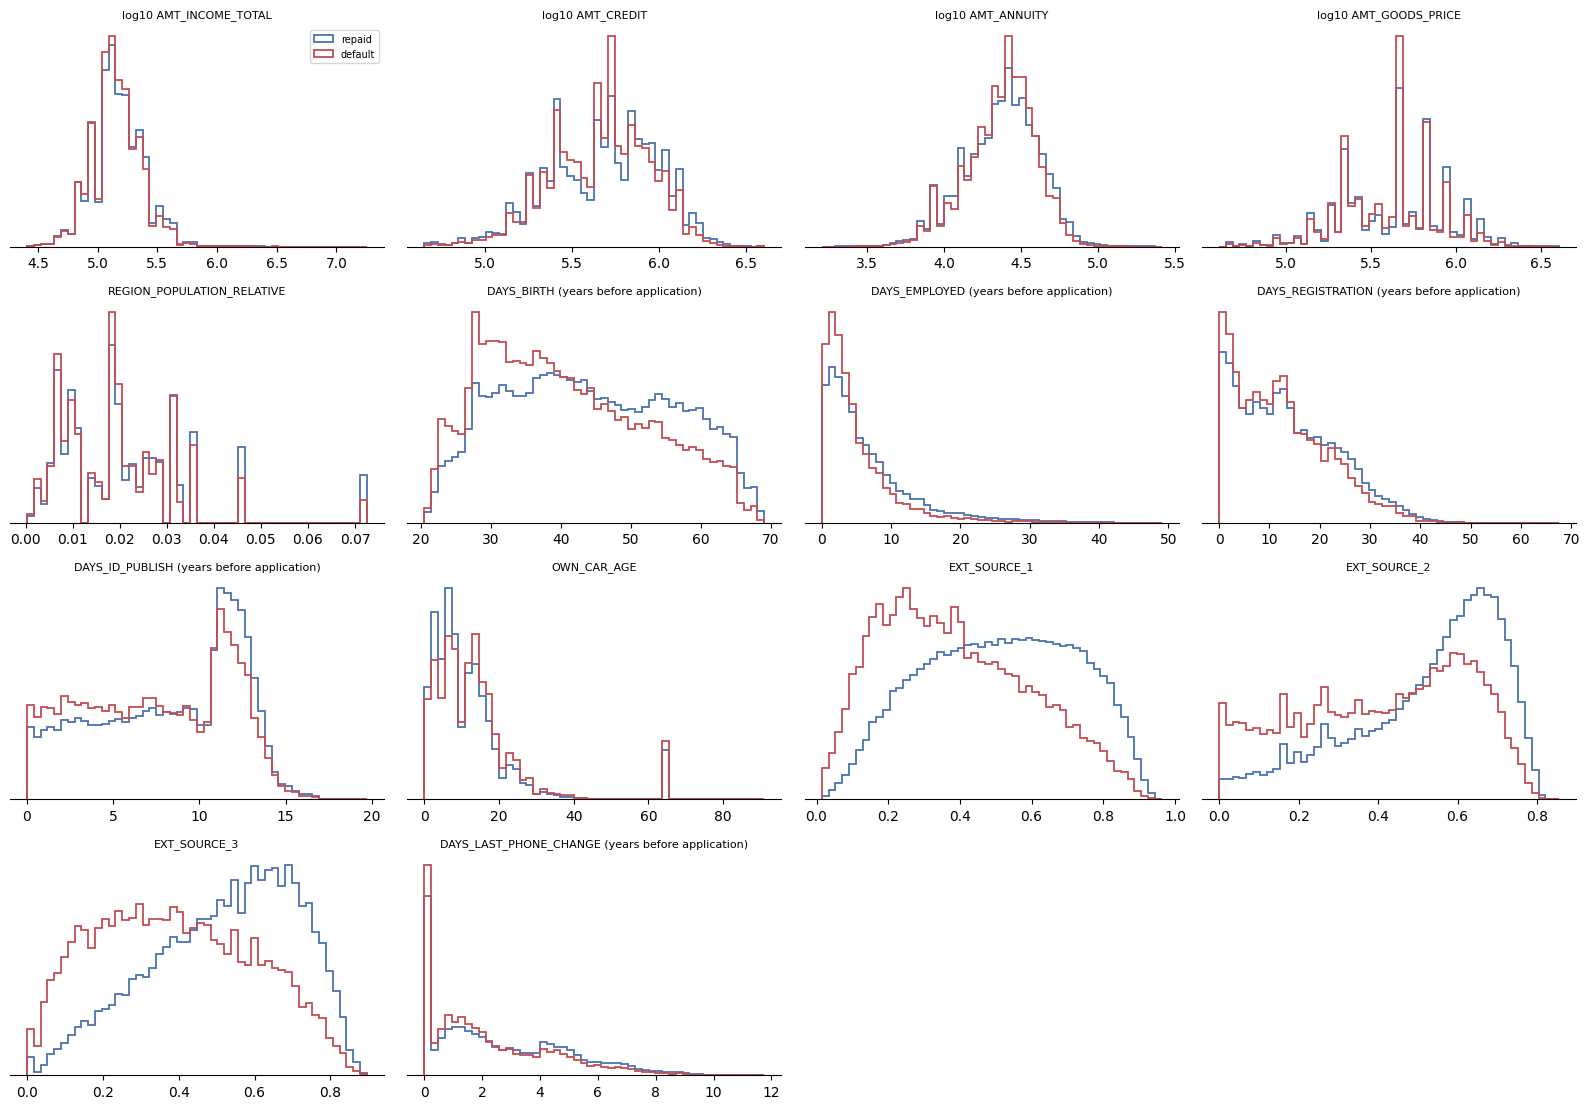

In [46]:
def plot_density_by_target(cols, ncols=4, log_cols=()):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows))
    for ax, c in zip(axes.ravel(), cols):
        s, label = readable(c, app_clean[c])
        if c in log_cols:
            s, label = np.log10(s), f"log10 {c}"
        edges = np.histogram_bin_edges(s.dropna(), bins=50)
        for target, color, name in [(0, '#4C72B0', 'repaid'), (1, '#C44E52', 'default')]:
            ax.hist(s[y == target].dropna(), bins=edges, density=True, histtype='step', color=color, linewidth=1.3, label=name)
        ax.set_title(label, fontsize=8)
        ax.set_yticks([])
    for ax in axes.ravel()[len(cols):]:
        ax.axis('off')
    axes.ravel()[0].legend(fontsize=7)
    sns.despine(left=True)
    plt.tight_layout()
    plt.show()

amounts = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
plot_density_by_target(core_continuous, log_cols=amounts)

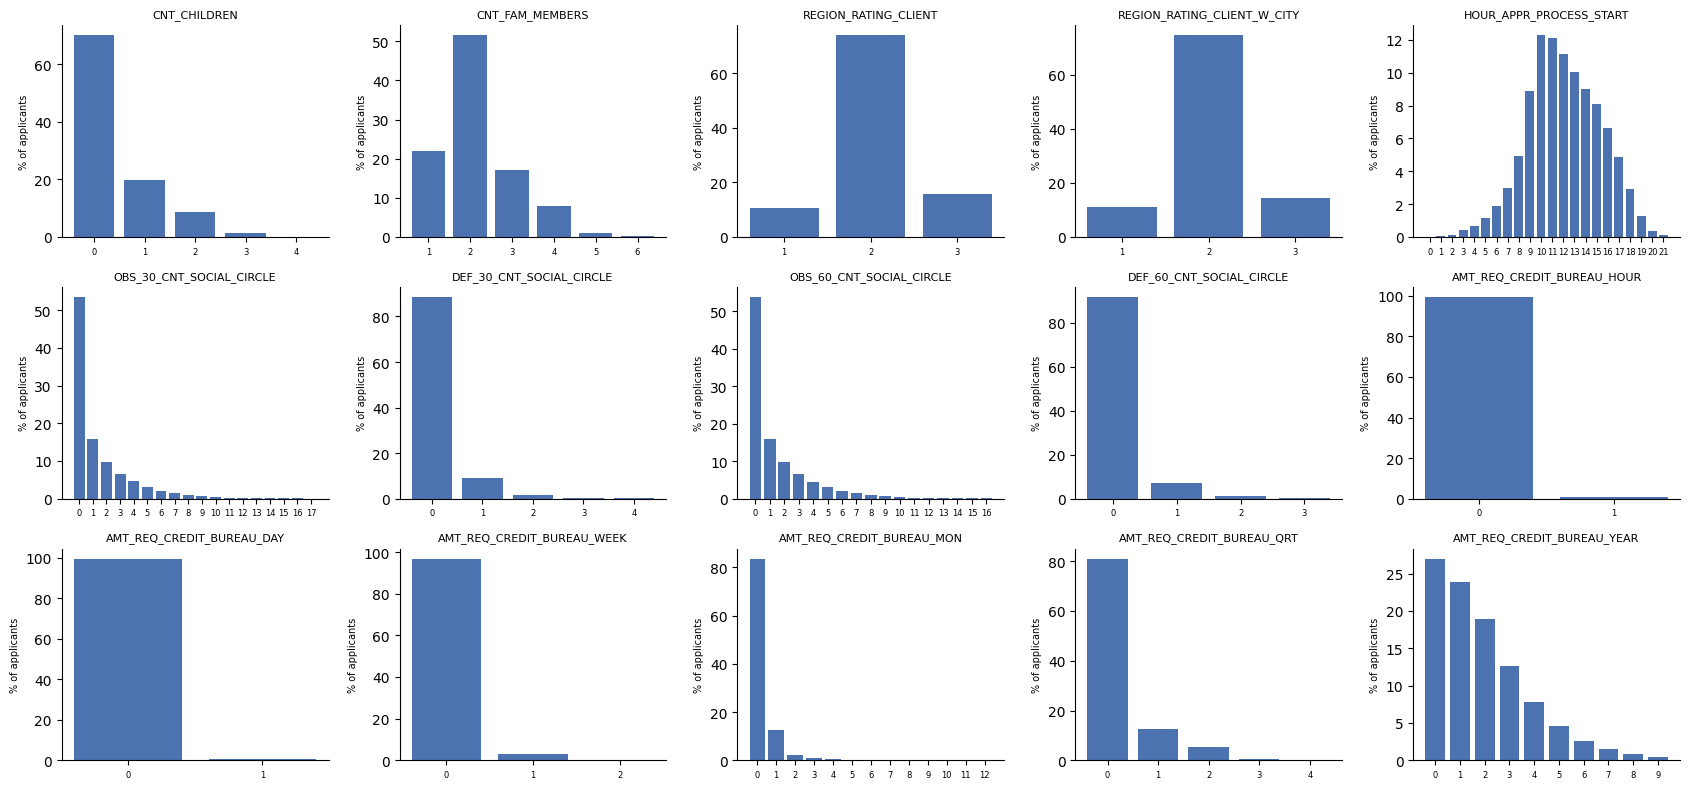

In [47]:
# discrete columns: share of applicants at each value
fig, axes = plt.subplots(3, 5, figsize=(17, 8))
for ax, c in zip(axes.ravel(), core_discrete):
    shares = app_clean[c].value_counts(normalize=True).sort_index() * 100
    shares = shares[shares.index <= shares.index[shares.cumsum() >= 99.9][0]]
    ax.bar(shares.index.astype(int).astype(str), shares.values, color='#4C72B0')
    ax.set_title(c, fontsize=8)
    ax.tick_params(axis='x', labelsize=6)
    ax.set_ylabel('% of applicants', fontsize=7)
for ax in axes.ravel()[len(core_discrete):]:
    ax.axis('off')
sns.despine()
plt.tight_layout()
plt.show()

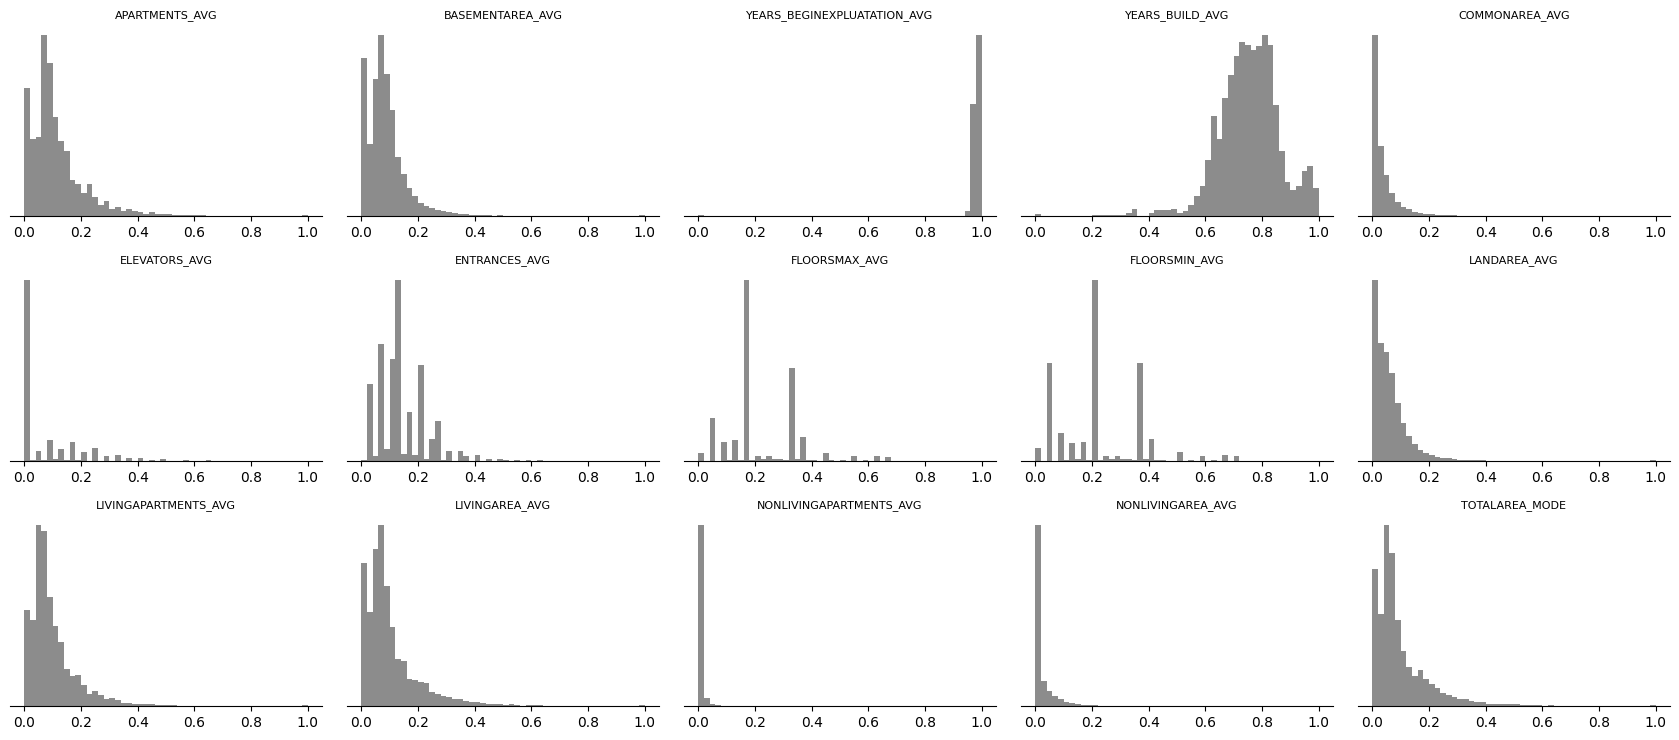

In [48]:
# building block: the 14 measures plus total area
fig, axes = plt.subplots(3, 5, figsize=(17, 7.5))
for ax, c in zip(axes.ravel(), avg_cols):
    ax.hist(app_clean[c].dropna(), bins=50, color='#8C8C8C')
    ax.set_title(c, fontsize=8)
    ax.set_yticks([])
sns.despine(left=True)
plt.tight_layout()
plt.show()

### 5.3 Skew and transforms

Skew above 1 or below -1 is strong. For the right-skewed columns the table shows skew again after a `log1p` transform.

In [49]:
skew = pd.DataFrame({'skew': app_clean[core_num].skew()})
right_skewed = skew.index[(skew['skew'] > 1) & (app_clean[core_num].min() >= 0)]
skew['skew_after_log1p'] = np.log1p(app_clean[right_skewed]).skew()
skew['zeros_pct'] = (app_clean[core_num] == 0).mean() * 100
skew.sort_values('skew', key=abs, ascending=False).round(2)

,skew,skew_after_log1p,zeros_pct
AMT_REQ_CREDIT_BUREAU_DAY,27.04,15.86,86.01
AMT_INCOME_TOTAL,26.98,0.16,0.00
AMT_REQ_CREDIT_BUREAU_HOUR,14.53,13.13,85.97
AMT_REQ_CREDIT_BUREAU_WEEK,9.29,5.80,83.72
AMT_REQ_CREDIT_BUREAU_MON,7.80,2.93,72.27
DEF_60_CNT_SOCIAL_CIRCLE,4.44,3.40,91.29
DEF_30_CNT_SOCIAL_CIRCLE,3.87,2.84,88.23
AMT_REQ_CREDIT_BUREAU_QRT,2.76,1.94,70.05
OWN_CAR_AGE,2.75,-0.30,0.69
OBS_60_CNT_SOCIAL_CIRCLE,2.60,0.91,53.55


### 5.4 Outliers after cleaning

`outside_iqr_pct` is the share of rows beyond 1.5 interquartile ranges from the quartiles. The last three columns compare the default rate in the top 1% of each column against the rest.

In [50]:
rows = []
for c in core_num:
    s = app_clean[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    p99 = s.quantile(0.99)
    top = app_clean[c] > p99
    rows.append({
        'column': c,
        'outside_iqr_pct': ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100,
        'p99': p99,
        'max': s.max(),
        'rows_above_p99': int(top.sum()),
        'default_pct_above_p99': y[top].mean() * 100 if top.sum() else np.nan,
        'default_pct_rest': y[~top & app_clean[c].notna()].mean() * 100,
    })
pd.DataFrame(rows).set_index('column').sort_values('outside_iqr_pct', ascending=False).round(2)

,outside_iqr_pct,p99,max,rows_above_p99,default_pct_above_p99,default_pct_rest
column,,,,,,
REGION_RATING_CLIENT,26.19,3.00,3.00,0,NaN,8.07
REGION_RATING_CLIENT_W_CITY,25.37,3.00,3.00,0,NaN,8.07
AMT_REQ_CREDIT_BUREAU_QRT,19.01,2.00,19.00,2300,8.61,7.71
AMT_REQ_CREDIT_BUREAU_MON,16.45,4.00,27.00,2159,5.14,7.74
DEF_30_CNT_SOCIAL_CIRCLE,11.47,2.00,8.00,1514,13.01,8.06
DEF_60_CNT_SOCIAL_CIRCLE,8.41,2.00,7.00,757,14.93,8.07
OBS_30_CNT_SOCIAL_CIRCLE,6.52,10.00,47.00,2781,9.10,8.08
OBS_60_CNT_SOCIAL_CIRCLE,6.38,10.00,47.00,2690,8.92,8.08
DAYS_EMPLOYED,6.01,-111.00,0.00,2511,10.91,8.64


### 5.5 Default rate across bins

Continuous columns are cut into ten equal-sized bins. Discrete columns are grouped by value, with sparse values at either end merged until each group has at least 500 rows. `shape` says whether the default rate moves in one direction across the bins. `auc` is the ROC AUC of the column used alone as a score, on the rows where it is present.

In [51]:
from scipy.stats import spearmanr

def rate_by_bin(col, q=10, min_rows=500):
    s = app_clean[col]
    if col_info.loc[col, 'semantic_type'] == 'discrete':
        counts = s.dropna().value_counts().sort_index()
        upper = counts[counts[::-1].cumsum()[::-1] >= min_rows].index.max()
        lower = counts[counts.cumsum() >= min_rows].index.min()
        keys = s.clip(lower=lower, upper=upper)
    else:
        keys = pd.qcut(s, q, duplicates='drop')
    out = y.groupby(keys, observed=True).agg(rows='size', default_pct='mean')
    out['default_pct'] *= 100
    out['x'] = s.groupby(keys, observed=True).median().values
    return out.reset_index(drop=True)

def summarise_rates(cols):
    rows = []
    for c in cols:
        t = rate_by_bin(c)
        present = app_clean[c].notna()
        auc = roc_auc_score(y[present], app_clean.loc[present, c])
        rho = spearmanr(t['x'], t['default_pct'])[0] if len(t) >= 3 else np.nan
        shape = 'too few values' if np.isnan(rho) else 'rising' if rho >= 0.9 else 'falling' if rho <= -0.9 else 'not monotonic'
        rows.append({
            'column': c, 'bins': len(t),
            'lowest_bin_pct': t['default_pct'].min(), 'highest_bin_pct': t['default_pct'].max(),
            'spread_pts': t['default_pct'].max() - t['default_pct'].min(),
            'rank_corr': rho, 'shape': shape,
            'auc': max(auc, 1 - auc),
            'higher_value_means': 'more default' if auc > 0.5 else 'less default',
            'default_pct_when_missing': y[~present].mean() * 100 if (~present).sum() >= 500 else np.nan,
        })
    return pd.DataFrame(rows).set_index('column')

core_rates = summarise_rates(core_num).sort_values('spread_pts', ascending=False)
core_rates.round(3)

,bins,lowest_bin_pct,highest_bin_pct,spread_pts,rank_corr,shape,auc,higher_value_means,default_pct_when_missing
column,,,,,,,,,
EXT_SOURCE_3,10,3.228,20.003,16.776,-1.000,falling,0.679,less default,9.312
EXT_SOURCE_2,10,2.972,18.350,15.378,-1.000,falling,0.656,less default,7.879
EXT_SOURCE_1,10,2.572,17.564,14.992,-1.000,falling,0.666,less default,8.520
AMT_GOODS_PRICE,10,4.911,13.272,8.361,-0.588,not monotonic,0.533,less default,NaN
DEF_60_CNT_SOCIAL_CIRCLE,4,7.835,14.927,7.093,1.000,rising,0.516,more default,3.523
DAYS_EMPLOYED,10,4.559,11.467,6.908,0.964,rising,0.582,more default,5.400
DAYS_BIRTH,10,4.903,11.581,6.678,1.000,rising,0.583,more default,NaN
REGION_RATING_CLIENT_W_CITY,3,4.841,11.402,6.561,1.000,rising,0.549,more default,NaN
REGION_RATING_CLIENT,3,4.820,11.103,6.283,1.000,rising,0.548,more default,NaN


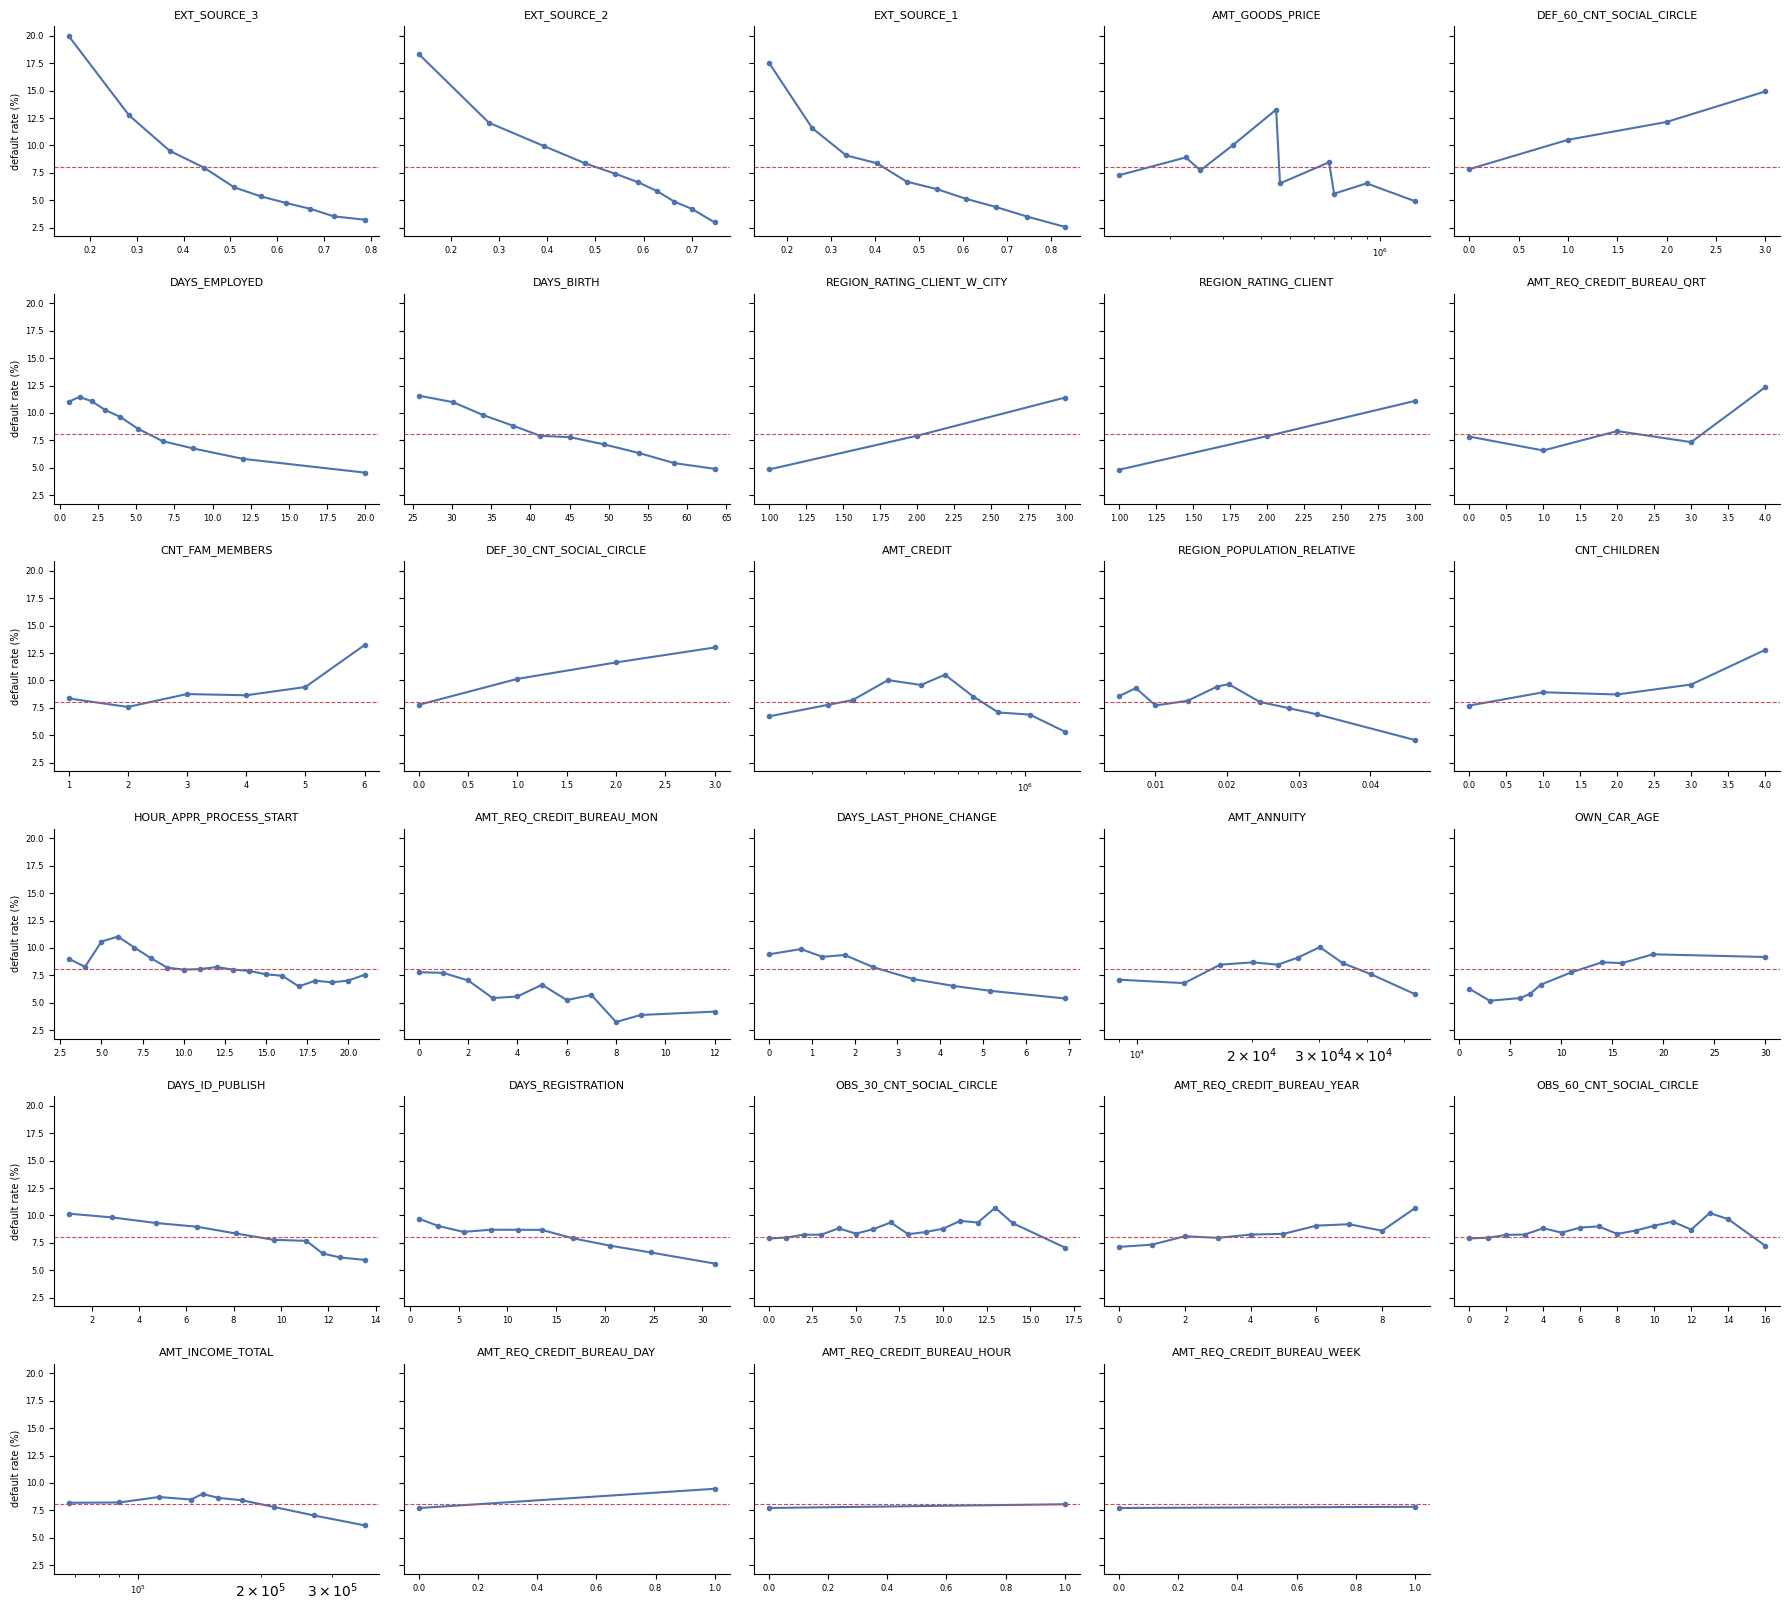

In [52]:
def plot_rate_grid(cols, ncols=5):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.7 * nrows), sharey=True)
    for ax, c in zip(axes.ravel(), cols):
        t = rate_by_bin(c)
        x, label = readable(c, t['x'])
        ax.plot(x, t['default_pct'], marker='o', markersize=3, color='#4C72B0')
        ax.axhline(default_rate * 100, color='#C44E52', linestyle='--', linewidth=0.8)
        ax.set_title(c, fontsize=8)
        ax.tick_params(labelsize=6)
        if c in amounts:
            ax.set_xscale('log')
    for ax in axes.ravel()[len(cols):]:
        ax.axis('off')
    for ax in axes[:, 0]:
        ax.set_ylabel('default rate (%)', fontsize=7)
    sns.despine()
    plt.tight_layout()
    plt.show()

# ordered from the widest spread to the narrowest; the dashed line is the overall default rate
plot_rate_grid(core_rates.index.tolist())

In [53]:
# the bin tables behind the most important panels
for c in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
          'AMT_CREDIT', 'AMT_GOODS_PRICE', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'DAYS_LAST_PHONE_CHANGE']:
    t = rate_by_bin(c)
    x, label = readable(c, t['x'])
    print(label)
    print('  bin median: ', np.round(x.values, 2).tolist())
    print('  default %:  ', t['default_pct'].round(1).tolist())

EXT_SOURCE_1
  bin median:  [0.16, 0.26, 0.33, 0.4, 0.47, 0.54, 0.61, 0.68, 0.75, 0.83]
  default %:   [17.6, 11.6, 9.1, 8.4, 6.7, 6.0, 5.1, 4.4, 3.5, 2.6]
EXT_SOURCE_2
  bin median:  [0.13, 0.28, 0.39, 0.48, 0.54, 0.59, 0.63, 0.66, 0.7, 0.75]
  default %:   [18.4, 12.1, 10.0, 8.4, 7.4, 6.7, 5.8, 4.9, 4.2, 3.0]
EXT_SOURCE_3
  bin median:  [0.15, 0.28, 0.37, 0.44, 0.51, 0.57, 0.62, 0.67, 0.72, 0.79]
  default %:   [20.0, 12.8, 9.5, 8.0, 6.2, 5.3, 4.7, 4.2, 3.5, 3.2]
DAYS_BIRTH (years before application)
  bin median:  [63.53, 58.36, 53.88, 49.38, 45.07, 41.26, 37.74, 33.98, 30.13, 25.75]
  default %:   [4.9, 5.4, 6.3, 7.1, 7.8, 7.9, 8.9, 9.8, 11.0, 11.6]
DAYS_EMPLOYED (years before application)
  bin median:  [19.96, 11.97, 8.69, 6.73, 5.12, 3.95, 2.95, 2.1, 1.28, 0.56]
  default %:   [4.6, 5.8, 6.8, 7.4, 8.6, 9.6, 10.3, 11.1, 11.5, 11.0]


AMT_CREDIT
  bin median:  [143910.0, 225000.0, 271066.5, 354276.0, 454500.0, 545040.0, 675000.0, 816660.0, 1035832.5, 1350000.0]
  default %:   [6.7, 7.8, 8.2, 10.0, 9.6, 10.5, 8.5, 7.1, 6.9, 5.3]
AMT_GOODS_PRICE
  bin median:  [135000.0, 225000.0, 252000.0, 324000.0, 450000.0, 463500.0, 675000.0, 702000.0, 900000.0, 1305000.0]
  default %:   [7.3, 8.9, 7.7, 10.1, 13.3, 6.5, 8.5, 5.6, 6.5, 4.9]
AMT_ANNUITY
  bin median:  [9000.0, 13315.5, 16524.0, 20151.0, 23355.0, 26320.5, 30082.5, 34596.0, 40817.25, 53329.5]
  default %:   [7.1, 6.8, 8.5, 8.7, 8.5, 9.1, 10.1, 8.6, 7.6, 5.8]
AMT_INCOME_TOTAL
  bin median:  [67500.0, 90000.0, 112500.0, 135000.0, 144000.0, 157500.0, 180000.0, 216000.0, 270000.0, 360000.0]
  default %:   [8.2, 8.2, 8.7, 8.5, 9.0, 8.6, 8.4, 7.8, 7.0, 6.1]


DAYS_LAST_PHONE_CHANGE (years before application)
  bin median:  [6.9, 5.17, 4.3, 3.36, 2.44, 1.77, 1.25, 0.75, -0.0]
  default %:   [5.4, 6.1, 6.5, 7.2, 8.2, 9.4, 9.2, 9.9, 9.4]


In [54]:
# age and time in job in round bands
age_years = -app_clean['DAYS_BIRTH'] / 365.25
job_years = -app_clean['DAYS_EMPLOYED'] / 365.25

age_table = y.groupby(pd.cut(age_years, [20, 25, 30, 35, 40, 45, 50, 55, 60, 70]), observed=True).agg(rows='size', default_pct='mean')
age_table['default_pct'] = (age_table['default_pct'] * 100).round(2)
print(age_table)

job_table = y.groupby(pd.cut(job_years, [0, 1, 2, 3, 5, 8, 12, 20, 50], include_lowest=True), observed=True).agg(rows='size', default_pct='mean')
job_table['default_pct'] = (job_table['default_pct'] * 100).round(2)
job_table.loc['no employer (missing)'] = [job_years.isna().sum(), round(y[job_years.isna()].mean() * 100, 2)]
print()
print(job_table)

             rows  default_pct
DAYS_BIRTH                    
(20, 25]    12233        12.29
(25, 30]    32953        11.13
(30, 35]    39476        10.27
(35, 40]    42873         8.96
(40, 45]    41388         7.83
(45, 50]    35193         7.42
(50, 55]    34997         6.67
(55, 60]    33112         5.54
(60, 70]    35286         4.92

                          rows  default_pct
DAYS_EMPLOYED                              
(-0.001, 1.0]          27982.0        10.97
(1.0, 2.0]             31845.0        11.41
(2.0, 3.0]             29627.0        10.72
(3.0, 5.0]             46902.0         9.67
(5.0, 8.0]             44474.0         7.72
(8.0, 12.0]            33651.0         6.39
(12.0, 20.0]           25127.0         5.24
(20.0, 50.0]           12529.0         4.18
no employer (missing)  55374.0         5.40


In [55]:
# building block: default rate across bins for every numeric building column
building_rates = summarise_rates(building_num).sort_values('spread_pts', ascending=False)
print(building_rates['shape'].value_counts().to_string())
print(f"\nspread across bins: median {building_rates['spread_pts'].median():.2f} pts, max {building_rates['spread_pts'].max():.2f} pts")
print(f"auc: median {building_rates['auc'].median():.3f}, max {building_rates['auc'].max():.3f}")
building_rates.head(12).round(3)

shape
not monotonic    22
falling          21

spread across bins: median 2.76 pts, max 4.35 pts
auc: median 0.531, max 0.550


,bins,lowest_bin_pct,highest_bin_pct,spread_pts,rank_corr,shape,auc,higher_value_means,default_pct_when_missing
column,,,,,,,,,
FLOORSMAX_AVG,6,4.880,9.230,4.350,-1.000,falling,0.550,less default,9.191
FLOORSMAX_MEDI,6,4.869,9.207,4.338,-1.000,falling,0.550,less default,9.191
FLOORSMAX_MODE,6,4.822,9.153,4.331,-1.000,falling,0.549,less default,9.191
FLOORSMIN_MODE,7,4.618,8.933,4.315,-0.679,not monotonic,0.534,less default,8.631
FLOORSMIN_MEDI,7,4.703,8.686,3.983,-0.679,not monotonic,0.535,less default,8.631
LIVINGAREA_AVG,10,5.483,9.230,3.747,-0.988,falling,0.547,less default,9.142
TOTALAREA_MODE,10,5.415,9.158,3.743,-0.879,not monotonic,0.545,less default,9.234
FLOORSMIN_AVG,7,4.899,8.551,3.652,-0.786,not monotonic,0.536,less default,8.631
LIVINGAREA_MEDI,10,5.530,9.164,3.634,-1.000,falling,0.547,less default,9.142


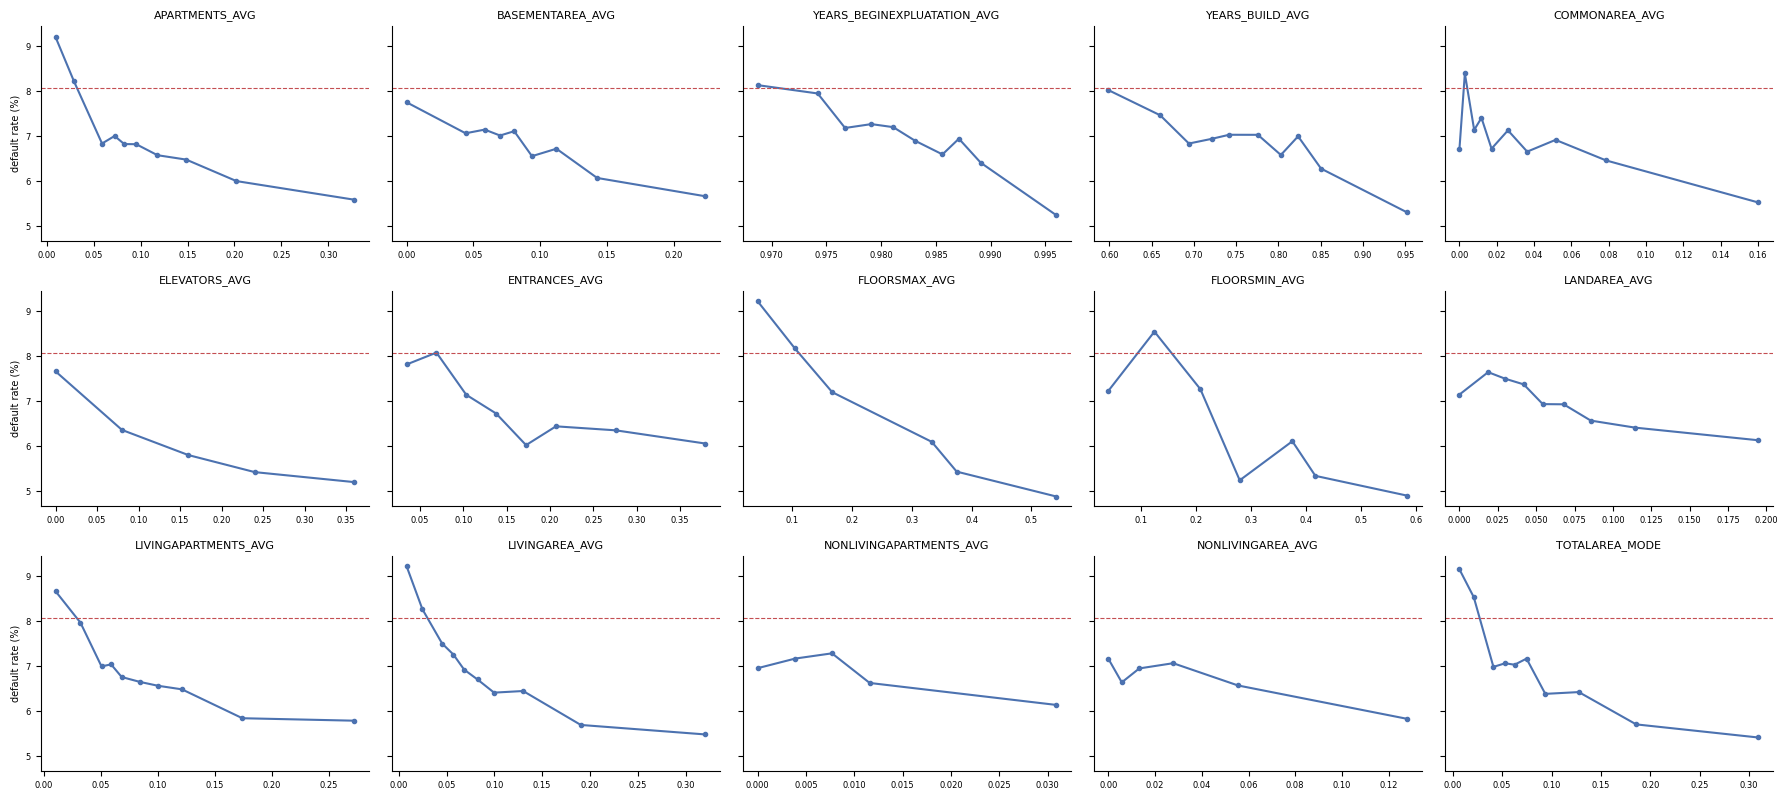

In [56]:
plot_rate_grid(avg_cols)

### Stage 5 findings

**Distributions**
- The four amount columns are right-skewed (skew 1.2 to 1.6, income 27 even after cleaning) and close to symmetric on a log scale (skew between -0.35 and 0.16 after `log1p`).
- The three external scores, age, and the registration and ID dates are roughly symmetric and need no transform.
- The count columns are dominated by zeros: 84% to 86% zeros for the hourly, daily and weekly bureau enquiries, 88% to 91% for the social circle default counts, 70% for children. A log transform does not fix these (skew stays between 3 and 16).
- Building columns are right-skewed with a long tail to 1, and several have a spike at exactly 0 (28% of elevator values, 18% to 19% of the non-living measures).

**Outliers after cleaning**
- The remaining extremes are real applicants, not errors, and they behave differently. The top 1% by credit, annuity, goods price or income default at 3.4% to 5.3%, against 8.1% for the rest.
- The top 1% by number of children or family members default at about 13%.
- The 1.5 IQR rule is not usable here. It flags 26% of the region ratings and 19% of quarterly enquiries simply because most rows share one value.

**Default rate across bins: strong and monotonic**

| Column | Lowest bin | Highest bin | Direction |
|---|---:|---:|---|
| `EXT_SOURCE_3` | 3.2% | 20.0% | Higher score, less default |
| `EXT_SOURCE_2` | 3.0% | 18.4% | Higher score, less default |
| `EXT_SOURCE_1` | 2.6% | 17.6% | Higher score, less default |
| Age | 4.9% (60 to 70) | 12.3% (20 to 25) | Younger, more default |
| Years in current job | 4.2% (over 20) | 11.4% (1 to 2) | Shorter tenure, more default |
| Region rating | 4.8% (rating 1) | 11.4% (rating 3) | Worse rating, more default |
| Years since phone change | 5.4% (about 7) | 9.9% (under 1) | Recent change, more default |

- Applicants with no employer default at 5.4%, which is like applicants with 12 or more years in a job, not like new starters. Filling the missing `DAYS_EMPLOYED` with zero or the median would put them in the wrong place.

**Default rate across bins: real but not monotonic**
- `AMT_CREDIT` is hump-shaped: 6.7% for the smallest loans, 10.5% around 545,000, 5.3% for the largest.
- `AMT_ANNUITY` is also hump-shaped (5.8% to 10.1%) with a single-column AUC of exactly 0.500. A correlation or a linear model sees nothing in it, yet the default rate nearly doubles across its range.
- `AMT_GOODS_PRICE` jumps around between neighbouring bins (13.3% at 450,000, 6.5% at 463,500). Goods prices cluster on round values, so this looks like specific products, not a smooth effect of price.
- `AMT_INCOME_TOTAL` is weak on its own: 6.1% to 9.0%, with only the top two deciles clearly lower.

**No signal**
- `AMT_REQ_CREDIT_BUREAU_HOUR` and `AMT_REQ_CREDIT_BUREAU_WEEK`: the default rate moves by 0.3 and 0.1 points and the AUC is 0.500.
- `AMT_REQ_CREDIT_BUREAU_DAY` is barely better (AUC 0.501).

**Building block**
- Weak and uniform. The best column (`FLOORSMAX`) reaches AUC 0.550, the median is 0.531, and no column spreads the default rate by more than 4.4 points.
- Every column points the same way: larger buildings, less default.
- Rows with building information missing default at about 9.2%, the same as the worst bin of the rows that have it.

**Decisions**
- Do not clip or remove the remaining extremes. They are genuine and informative.
- For tree models, use the numeric columns as they are. For linear models, apply `log1p` to the four amounts and to `OWN_CAR_AGE`.
- For the zero-heavy counts, a transform is pointless. Use a "more than zero" flag for linear models.
- The amount columns need ratios (stage 11). Their raw relationship with default is non-monotonic, so credit to income, annuity to income and annuity to credit are the candidates.
- Keep missing `DAYS_EMPLOYED` as missing. Never impute it with a number.
- `AMT_REQ_CREDIT_BUREAU_HOUR`, `_DAY` and `_WEEK` are candidates to drop, to be confirmed in stage 8.
- Do not judge numeric columns by correlation alone. `AMT_ANNUITY` shows why.

## Stage 6: Categorical features

Level counts, rare levels, and default rate per level. Uses `app_clean`.

This stage covers the 16 text columns, including the five that have only two levels. The 0/1 integer flags are stage 7. Missing values are treated as a level of their own, shown as `(missing)`.

### 6.1 Level counts

In [57]:
cat_cols = list(text_cols)
cats = app_clean[cat_cols].fillna('(missing)')

rows = []
for c in cat_cols:
    counts = app_clean[c].value_counts()
    rows.append({
        'column': c,
        'group': col_info.loc[c, 'group'],
        'levels': len(counts),
        'missing_pct': app_clean[c].isna().mean() * 100,
        'top_level': counts.index[0],
        'top_level_share_pct': counts.iloc[0] / len(app_clean) * 100,
        'smallest_level_rows': counts.iloc[-1],
        'levels_under_1pct': int((counts / len(app_clean) < 0.01).sum()),
        'levels_under_500_rows': int((counts < 500).sum()),
    })
level_counts = pd.DataFrame(rows).set_index('column').sort_values('levels', ascending=False)
level_counts.round(2)

,group,levels,missing_pct,top_level,top_level_share_pct,smallest_level_rows,levels_under_1pct,levels_under_500_rows
column,,,,,,,,
ORGANIZATION_TYPE,income_employment,58,0.00,Business Entity Type 3,22.11,24,41,17
OCCUPATION_TYPE,income_employment,18,31.35,Laborers,17.95,526,7,0
NAME_INCOME_TYPE,income_employment,8,0.00,Working,51.63,5,4,4
NAME_TYPE_SUITE,demographics,7,0.42,Unaccompanied,80.82,271,3,1
WALLSMATERIAL_MODE,building,7,50.84,Panel,21.48,1625,3,0
WEEKDAY_APPR_PROCESS_START,timing,7,0.00,TUESDAY,17.53,16181,0,0
NAME_HOUSING_TYPE,assets_housing,6,0.00,House / apartment,88.73,1122,2,0
NAME_FAMILY_STATUS,demographics,5,0.00,Married,63.88,16088,0,0
NAME_EDUCATION_TYPE,demographics,5,0.00,Secondary / secondary special,71.02,164,1,1


### 6.2 Rare levels

Levels with fewer than 500 applicants. With an 8% default rate, 500 rows means about 40 defaults, which is too few for the level's own default rate to be reliable.

In [58]:
rows = []
for c in cat_cols:
    g = y.groupby(app_clean[c]).agg(rows='size', defaults='sum')
    for level, r in g[g['rows'] < 500].iterrows():
        rows.append({'column': c, 'level': level, 'rows': int(r['rows']), 'defaults': int(r['defaults']),
                     'default_pct': round(r['defaults'] / r['rows'] * 100, 1)})
rare = pd.DataFrame(rows).sort_values(['column', 'rows'])
print(f"{len(rare)} rare levels across {rare['column'].nunique()} columns, covering {rare['rows'].sum():,} applicant-level cells")
print(rare.groupby('column').agg(rare_levels=('level', 'size'), rows=('rows', 'sum')).to_string())
rare.reset_index(drop=True)

23 rare levels across 4 columns, covering 4,462 applicant-level cells
                     rare_levels  rows
column                                
NAME_EDUCATION_TYPE            1   164
NAME_INCOME_TYPE               4    55
NAME_TYPE_SUITE                1   271
ORGANIZATION_TYPE             17  3972


,column,level,rows,defaults,default_pct
0,NAME_EDUCATION_TYPE,Academic degree,164,3,1.8
1,NAME_INCOME_TYPE,Maternity leave,5,2,40.0
2,NAME_INCOME_TYPE,Businessman,10,0,0.0
3,NAME_INCOME_TYPE,Student,18,0,0.0
4,NAME_INCOME_TYPE,Unemployed,22,8,36.4
5,NAME_TYPE_SUITE,Group of people,271,23,8.5
6,ORGANIZATION_TYPE,Industry: type 8,24,3,12.5
7,ORGANIZATION_TYPE,Trade: type 5,49,3,6.1
8,ORGANIZATION_TYPE,Trade: type 4,64,2,3.1
9,ORGANIZATION_TYPE,Industry: type 13,67,9,13.4


### 6.3 Default rate per level

For every level: rows, share, default rate with a 95% Wilson interval, and lift (the level's default rate divided by the overall 8.07%). A wide interval means the level is too small to trust.

In [59]:
def wilson(defaults, n, z=1.96):
    p = defaults / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return (centre - half) * 100, (centre + half) * 100

def level_table(col, values=None):
    s = cats[col] if values is None else values
    t = y.groupby(s).agg(rows='size', defaults='sum')
    t['share_pct'] = t['rows'] / len(y) * 100
    t['default_pct'] = t['defaults'] / t['rows'] * 100
    t['ci_low'], t['ci_high'] = wilson(t['defaults'], t['rows'])
    t['lift'] = t['default_pct'] / (default_rate * 100)
    return t.sort_values('default_pct', ascending=False)

for c in [c for c in cat_cols if c != 'ORGANIZATION_TYPE']:
    print(c)
    print(level_table(c).round(2).to_string())
    print()

NAME_CONTRACT_TYPE
                      rows  defaults  share_pct  default_pct  ci_low  ci_high  lift
NAME_CONTRACT_TYPE                                                                 
Cash loans          278232     23221      90.48         8.35    8.24     8.45  1.03
Revolving loans      29279      1604       9.52         5.48    5.22     5.74  0.68

CODE_GENDER
               rows  defaults  share_pct  default_pct  ci_low  ci_high  lift
CODE_GENDER                                                                 
M            105059     10655      34.16        10.14    9.96    10.33  1.26
F            202448     14170      65.83         7.00    6.89     7.11  0.87
(missing)         4         0       0.00         0.00    0.00    48.99  0.00

FLAG_OWN_CAR
                rows  defaults  share_pct  default_pct  ci_low  ci_high  lift
FLAG_OWN_CAR                                                                 
N             202924     17249      65.99         8.50    8.38     8.62  1.05

                        rows  defaults  share_pct  default_pct  ci_low  ci_high  lift
NAME_FAMILY_STATUS                                                                   
Civil marriage         29775      2961       9.68         9.94    9.61    10.29  1.23
Single / not married   45444      4457      14.78         9.81    9.54    10.08  1.21
Separated              19770      1620       6.43         8.19    7.82     8.58  1.02
Married               196432     14850      63.88         7.56    7.44     7.68  0.94
Widow                  16088       937       5.23         5.82    5.47     6.20  0.72
(missing)                  2         0       0.00         0.00    0.00    65.76  0.00

NAME_HOUSING_TYPE


                       rows  defaults  share_pct  default_pct  ci_low  ci_high  lift
NAME_HOUSING_TYPE                                                                   
Rented apartment       4881       601       1.59        12.31   11.42    13.26  1.53
With parents          14840      1736       4.83        11.70   11.19    12.23  1.45
Municipal apartment   11183       955       3.64         8.54    8.04     9.07  1.06
Co-op apartment        1122        89       0.36         7.93    6.49     9.66  0.98
House / apartment    272868     21272      88.73         7.80    7.70     7.90  0.97
Office apartment       2617       172       0.85         6.57    5.69     7.59  0.81

OCCUPATION_TYPE
                        rows  defaults  share_pct  default_pct  ci_low  ci_high  lift
OCCUPATION_TYPE                                                                      
Low-skill Laborers      2093       359       0.68        17.15   15.60    18.83  2.12
Drivers                18603      2107       

In [60]:
org_table = level_table('ORGANIZATION_TYPE')
org_table.round(2)

,rows,defaults,share_pct,default_pct,ci_low,ci_high,lift
ORGANIZATION_TYPE,,,,,,,
Transport: type 3,1187,187,0.39,15.75,13.79,17.94,1.95
Industry: type 13,67,9,0.02,13.43,7.23,23.60,1.66
Industry: type 8,24,3,0.01,12.50,4.34,31.00,1.55
Restaurant,1811,212,0.59,11.71,10.31,13.27,1.45
Construction,6721,785,2.19,11.68,10.93,12.47,1.45
Cleaning,260,29,0.08,11.15,7.88,15.56,1.38
Industry: type 1,1039,115,0.34,11.07,9.30,13.12,1.37
Industry: type 3,3278,348,1.07,10.62,9.61,11.72,1.32
Realtor,396,42,0.13,10.61,7.94,14.03,1.31


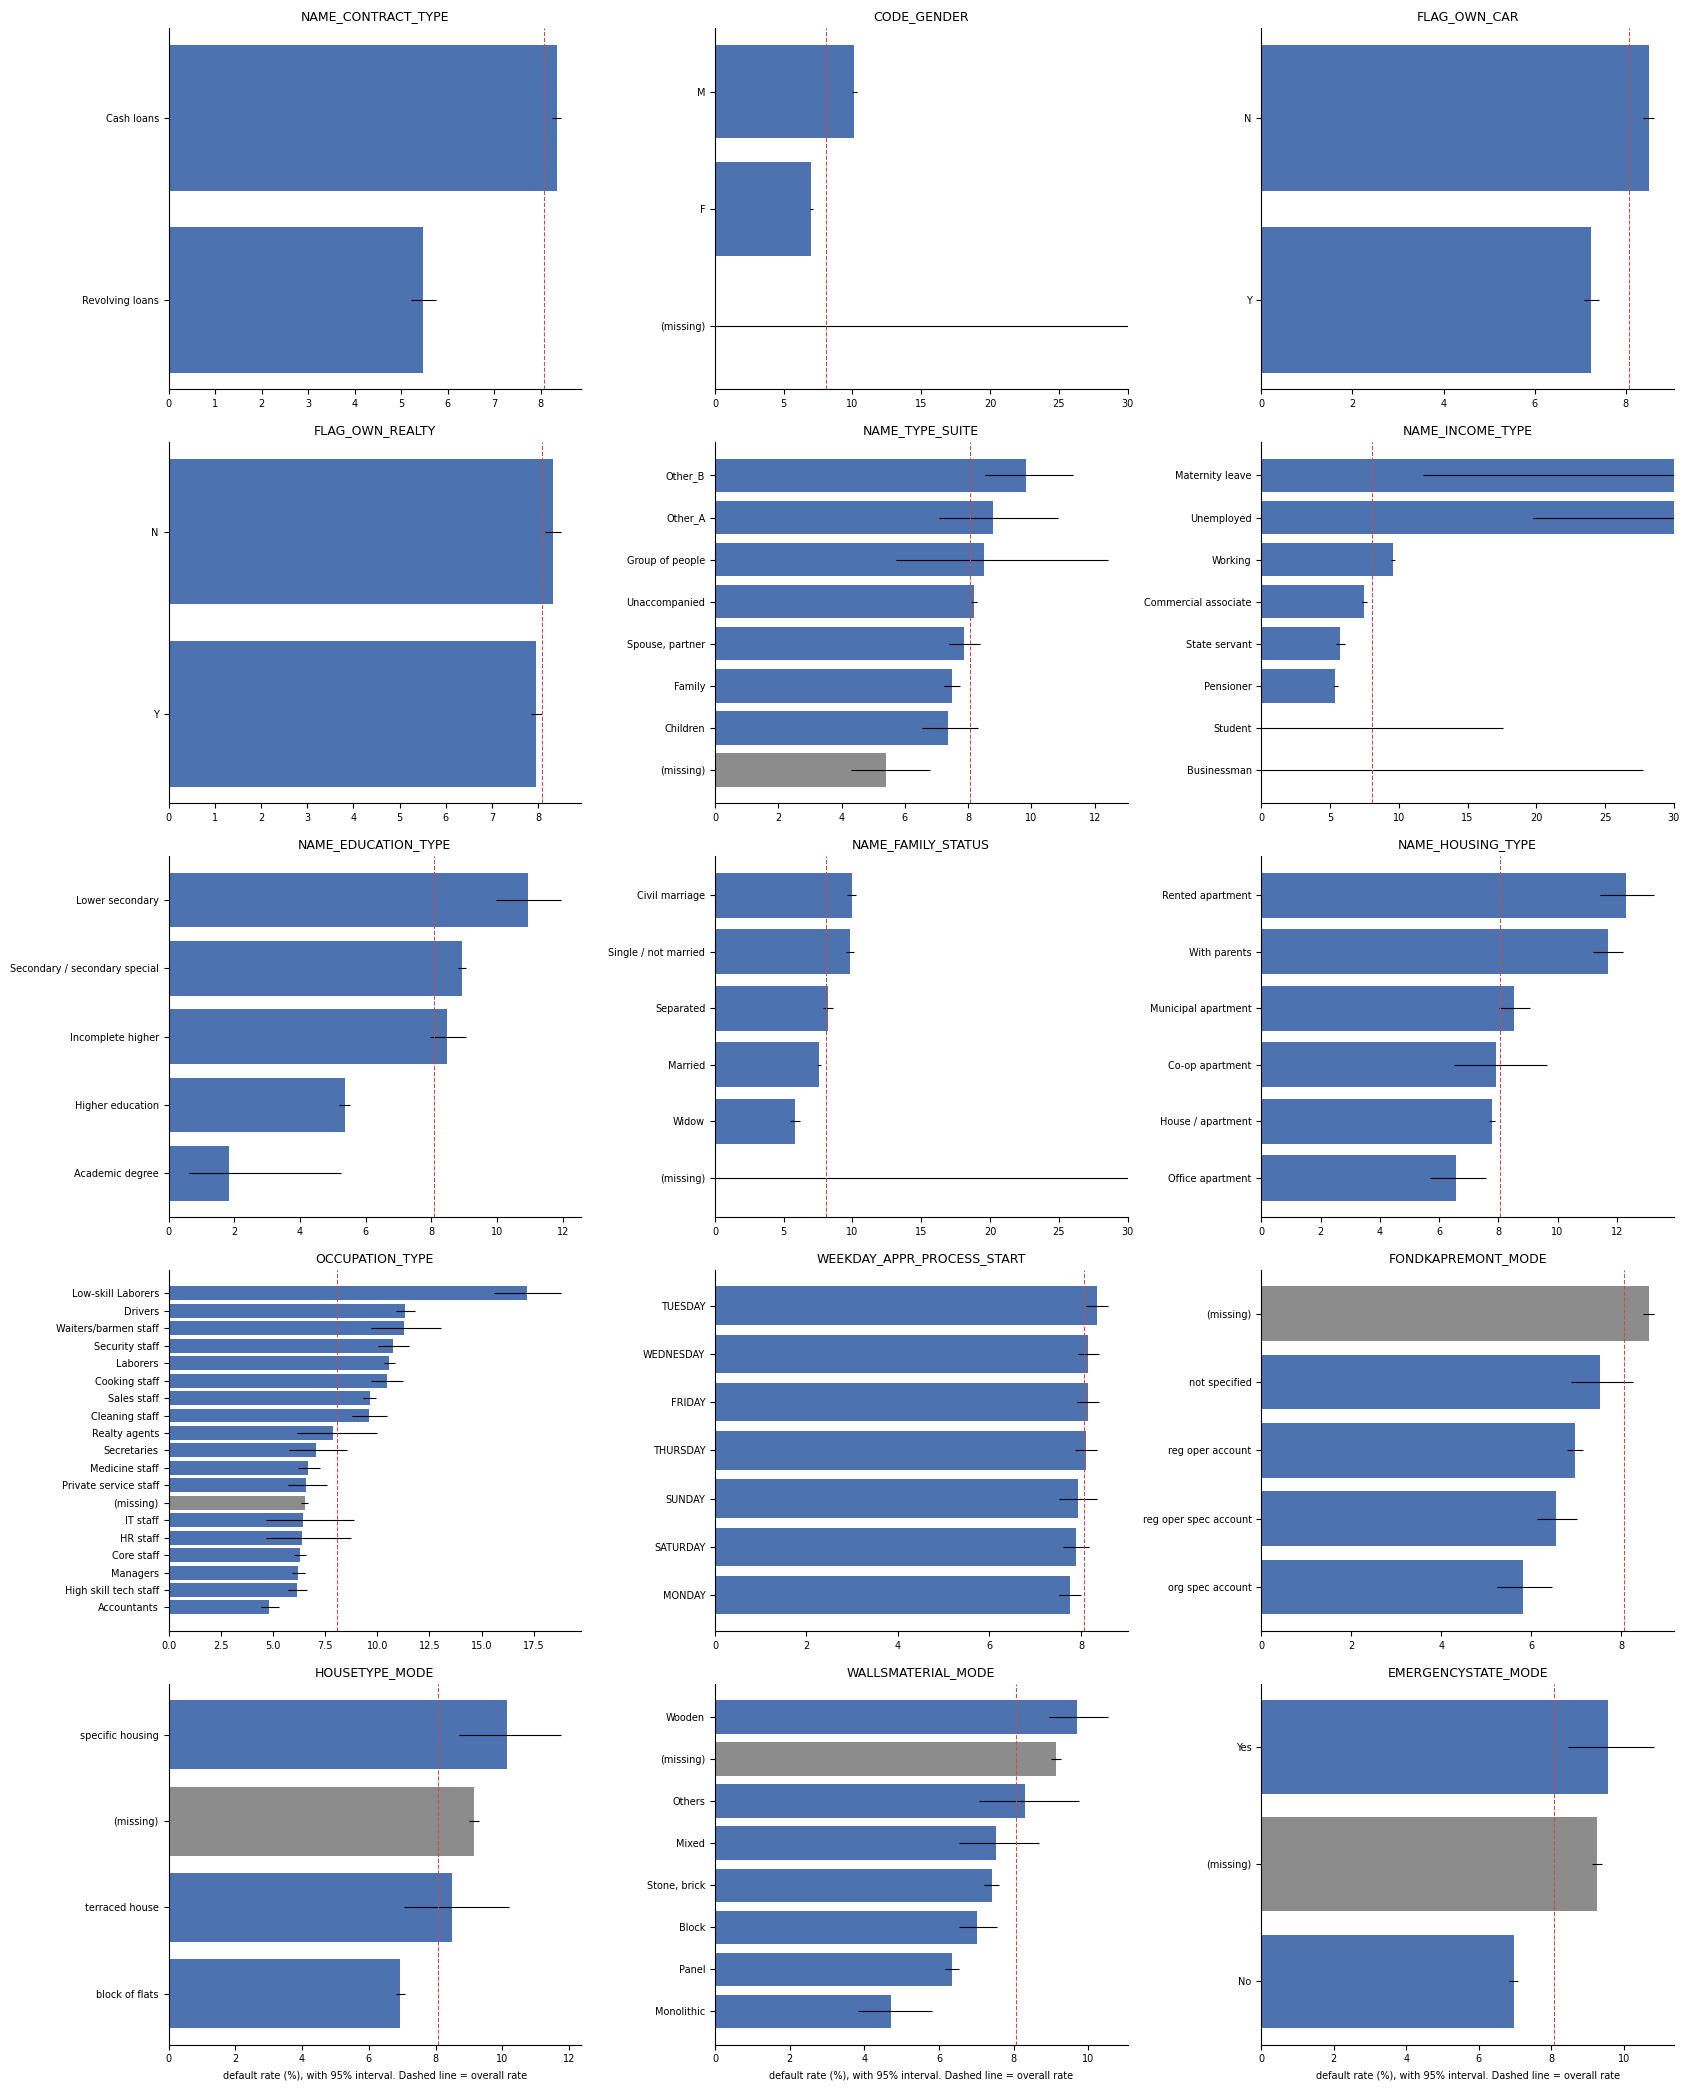

In [61]:
def plot_levels(ax, col, table=None, label_size=7):
    t = (level_table(col) if table is None else table).sort_values('default_pct')
    colors = np.where(t.index == '(missing)', '#8C8C8C', '#4C72B0')
    ax.barh(t.index.astype(str), t['default_pct'], color=colors,
            xerr=[t['default_pct'] - t['ci_low'], t['ci_high'] - t['default_pct']],
            error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
    ax.axvline(default_rate * 100, color='#C44E52', linestyle='--', linewidth=0.8)
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis='y', labelsize=label_size)
    ax.tick_params(axis='x', labelsize=7)

small = [c for c in cat_cols if c != 'ORGANIZATION_TYPE']
fig, axes = plt.subplots(5, 3, figsize=(17, 21))
for ax, c in zip(axes.ravel(), small):
    plot_levels(ax, c)
    ax.set_xlim(0, min(ax.get_xlim()[1], 30))
for ax in axes[-1]:
    ax.set_xlabel('default rate (%), with 95% interval. Dashed line = overall rate', fontsize=7)
sns.despine()
plt.tight_layout()
plt.show()

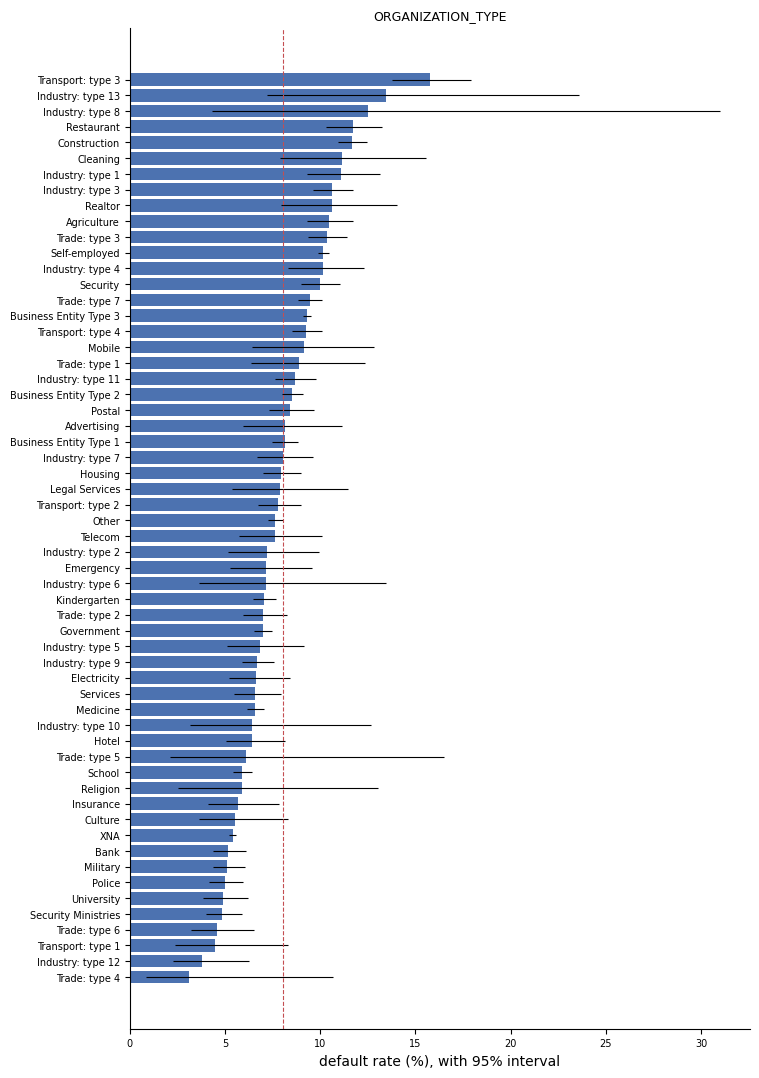

In [62]:
fig, ax = plt.subplots(figsize=(8, 13))
plot_levels(ax, 'ORGANIZATION_TYPE', org_table, label_size=7)
ax.set_xlabel('default rate (%), with 95% interval')
sns.despine()
plt.show()

### 6.4 How much does each column tell us?

Four measures per column:
- `spread_pts`: gap between the highest and lowest default rate among levels with at least 500 rows.
- `cramers_v`: strength of association with the target, 0 to 1, corrected for the number of levels.
- `iv`: information value, the standard credit scoring measure. Under 0.02 is not useful, 0.02 to 0.1 is weak, 0.1 to 0.3 is medium, above 0.3 is strong.
- `oof_auc`: ROC AUC of the column alone, with each level replaced by its default rate learned on the other four folds. This is the honest version, since a level's rate is never computed from the rows it is scored on.

In [63]:
def cramers_v(s, target):
    table = pd.crosstab(s, target)
    chi2, p, _, _ = chi2_contingency(table)
    n = table.values.sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_adj, k_adj = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_adj - 1, r_adj - 1)), p

def information_value(s, target):
    t = pd.crosstab(s, target)
    good = (t[0] + 0.5) / (t[0].sum() + 0.5 * len(t))
    bad = (t[1] + 0.5) / (t[1].sum() + 0.5 * len(t))
    return ((good - bad) * np.log(good / bad)).sum()

def oof_target_auc(s, target):
    encoded = pd.Series(np.nan, index=s.index)
    for train_idx, val_idx in cv.split(s, target):
        rates = target.iloc[train_idx].groupby(s.iloc[train_idx]).mean()
        encoded.iloc[val_idx] = s.iloc[val_idx].map(rates).fillna(target.iloc[train_idx].mean()).values
    return roc_auc_score(target, encoded)

def strength(s, target):
    t = level_table(None, values=s)
    big = t[t['rows'] >= 500]
    v, p = cramers_v(s, target)
    return {'levels': len(t), 'lowest_level_pct': big['default_pct'].min(), 'highest_level_pct': big['default_pct'].max(),
            'spread_pts': big['default_pct'].max() - big['default_pct'].min(),
            'cramers_v': v, 'iv': information_value(s, target), 'oof_auc': oof_target_auc(s, target), 'p_value': p}

cat_strength = pd.DataFrame({c: strength(cats[c], y) for c in cat_cols}).T.sort_values('iv', ascending=False)
cat_strength.round(4)

,levels,lowest_level_pct,highest_level_pct,spread_pts,cramers_v,iv,oof_auc,p_value
OCCUPATION_TYPE,19.0,4.8303,17.1524,12.3221,0.0798,0.0828,0.5747,0.0000
ORGANIZATION_TYPE,58.0,4.5959,15.7540,11.1581,0.0710,0.0731,0.5711,0.0000
NAME_INCOME_TYPE,8.0,5.3864,9.5885,4.2021,0.0637,0.0584,0.5598,0.0000
NAME_EDUCATION_TYPE,5.0,5.3551,10.9277,5.5726,0.0575,0.0507,0.5458,0.0000
CODE_GENDER,3.0,6.9993,10.1419,3.1426,0.0547,0.0386,0.5462,0.0000
WALLSMATERIAL_MODE,8.0,4.7218,9.6979,4.9761,0.0439,0.0273,0.5420,0.0000
EMERGENCYSTATE_MODE,3.0,6.9649,9.5790,2.6141,0.0421,0.0240,0.5378,0.0000
HOUSETYPE_MODE,4.0,6.9434,10.1401,3.1967,0.0406,0.0225,0.5364,0.0000
NAME_FAMILY_STATUS,6.0,5.8242,9.9446,4.1204,0.0403,0.0217,0.5323,0.0000
NAME_HOUSING_TYPE,6.0,6.5724,12.3131,5.7406,0.0368,0.0157,0.5178,0.0000


### 6.5 Is education ordinal?

In [64]:
education_order = ['Lower secondary', 'Secondary / secondary special', 'Incomplete higher', 'Higher education', 'Academic degree']
level_table('NAME_EDUCATION_TYPE').loc[education_order, ['rows', 'default_pct', 'ci_low', 'ci_high']].round(2)

,rows,default_pct,ci_low,ci_high
NAME_EDUCATION_TYPE,,,,
Lower secondary,3816,10.93,9.98,11.96
Secondary / secondary special,218391,8.94,8.82,9.06
Incomplete higher,10277,8.48,7.96,9.04
Higher education,74863,5.36,5.20,5.52
Academic degree,164,1.83,0.62,5.24


In [65]:
weekday_order = ['MONDAY', 'TUESDAY', 'WEDNESDAY', 'THURSDAY', 'FRIDAY', 'SATURDAY', 'SUNDAY']
level_table('WEEKDAY_APPR_PROCESS_START').loc[weekday_order, ['rows', 'default_pct', 'ci_low', 'ci_high']].round(2)

,rows,default_pct,ci_low,ci_high
WEEKDAY_APPR_PROCESS_START,,,,
MONDAY,50714,7.76,7.53,7.99
TUESDAY,53901,8.35,8.12,8.59
WEDNESDAY,51934,8.16,7.93,8.40
THURSDAY,50591,8.10,7.87,8.34
FRIDAY,50338,8.15,7.91,8.39
SATURDAY,33852,7.89,7.60,8.18
SUNDAY,16181,7.93,7.52,8.36


### 6.6 Can `ORGANIZATION_TYPE` be simplified?

Many of its 58 levels are numbered sub-types (`Trade: type 1` to `type 7`, `Industry: type 1` to `type 13`, and so on). Collapsing each family to one level would cut the cardinality. The check is whether the sub-types within a family actually differ.

In [66]:
org = app_clean['ORGANIZATION_TYPE']
family = org.str.replace(r':? [Tt]ype \d+$', '', regex=True)
print(f"levels: {org.nunique()} as stored, {family.nunique()} after collapsing numbered sub-types")

numbered = org[org != family]
within = (level_table(None, values=numbered)
          .assign(family=lambda t: t.index.str.replace(r':? [Tt]ype \d+$', '', regex=True))
          .groupby('family')
          .agg(sub_types=('rows', 'size'), rows=('rows', 'sum'),
               lowest_pct=('default_pct', 'min'), highest_pct=('default_pct', 'max')))
within['spread_pts'] = within['highest_pct'] - within['lowest_pct']
print(within.round(2).to_string())

compare = pd.DataFrame({'as stored (58 levels)': strength(org, y), 'collapsed families': strength(family, y)}).T
compare[['levels', 'spread_pts', 'cramers_v', 'iv', 'oof_auc']].round(4)

levels: 58 as stored, 35 after collapsing numbered sub-types
                 sub_types   rows  lowest_pct  highest_pct  spread_pts
family                                                                
Business Entity          3  84529        8.14         9.30        1.16
Industry                13  14311        3.79        13.43        9.64
Trade                    7  14315        3.12        10.34        7.21
Transport                4   8990        4.48        15.75       11.28


,levels,spread_pts,cramers_v,iv,oof_auc
as stored (58 levels),58.0,11.1581,0.0710,0.0731,0.5711
collapsed families,35.0,6.8430,0.0669,0.0655,0.5666


In [67]:
# sub-types inside the two largest families, with intervals
for fam in ['Business Entity', 'Trade', 'Industry', 'Transport']:
    members = org[family.eq(fam) & org.ne(fam)]
    print(fam)
    print(level_table(None, values=members)[['rows', 'default_pct', 'ci_low', 'ci_high']].round(2).to_string())
    print()

Business Entity
                         rows  default_pct  ci_low  ci_high
ORGANIZATION_TYPE                                          
Business Entity Type 3  67992         9.30    9.08     9.52
Business Entity Type 2  10553         8.53    8.01     9.08
Business Entity Type 1   5984         8.14    7.47     8.86

Trade
                   rows  default_pct  ci_low  ci_high
ORGANIZATION_TYPE                                    
Trade: type 3      3492        10.34    9.37    11.39
Trade: type 7      7831         9.45    8.82    10.12
Trade: type 1       348         8.91    6.35    12.37
Trade: type 2      1900         7.00    5.94     8.24
Trade: type 5        49         6.12    2.10    16.52
Trade: type 6       631         4.60    3.22     6.52
Trade: type 4        64         3.12    0.86    10.70

Industry
                   rows  default_pct  ci_low  ci_high
ORGANIZATION_TYPE                                    
Industry: type 13    67        13.43    7.23    23.60
Industry: type 8   

Transport
                   rows  default_pct  ci_low  ci_high
ORGANIZATION_TYPE                                    
Transport: type 3  1187        15.75   13.79    17.94
Transport: type 4  5398         9.28    8.54    10.08
Transport: type 2  2204         7.80    6.76     9.00
Transport: type 1   201         4.48    2.37     8.29



### Stage 6 findings

**Level counts**
- 16 text columns. Five have two levels, nine have between 3 and 8, `OCCUPATION_TYPE` has 18 and `ORGANIZATION_TYPE` has 58.
- Several are dominated by one level: `NAME_CONTRACT_TYPE` (90% cash loans), `NAME_HOUSING_TYPE` (89% house or apartment), `NAME_TYPE_SUITE` (81% unaccompanied), `NAME_EDUCATION_TYPE` (71% secondary).

**Rare levels**
- 23 levels have fewer than 500 applicants, in 4 columns: 17 in `ORGANIZATION_TYPE` (3,972 rows), 4 in `NAME_INCOME_TYPE` (55 rows), and one each in `NAME_EDUCATION_TYPE` and `NAME_TYPE_SUITE`.
- The four rare income types are Unemployed (8 defaults in 22), Maternity leave (2 in 5), Student (0 in 18) and Businessman (0 in 10). Unemployed is the only one where the interval (20% to 57%) clearly excludes the overall rate. The others are too small to say anything.

**Default rate per level: where the signal is**

| Column | Lowest level | Highest level |
|---|---|---|
| `OCCUPATION_TYPE` | Accountants 4.8% | Low-skill laborers 17.2% |
| `ORGANIZATION_TYPE` | Trade: type 6 4.6% | Transport: type 3 15.8% |
| `NAME_HOUSING_TYPE` | Office apartment 6.6% | Rented apartment 12.3%, with parents 11.7% |
| `NAME_EDUCATION_TYPE` | Higher education 5.4% | Lower secondary 10.9% |
| `NAME_INCOME_TYPE` | Pensioner 5.4%, state servant 5.8% | Working 9.6% |
| `NAME_FAMILY_STATUS` | Widow 5.8% | Civil marriage 9.9%, single 9.8% |
| `CODE_GENDER` | Female 7.0% | Male 10.1% |
| `NAME_CONTRACT_TYPE` | Revolving loans 5.5% | Cash loans 8.4% |

(Levels with at least 500 rows.)

- In the three building text columns, the missing level defaults at 9.1% to 9.3%, close to the worst real level. Among the filled values there is a real range too: wooden walls 9.7%, panel 6.4%, monolithic 4.7%.

**Strength**
- Every categorical column is weak by the usual information value scale. The best is `OCCUPATION_TYPE` at 0.083, and nothing reaches the 0.1 that counts as medium.
- Ranked by information value: `OCCUPATION_TYPE` (0.083), `ORGANIZATION_TYPE` (0.073), `NAME_INCOME_TYPE` (0.058), `NAME_EDUCATION_TYPE` (0.051), `CODE_GENDER` (0.039).
- Out-of-fold AUC tops out at 0.575. For comparison, a single external score reaches 0.66 to 0.68.
- Three columns carry almost nothing: `WEEKDAY_APPR_PROCESS_START` (7.8% to 8.4% across days, information value 0.0007), `FLAG_OWN_REALTY` (8.0% against 8.3%, 0.0005) and `NAME_TYPE_SUITE` (0.002).

**Education is ordinal**
- The default rate falls at every step: lower secondary 10.9%, secondary 8.9%, incomplete higher 8.5%, higher 5.4%, academic degree 1.8%.

**`ORGANIZATION_TYPE` should not be collapsed by family**
- Merging the numbered sub-types cuts 58 levels to 35, but it loses signal: information value drops from 0.073 to 0.066 and out-of-fold AUC from 0.571 to 0.567.
- The sub-types really differ. Transport type 3 defaults at 15.8% (interval 13.8% to 17.9%) against 7.8% for type 2. Trade type 3 is at 10.3% against 4.6% for type 6. Industry ranges from 3.8% to 11.1% among sub-types with usable sample sizes.
- Only Business Entity is tight (8.1% to 9.3%).

**Decisions**
- Two-level text columns: encode as 0 and 1.
- `NAME_EDUCATION_TYPE`: encode as an ordered integer, 0 to 4.
- Columns with 3 to 8 levels: one-hot for linear models, native categorical for tree models. Keep `(missing)` as its own level.
- `OCCUPATION_TYPE`: keep all 18 levels plus missing.
- `ORGANIZATION_TYPE`: keep the 58 levels. For linear models, merge the 17 levels under 500 rows into one, or use out-of-fold target encoding. Never fit target encoding on the rows it is applied to.
- Rare income types: too few rows for a model to learn from. Fold Student and Businessman into the nearest large level or a "rare" level. Unemployed is already identified by the missing `DAYS_EMPLOYED`.
- `WEEKDAY_APPR_PROCESS_START`, `FLAG_OWN_REALTY` and `NAME_TYPE_SUITE` are candidates to drop, to be confirmed in stage 8.
- Categorical columns are supporting features. None of them comes close to the external scores, age or job tenure.

## Stage 7: Binary flags

Which flags carry signal and which are near-constant. Uses `app_clean`.

This stage covers the 32 integer 0/1 flags: 20 document flags, 6 contact flags and 6 address mismatch flags. The two-level text columns were covered in stage 6.

### 7.1 Prevalence

A flag is only useful if both of its values occur often enough. `minority_rows` is the number of applicants holding the rarer value, and `minority_defaults` is how many of those defaulted. Under 500 rows the flag is treated as near-constant, the same threshold used for rare levels in stage 6.

In [68]:
flag_cols = [c for c in app_clean.columns
             if col_info.loc[c, 'semantic_type'] == 'binary' and pd.api.types.is_integer_dtype(app_clean[c]) and c != 'TARGET']
print(len(flag_cols), 'flags:', app_clean[flag_cols].isna().sum().sum(), 'missing values')
print(pd.Series({c: col_info.loc[c, 'group'] for c in flag_cols}).value_counts().to_string())

rows = []
for c in flag_cols:
    ones = int(app_clean[c].sum())
    minority_value = 1 if ones <= len(app_clean) - ones else 0
    minority = app_clean[c] == minority_value
    rows.append({'flag': c, 'group': col_info.loc[c, 'group'], 'ones_pct': ones / len(app_clean) * 100,
                 'minority_value': minority_value, 'minority_rows': int(minority.sum()),
                 'minority_defaults': int(y[minority].sum())})
prevalence = pd.DataFrame(rows).set_index('flag')
prevalence['near_constant'] = prevalence['minority_rows'] < 500
prevalence.sort_values('minority_rows').round(3)

32 flags: 0 missing values
documents           20
contact              6
address_mismatch     6


,group,ones_pct,minority_value,minority_rows,minority_defaults,near_constant
flag,,,,,,
FLAG_MOBIL,contact,100.000,0,1,0,True
FLAG_DOCUMENT_12,documents,0.001,1,2,0,True
FLAG_DOCUMENT_10,documents,0.002,1,7,0,True
FLAG_DOCUMENT_2,documents,0.004,1,13,4,True
FLAG_DOCUMENT_4,documents,0.008,1,25,0,True
FLAG_DOCUMENT_7,documents,0.019,1,59,3,True
FLAG_DOCUMENT_17,documents,0.027,1,82,2,True
FLAG_DOCUMENT_21,documents,0.033,1,103,14,True
FLAG_DOCUMENT_20,documents,0.051,1,156,13,True


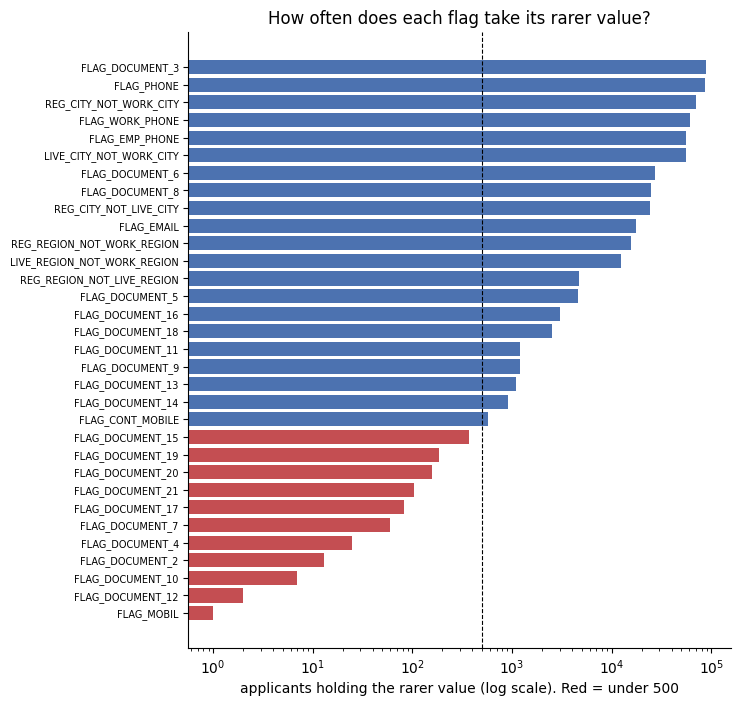

In [69]:
fig, ax = plt.subplots(figsize=(7, 8))
plot = prevalence.sort_values('minority_rows')
ax.barh(plot.index, plot['minority_rows'], color=np.where(plot['near_constant'], '#C44E52', '#4C72B0'))
ax.axvline(500, color='black', linestyle='--', linewidth=0.8)
ax.set_xscale('log')
ax.set_xlabel('applicants holding the rarer value (log scale). Red = under 500')
ax.set_title('How often does each flag take its rarer value?')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

### 7.2 Signal

Default rate when the flag is 1 against when it is 0, with a 95% interval on the difference. `iv` is the information value and `auc` is the flag used alone as a score. A flag has signal when it is not near-constant and the interval on the difference excludes zero.

In [70]:
from scipy.stats import fisher_exact

rows = []
for c in flag_cols:
    on = app_clean[c] == 1
    n1, n0 = on.sum(), (~on).sum()
    p1, p0 = y[on].mean(), y[~on].mean()
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    table = pd.crosstab(on, y)
    p_value = fisher_exact(table)[1] if (table.values < 5).any() else chi2_contingency(table)[1]
    auc = roc_auc_score(y, app_clean[c])
    rows.append({
        'flag': c,
        'default_pct_when_1': p1 * 100, 'default_pct_when_0': p0 * 100,
        'difference_pts': (p1 - p0) * 100,
        'ci_low': (p1 - p0 - 1.96 * se) * 100, 'ci_high': (p1 - p0 + 1.96 * se) * 100,
        'relative_risk': p1 / p0 if p0 > 0 else np.nan,
        'iv': information_value(app_clean[c], y), 'auc': max(auc, 1 - auc), 'p_value': p_value,
    })
flag_signal = prevalence.join(pd.DataFrame(rows).set_index('flag'))

def verdict(r):
    if r['near_constant']:
        return 'near-constant'
    if r['ci_low'] <= 0 <= r['ci_high']:
        return 'no signal'
    return 'signal'

flag_signal['verdict'] = flag_signal.apply(verdict, axis=1)
print(flag_signal['verdict'].value_counts().to_string())
print(pd.crosstab(flag_signal['group'], flag_signal['verdict']))

shown = ['group', 'ones_pct', 'minority_rows', 'default_pct_when_1', 'default_pct_when_0', 'difference_pts',
         'ci_low', 'ci_high', 'relative_risk', 'iv', 'auc', 'p_value', 'verdict']
flag_signal.sort_values('iv', ascending=False)[shown].round({'ones_pct': 3, 'default_pct_when_1': 2, 'default_pct_when_0': 2,
    'difference_pts': 2, 'ci_low': 2, 'ci_high': 2, 'relative_risk': 2, 'iv': 4, 'auc': 4, 'p_value': 4})

verdict
signal           17
near-constant    11
no signal         4
verdict           near-constant  no signal  signal
group                                             
address_mismatch              0          1       5
contact                       1          2       3
documents                    10          1       9


,group,ones_pct,minority_rows,default_pct_when_1,default_pct_when_0,difference_pts,ci_low,ci_high,relative_risk,iv,auc,p_value,verdict
flag,,,,,,,,,,,,,
FLAG_EMP_PHONE,contact,81.989,55386,8.66,5.40,3.26,3.04,3.48,1.60,0.0329,0.5324,0.0000,signal
REG_CITY_NOT_WORK_CITY,address_mismatch,23.045,70867,10.61,7.31,3.30,3.05,3.55,1.45,0.0322,0.5394,0.0000,signal
FLAG_DOCUMENT_3,documents,71.002,89171,8.84,6.18,2.66,2.46,2.86,1.43,0.0286,0.5369,0.0000,signal
REG_CITY_NOT_LIVE_CITY,address_mismatch,7.817,24039,12.23,7.72,4.51,4.08,4.93,1.58,0.0223,0.5219,0.0000,signal
LIVE_CITY_NOT_WORK_CITY,address_mismatch,17.955,55215,9.97,7.66,2.31,2.04,2.58,1.30,0.0132,0.5229,0.0000,signal
FLAG_DOCUMENT_6,documents,8.806,27078,5.57,8.31,-2.75,-3.04,-2.46,0.67,0.0128,0.5149,0.0000,signal
FLAG_WORK_PHONE,contact,19.937,61308,9.63,7.69,1.94,1.69,2.20,1.25,0.0103,0.5209,0.0000,signal
FLAG_PHONE,contact,28.107,86431,7.04,8.48,-1.44,-1.65,-1.24,0.83,0.0079,0.5196,0.0000,signal
FLAG_DOCUMENT_13,documents,0.353,1084,2.77,8.09,-5.32,-6.31,-4.34,0.34,0.0028,0.5013,0.0000,signal


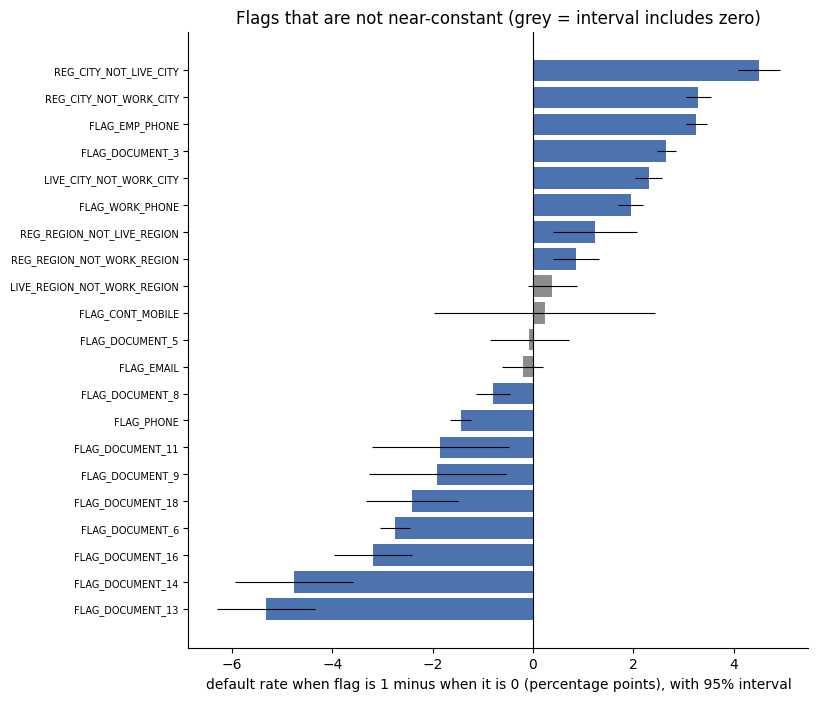

In [71]:
fig, ax = plt.subplots(figsize=(8, 8))
plot = flag_signal[~flag_signal['near_constant']].sort_values('difference_pts')
colors = plot['verdict'].map({'signal': '#4C72B0', 'no signal': '#8C8C8C'})
ax.barh(plot.index, plot['difference_pts'], color=colors,
        xerr=[plot['difference_pts'] - plot['ci_low'], plot['ci_high'] - plot['difference_pts']],
        error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('default rate when flag is 1 minus when it is 0 (percentage points), with 95% interval')
ax.set_title('Flags that are not near-constant (grey = interval includes zero)')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

### 7.3 Document flags as a group

In [72]:
doc_cols = groups['documents']
n_docs = app_clean[doc_cols].sum(axis=1)

by_count = y.groupby(n_docs).agg(rows='size', defaults='sum')
by_count['share_pct'] = (by_count['rows'] / len(y) * 100).round(2)
by_count['default_pct'] = (by_count['defaults'] / by_count['rows'] * 100).round(2)
by_count.index.name = 'documents provided'
print(by_count)

print('\nmost common document, among applicants who provided exactly one:')
one_doc = app_clean.loc[n_docs == 1, doc_cols].idxmax(axis=1)
single = y[n_docs == 1].groupby(one_doc).agg(rows='size', default_pct='mean')
single['default_pct'] = (single['default_pct'] * 100).round(2)
print(single.sort_values('rows', ascending=False).head(8))

                      rows  defaults  share_pct  default_pct
documents provided                                          
0                    29549      1632       9.61         5.52
1                   270056     22817      87.82         8.45
2                     7742       359       2.52         4.64
3                      163        16       0.05         9.82
4                        1         1       0.00       100.00

most common document, among applicants who provided exactly one:
                    rows  default_pct
FLAG_DOCUMENT_3   212036         8.96
FLAG_DOCUMENT_6    26975         5.57
FLAG_DOCUMENT_8    23588         7.56
FLAG_DOCUMENT_5     4643         8.01
FLAG_DOCUMENT_11    1151         6.08
FLAG_DOCUMENT_9     1141         6.31
FLAG_DOCUMENT_18     315         2.54
FLAG_DOCUMENT_21      86         8.14


In [73]:
# FLAG_DOCUMENT_3 is the strongest document flag. Is that the document, or the kind of loan it comes with?
doc3 = app_clean['FLAG_DOCUMENT_3'].map({1: 'document 3 provided', 0: 'not provided'})
by_contract = y.groupby([app_clean['NAME_CONTRACT_TYPE'], doc3]).agg(rows='size', default_pct='mean')
by_contract['default_pct'] = (by_contract['default_pct'] * 100).round(2)
print(by_contract)

print('\nshare providing document 3, by contract type')
print((app_clean.groupby('NAME_CONTRACT_TYPE')['FLAG_DOCUMENT_3'].mean() * 100).round(2).to_string())

print('\nwhat the applicants without document 3 provided instead (cash loans only)')
cash_no3 = (app_clean['NAME_CONTRACT_TYPE'] == 'Cash loans') & (app_clean['FLAG_DOCUMENT_3'] == 0)
other = app_clean.loc[cash_no3, doc_cols].sum().sort_values(ascending=False).head(5)
print((other / cash_no3.sum() * 100).round(1).to_string())
print(f"none at all: {(n_docs[cash_no3] == 0).mean() * 100:.1f}%")

                                          rows  default_pct
NAME_CONTRACT_TYPE FLAG_DOCUMENT_3                         
Cash loans         document 3 provided  217198         8.84
                   not provided          61034         6.58
Revolving loans    document 3 provided    1142         9.11
                   not provided          28137         5.33

share providing document 3, by contract type


NAME_CONTRACT_TYPE
Cash loans         78.06
Revolving loans     3.90

what the applicants without document 3 provided instead (cash loans only)
FLAG_DOCUMENT_6     44.3
FLAG_DOCUMENT_8     40.5
FLAG_DOCUMENT_5      6.4
FLAG_DOCUMENT_9      1.8
FLAG_DOCUMENT_11     1.5
none at all: 4.9%


### 7.4 Contact and address flags as groups

In [74]:
contact_cols = groups['contact']
address_cols = groups['address_mismatch']

for name, cols in [('contact details provided', contact_cols), ('address mismatches', address_cols)]:
    total = app_clean[cols].sum(axis=1)
    t = y.groupby(total).agg(rows='size', default_pct='mean')
    t['default_pct'] = (t['default_pct'] * 100).round(2)
    t.index.name = name
    print(t)
    print()

# region-level against city-level mismatches
region_any = app_clean[[c for c in address_cols if 'REGION' in c]].max(axis=1)
city_any = app_clean[[c for c in address_cols if 'CITY' in c]].max(axis=1)
both = y.groupby([region_any.map({0: 'no region mismatch', 1: 'region mismatch'}),
                  city_any.map({0: 'no city mismatch', 1: 'city mismatch'})]).agg(rows='size', default_pct='mean')
both['default_pct'] = (both['default_pct'] * 100).round(2)
print(both)

                            rows  default_pct
contact details provided                     
1                             27         3.70
2                          38357         5.67
3                         160972         8.38
4                          70671         8.50
5                          35492         8.39
6                           1992         8.99



                      rows  default_pct
address mismatches                     
0                   228354         7.30
1                     1385         8.66
2                    64077        10.29
3                     2953        12.33
4                     9544         9.86
5                      869        11.16
6                      329         9.73



                                       rows  default_pct
no region mismatch city mismatch      62841        10.70
                   no city mismatch  228354         7.30
region mismatch    city mismatch      11276         9.83
                   no city mismatch    5040         6.29


In [75]:
# flags that move together (phi correlation), strongest pairs
usable = flag_signal.index[~flag_signal['near_constant']].tolist()
phi = app_clean[usable].corr()
pairs = phi.where(np.triu(np.ones(phi.shape, dtype=bool), k=1)).stack().rename('phi').reset_index()
pairs.columns = ['a', 'b', 'phi']
pairs.sort_values('phi', key=abs, ascending=False).head(12).round(3).reset_index(drop=True)

,a,b,phi
0,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,0.861
1,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,0.826
2,FLAG_EMP_PHONE,FLAG_DOCUMENT_6,-0.598
3,FLAG_DOCUMENT_3,FLAG_DOCUMENT_6,-0.486
4,FLAG_DOCUMENT_3,FLAG_DOCUMENT_8,-0.466
5,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,0.451
6,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,0.440
7,REG_REGION_NOT_LIVE_REGION,REG_CITY_NOT_LIVE_CITY,0.339
8,FLAG_WORK_PHONE,FLAG_PHONE,0.293
9,FLAG_EMP_PHONE,REG_CITY_NOT_WORK_CITY,0.256


### 7.5 Do combined flags beat the individual ones?

Each candidate is scored alone, on the same measures as the single flags.

In [76]:
candidates = {
    'documents provided (count)': n_docs,
    'no document provided': (n_docs == 0).astype(int),
    'document other than 3 provided': (app_clean[[c for c in doc_cols if c != 'FLAG_DOCUMENT_3']].sum(axis=1) > 0).astype(int),
    'address mismatches (count)': app_clean[address_cols].sum(axis=1),
    'city-level mismatches (count)': app_clean[[c for c in address_cols if 'CITY' in c]].sum(axis=1),
    'any city-level mismatch': city_any,
    'contact details provided (count)': app_clean[contact_cols].sum(axis=1),
}
rows = {}
for name, s in candidates.items():
    auc = roc_auc_score(y, s)
    rows[name] = {'values': s.nunique(), 'iv': information_value(s, y), 'auc': max(auc, 1 - auc)}
combined = pd.DataFrame(rows).T

best = flag_signal.sort_values('iv', ascending=False).head(6)[['iv', 'auc']].assign(values=2)
pd.concat([combined.assign(kind='combined'), best.assign(kind='single flag')]).sort_values('iv', ascending=False).round(4)

,values,iv,auc,kind
city-level mismatches (count),4.0,0.0338,0.5410,combined
any city-level mismatch,2.0,0.0330,0.5405,combined
FLAG_EMP_PHONE,2.0,0.0329,0.5324,single flag
REG_CITY_NOT_WORK_CITY,2.0,0.0322,0.5394,single flag
address mismatches (count),7.0,0.0297,0.5387,combined
FLAG_DOCUMENT_3,2.0,0.0286,0.5369,single flag
documents provided (count),5.0,0.0227,0.5109,combined
REG_CITY_NOT_LIVE_CITY,2.0,0.0223,0.5219,single flag
contact details provided (count),6.0,0.0173,0.5213,combined
document other than 3 provided,2.0,0.0156,0.5246,combined


### Stage 7 findings

**Verdict for the 32 flags**

| Verdict | Flags | Which |
|---|---:|---|
| Near-constant | 11 | `FLAG_MOBIL` and documents 2, 4, 7, 10, 12, 15, 17, 19, 20, 21 |
| No signal | 4 | `FLAG_EMAIL`, `FLAG_CONT_MOBILE`, `FLAG_DOCUMENT_5`, `LIVE_REGION_NOT_WORK_REGION` |
| Signal | 17 | Listed below |

**Near-constant**
- `FLAG_MOBIL` is 1 for all but one applicant. Documents 12, 10, 2 and 4 were provided by 2, 7, 13 and 25 applicants.
- Ten of the 20 document flags have fewer than 500 applicants on the rarer side. Some show dramatic rates (document 2: 4 defaults in 13), but nothing can be learned from counts that small.

**Signal: the eight flags that matter**

| Flag | Default when 1 | Default when 0 | Information value |
|---|---:|---:|---:|
| `FLAG_EMP_PHONE` | 8.7% | 5.4% | 0.033 |
| `REG_CITY_NOT_WORK_CITY` | 10.6% | 7.3% | 0.032 |
| `FLAG_DOCUMENT_3` | 8.8% | 6.2% | 0.029 |
| `REG_CITY_NOT_LIVE_CITY` | 12.2% | 7.7% | 0.022 |
| `LIVE_CITY_NOT_WORK_CITY` | 10.0% | 7.7% | 0.013 |
| `FLAG_DOCUMENT_6` | 5.6% | 8.3% | 0.013 |
| `FLAG_WORK_PHONE` | 9.6% | 7.7% | 0.010 |
| `FLAG_PHONE` | 7.0% | 8.5% | 0.008 |

- The other nine "signal" flags are statistically detectable but small (information value at most 0.003). Documents 13, 14, 16 and 18 are worth noting: the few applicants who provide them default at 2.8% to 5.7%.
- Even the best flag is weak. No flag exceeds an AUC of 0.54 alone.

**What the flags actually measure**
- `FLAG_EMP_PHONE = 0` is the "no employer" group from stage 4, so it adds nothing beyond that.
- `FLAG_DOCUMENT_6` is mostly provided by applicants with no employer (correlation -0.60 with `FLAG_EMP_PHONE`). Its lower default rate is the pensioner effect again.
- `FLAG_DOCUMENT_3` is the standard document: 78% of cash loan applicants provide it and 4% of revolving loan applicants. Its effect is not just the loan type, since it holds within cash loans (8.8% against 6.6%) and within revolving loans (9.1% against 5.3%). Cash applicants without it mostly provided document 6 (44%) or document 8 (41%) instead.
- So the document flags mostly describe what kind of applicant this is, not anything about the paperwork itself.

**Documents as a group**
- 88% of applicants provide exactly one document, 10% provide none and 2.5% provide two.
- Default rates: 5.5% with none, 8.5% with one, 4.6% with two. The pattern is not monotonic, and the document count scores lower than `FLAG_DOCUMENT_3` alone (information value 0.023 against 0.029).

**Address flags as a group**
- City-level mismatches matter and region-level ones do not. A city mismatch with no region mismatch gives 10.7% default against 7.3% with neither. A region mismatch without a city mismatch gives 6.3%.
- Two pairs are close to duplicates: the two "not work region" flags (correlation 0.86) and the two "not work city" flags (0.83).
- The count of city-level mismatches is the best single summary (information value 0.034, AUC 0.541), marginally ahead of `REG_CITY_NOT_WORK_CITY` alone.

**Contact flags as a group**
- The number of contact details provided adds nothing. It scores below `FLAG_EMP_PHONE` alone.

**Decisions**
- Drop the 11 near-constant flags.
- The 4 no-signal flags are candidates to drop, to be confirmed in stage 8.
- Keep the eight flags in the table. Add the count of city-level mismatches as a candidate feature for stage 11.
- Do not build a document count or a contact count. They are weaker than the single flags they are built from.
- Documents 13, 14 and 16 have signal here, but the dataset guide found them to be zero on every test row. Stage 10 checks this. If confirmed, they cannot help test predictions.
- Flags are supporting features, like the categorical columns.

## Stage 8: Feature strength ranking

Single-feature AUC for every column. Uses `app_clean`.

Stages 5 to 7 measured numeric, categorical and binary columns separately. This stage puts all 120 features on one scale so they can be ranked against each other.

### 8.1 The measure

Correlation only sees straight-line relationships, and it cannot be computed for text columns. Stage 5 showed `AMT_ANNUITY` has a correlation near zero while its default rate nearly doubles across its range.

The measure used here is the **out-of-fold AUC**:
1. Split a column into groups: ten equal-sized bins for a numeric column, the levels for a categorical or low-cardinality column, plus a group for missing values.
2. Replace each group with its default rate, learned on four folds and applied to the fifth.
3. Score the result with ROC AUC on the fifth fold, and average over the five folds.

This works the same way for every column type, captures relationships of any shape, counts missingness as information, and never scores a row using its own target. `raw_auc` (the column used directly as a score) and the absolute Pearson correlation are kept alongside for comparison.

In [77]:
features = [c for c in app_clean.columns if c not in ('SK_ID_CURR', 'TARGET')]
y_arr = y.values
fold_id = np.empty(len(y), dtype=int)
for k, (_, val_idx) in enumerate(cv.split(app_clean, y)):
    fold_id[val_idx] = k

def oof_auc(s, mask=None, smoothing=50, n_bins=10):
    # returns the mean and standard deviation of the five fold AUCs
    binned = pd.api.types.is_numeric_dtype(s) and s.nunique() > 20
    values = s.values.astype(float) if binned else None
    fixed_codes = None if binned else pd.factorize(s)[0]
    rows = np.ones(len(s), dtype=bool) if mask is None else np.asarray(mask)
    aucs = []
    for k in range(5):
        train, val = rows & (fold_id != k), rows & (fold_id == k)
        if binned:
            edges = np.unique(np.nanquantile(values[train], np.linspace(0, 1, n_bins + 1)))[1:-1]
            codes = np.where(np.isnan(values), -1, np.digitize(values, edges))
        else:
            codes = fixed_codes
        prior = y_arr[train].mean()
        stats = pd.DataFrame({'code': codes[train], 'y': y_arr[train]}).groupby('code')['y'].agg(['sum', 'count'])
        rate = (stats['sum'] + smoothing * prior) / (stats['count'] + smoothing)
        encoded = pd.Series(codes[val]).map(rate).fillna(prior).values
        aucs.append(roc_auc_score(y_arr[val], encoded))
    return np.mean(aucs), np.std(aucs, ddof=1)

def raw_auc(s):
    if not pd.api.types.is_numeric_dtype(s):
        return np.nan
    present = s.notna()
    a = roc_auc_score(y[present], s[present])
    return max(a, 1 - a)

### 8.2 The noise floor

A column with no relationship to the target still scores slightly off 0.5 by chance. Scoring 30 columns of pure random numbers shows how far, and sets the line below which a real column cannot be told apart from noise.

In [78]:
rng = np.random.default_rng(0)
noise = np.array([oof_auc(pd.Series(rng.normal(size=len(y))))[0] for _ in range(30)])
noise_floor = noise.max()
print(f"30 random columns: mean AUC {noise.mean():.4f}, min {noise.min():.4f}, max {noise.max():.4f}")
print(f"noise floor: {noise_floor:.4f}")

30 random columns: mean AUC 0.5008, min 0.4959, max 0.5055
noise floor: 0.5055


### 8.3 The ranking

In [79]:
rows = []
for c in features:
    s = app_clean[c]
    mean_auc, std_auc = oof_auc(s)
    numeric = pd.api.types.is_numeric_dtype(s)
    rows.append({
        'feature': c, 'group': col_info.loc[c, 'group'], 'type': col_info.loc[c, 'semantic_type'],
        'missing_pct': s.isna().mean() * 100,
        'oof_auc': mean_auc, 'fold_std': std_auc, 'raw_auc': raw_auc(s),
        'abs_pearson': abs(s.corr(y)) if numeric else np.nan,
    })
ranking = pd.DataFrame(rows).set_index('feature').sort_values('oof_auc', ascending=False)
ranking['rank'] = np.arange(1, len(ranking) + 1)

def tier(auc):
    if auc <= noise_floor:
        return '5 none'
    if auc < 0.52:
        return '4 marginal'
    if auc < 0.55:
        return '3 weak'
    if auc < 0.60:
        return '2 moderate'
    return '1 strong'

ranking['tier'] = ranking['oof_auc'].map(tier)
print(ranking['tier'].value_counts().sort_index().to_string())
with pd.option_context('display.max_rows', 130):
    display(ranking[['rank', 'group', 'type', 'missing_pct', 'oof_auc', 'fold_std', 'raw_auc', 'abs_pearson', 'tier']].round(4))

tier
1 strong       2
2 moderate    10
3 weak        69
4 marginal    13
5 none        26


,rank,group,type,missing_pct,oof_auc,fold_std,raw_auc,abs_pearson,tier
feature,,,,,,,,,
EXT_SOURCE_3,1,external_scores,continuous,19.8253,0.6563,0.0021,0.6794,0.1789,1 strong
EXT_SOURCE_2,2,external_scores,continuous,0.2146,0.6529,0.0058,0.6561,0.1605,1 strong
DAYS_EMPLOYED,3,income_employment,continuous,18.0072,0.5927,0.0034,0.5824,0.0750,2 moderate
EXT_SOURCE_1,4,external_scores,continuous,56.3811,0.5879,0.0052,0.6657,0.1553,2 moderate
DAYS_BIRTH,5,demographics,continuous,0.0000,0.5817,0.0054,0.5830,0.0782,2 moderate
OCCUPATION_TYPE,6,income_employment,categorical,31.3455,0.5754,0.0021,NaN,NaN,2 moderate
ORGANIZATION_TYPE,7,income_employment,categorical,0.0000,0.5720,0.0031,NaN,NaN,2 moderate
AMT_GOODS_PRICE,8,loan,continuous,0.0904,0.5626,0.0081,0.5333,0.0396,2 moderate
NAME_INCOME_TYPE,9,income_employment,categorical,0.0000,0.5611,0.0036,NaN,NaN,2 moderate


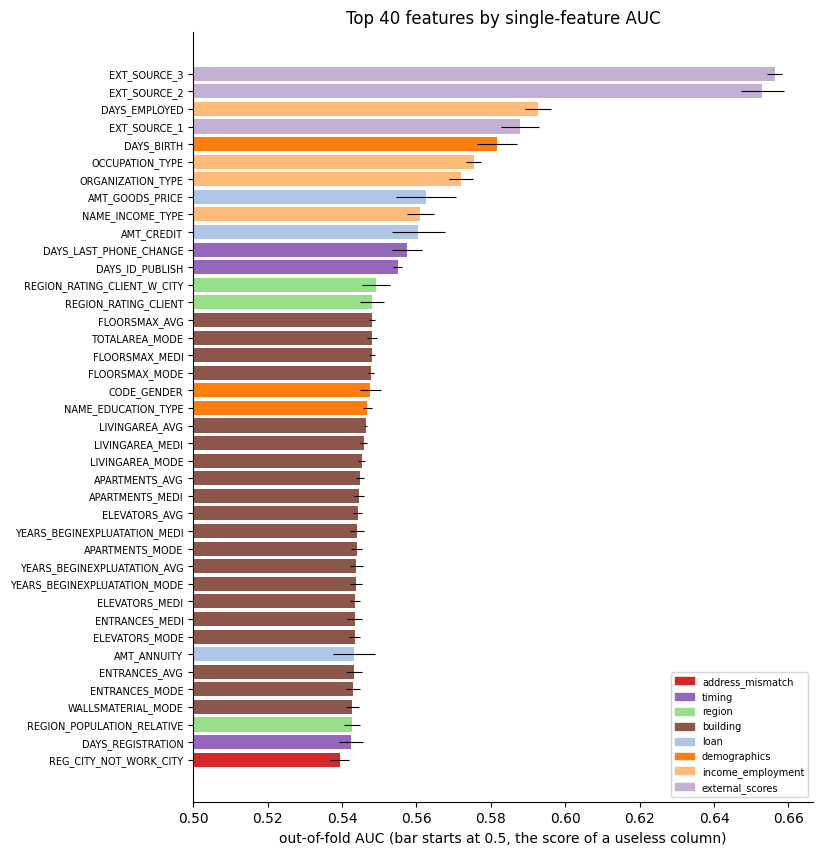

In [80]:
palette = dict(zip(groups.keys(), sns.color_palette('tab20', len(groups))))

fig, ax = plt.subplots(figsize=(8, 10))
top = ranking.head(40).iloc[::-1]
ax.barh(top.index, top['oof_auc'] - 0.5, left=0.5, color=top['group'].map(palette), xerr=top['fold_std'],
        error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
ax.set_xlabel('out-of-fold AUC (bar starts at 0.5, the score of a useless column)')
ax.set_title('Top 40 features by single-feature AUC')
ax.tick_params(axis='y', labelsize=7)
shown_groups = top['group'].unique()
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=palette[g]) for g in shown_groups], labels=list(shown_groups), fontsize=7, loc='lower right')
sns.despine()
plt.show()

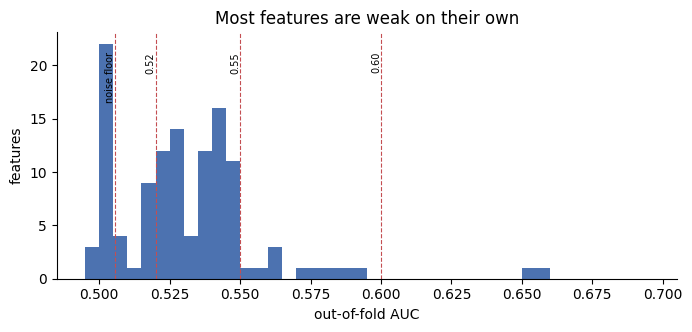

In [81]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(ranking['oof_auc'], bins=np.arange(0.495, 0.70, 0.005), color='#4C72B0')
for x, label in [(noise_floor, 'noise floor'), (0.52, '0.52'), (0.55, '0.55'), (0.60, '0.60')]:
    ax.axvline(x, color='#C44E52', linestyle='--', linewidth=0.8)
    ax.text(x, ax.get_ylim()[1] * 0.92, label, fontsize=7, rotation=90, va='top', ha='right')
ax.set_xlabel('out-of-fold AUC')
ax.set_ylabel('features')
ax.set_title('Most features are weak on their own')
sns.despine()
plt.show()

### 8.4 By column group

In [82]:
by_group = ranking.groupby('group').agg(
    features=('oof_auc', 'size'), best_auc=('oof_auc', 'max'), median_auc=('oof_auc', 'median'),
    best_feature=('oof_auc', 'idxmax'),
    moderate_or_better=('oof_auc', lambda s: (s >= 0.55).sum()),
    at_or_below_noise=('oof_auc', lambda s: (s <= noise_floor).sum()),
).sort_values('best_auc', ascending=False)
by_group.round(4)

,features,best_auc,median_auc,best_feature,moderate_or_better,at_or_below_noise
group,,,,,,
external_scores,3,0.6563,0.6529,EXT_SOURCE_3,3,0
income_employment,5,0.5927,0.5720,DAYS_EMPLOYED,4,0
demographics,7,0.5817,0.5355,DAYS_BIRTH,1,0
loan,4,0.5626,0.5519,AMT_GOODS_PRICE,2,0
timing,5,0.5574,0.5425,DAYS_LAST_PHONE_CHANGE,2,1
region,3,0.5492,0.5481,REGION_RATING_CLIENT_W_CITY,0,0
building,47,0.5481,0.5378,FLOORSMAX_AVG,0,0
address_mismatch,6,0.5394,0.5123,REG_CITY_NOT_WORK_CITY,0,3
documents,20,0.5369,0.5003,FLAG_DOCUMENT_3,0,18


### 8.5 Where correlation misleads

Numeric and binary columns ranked two ways: by absolute Pearson correlation and by out-of-fold AUC. A large positive `rank_gain` means correlation undersells the column.

In [83]:
num_rank = ranking[ranking['abs_pearson'].notna()].copy()
num_rank['rank_by_auc'] = num_rank['oof_auc'].rank(ascending=False).astype(int)
num_rank['rank_by_pearson'] = num_rank['abs_pearson'].rank(ascending=False).astype(int)
num_rank['rank_gain'] = num_rank['rank_by_pearson'] - num_rank['rank_by_auc']
num_rank['shape_gain'] = num_rank['oof_auc'] - num_rank['raw_auc']

print(f"rank agreement between the two measures (Spearman): {num_rank['oof_auc'].corr(num_rank['abs_pearson'], method='spearman'):.3f}")
cols = ['group', 'missing_pct', 'abs_pearson', 'raw_auc', 'oof_auc', 'rank_by_pearson', 'rank_by_auc', 'rank_gain']
print('\nundersold by correlation')
display(num_rank.sort_values('rank_gain', ascending=False).head(12)[cols].round(4))
print('largest gain from allowing any shape (oof_auc minus raw_auc)')
display(num_rank.sort_values('shape_gain', ascending=False).head(10)[['group', 'missing_pct', 'raw_auc', 'oof_auc', 'shape_gain']].round(4))

rank agreement between the two measures (Spearman): 0.763

undersold by correlation


,group,missing_pct,abs_pearson,raw_auc,oof_auc,rank_by_pearson,rank_by_auc,rank_gain
feature,,,,,,,,
YEARS_BEGINEXPLUATATION_MODE,building,48.7810,0.0090,0.5307,0.5438,76,25,51
YEARS_BEGINEXPLUATATION_MEDI,building,48.7810,0.0100,0.5312,0.5441,70,22,48
YEARS_BEGINEXPLUATATION_AVG,building,48.7810,0.0097,0.5310,0.5439,71,24,47
AMT_REQ_CREDIT_BUREAU_QRT,bureau_enquiries,13.5020,0.0022,0.5063,0.5296,92,47,45
AMT_ANNUITY,loan,0.0039,0.0128,0.5001,0.5433,62,29,33
NONLIVINGAPARTMENTS_MODE,building,69.4330,0.0016,0.5036,0.5238,94,64,30
ENTRANCES_MEDI,building,50.3488,0.0190,0.5270,0.5434,55,27,28
AMT_CREDIT,loan,0.0000,0.0304,0.5186,0.5605,34,7,27
AMT_REQ_CREDIT_BUREAU_WEEK,bureau_enquiries,13.5016,0.0008,0.5002,0.5198,99,72,27


largest gain from allowing any shape (oof_auc minus raw_auc)


,group,missing_pct,raw_auc,oof_auc,shape_gain
feature,,,,,
AMT_ANNUITY,loan,0.0039,0.5001,0.5433,0.0432
AMT_CREDIT,loan,0.0000,0.5186,0.5605,0.0420
AMT_GOODS_PRICE,loan,0.0904,0.5333,0.5626,0.0292
NONLIVINGAREA_MODE,building,55.1792,0.5134,0.5380,0.0246
NONLIVINGAREA_MEDI,building,55.1792,0.5143,0.5378,0.0235
AMT_REQ_CREDIT_BUREAU_QRT,bureau_enquiries,13.5020,0.5063,0.5296,0.0233
NONLIVINGAREA_AVG,building,55.1792,0.5153,0.5381,0.0228
AMT_REQ_CREDIT_BUREAU_HOUR,bureau_enquiries,13.5016,0.5001,0.5207,0.0206
AMT_REQ_CREDIT_BUREAU_DAY,bureau_enquiries,13.5016,0.5007,0.5211,0.0205


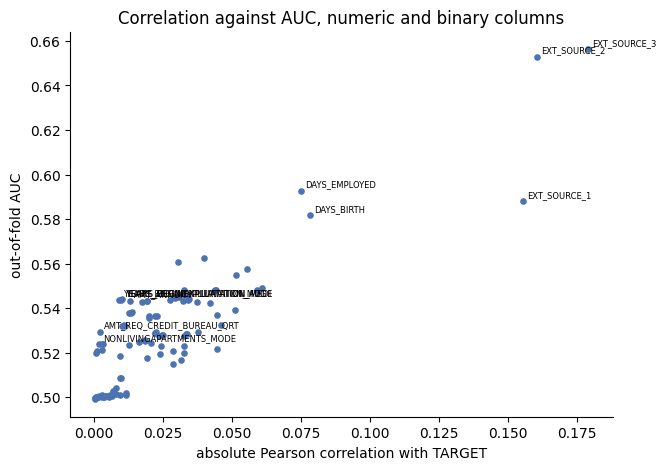

In [84]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(num_rank['abs_pearson'], num_rank['oof_auc'], s=14, color='#4C72B0')
for name in num_rank.sort_values('rank_gain', ascending=False).head(6).index.tolist() + num_rank.head(5).index.tolist():
    ax.annotate(name, (num_rank.loc[name, 'abs_pearson'], num_rank.loc[name, 'oof_auc']), fontsize=6,
                xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('absolute Pearson correlation with TARGET')
ax.set_ylabel('out-of-fold AUC')
ax.set_title('Correlation against AUC, numeric and binary columns')
sns.despine()
plt.show()

### 8.6 Value or missingness?

For columns with more than 10% missing, the overall AUC mixes two things: whether the value is present, and what the value is. `auc_missing_flag` scores the missing indicator alone. `auc_when_present` scores the values on the rows that have them.

In [85]:
rows = []
for c in ranking.index[ranking['missing_pct'] > 10]:
    s = app_clean[c]
    present = s.notna().values
    flag_auc = roc_auc_score(y, (~present).astype(int))
    rows.append({'feature': c, 'group': ranking.loc[c, 'group'], 'missing_pct': ranking.loc[c, 'missing_pct'],
                 'oof_auc': ranking.loc[c, 'oof_auc'],
                 'auc_missing_flag': max(flag_auc, 1 - flag_auc),
                 'auc_when_present': oof_auc(s, mask=present)[0]})
value_or_missing = pd.DataFrame(rows).set_index('feature')
print(value_or_missing.groupby('group')[['oof_auc', 'auc_missing_flag', 'auc_when_present']].median().round(4))
value_or_missing.sort_values('oof_auc', ascending=False).head(25).round(4)

                   oof_auc  auc_missing_flag  auc_when_present
group                                                         
assets_housing      0.5292            0.5190            0.5635
building            0.5378            0.5358            0.5278
bureau_enquiries    0.5224            0.5206            0.5025
external_scores     0.6221            0.5168            0.6695
income_employment   0.5840            0.5327            0.5784


,group,missing_pct,oof_auc,auc_missing_flag,auc_when_present
feature,,,,,
EXT_SOURCE_3,external_scores,19.8253,0.6563,0.5165,0.6764
DAYS_EMPLOYED,income_employment,18.0072,0.5927,0.5324,0.5818
EXT_SOURCE_1,external_scores,56.3811,0.5879,0.5170,0.6626
OCCUPATION_TYPE,income_employment,31.3455,0.5754,0.5329,0.5750
FLOORSMAX_AVG,building,49.7608,0.5481,0.5375,0.5484
TOTALAREA_MODE,building,48.2685,0.5480,0.5378,0.5437
FLOORSMAX_MEDI,building,49.7608,0.5480,0.5375,0.5482
FLOORSMAX_MODE,building,49.7608,0.5478,0.5375,0.5476
LIVINGAREA_AVG,building,50.1933,0.5464,0.5362,0.5459


### 8.7 Verdict on the drop candidates

Columns flagged in stages 5 to 7, checked against the noise floor.

In [86]:
candidates = {
    'stage 5: sparse enquiry counts': ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK'],
    'stage 6: weak categoricals': ['WEEKDAY_APPR_PROCESS_START', 'FLAG_OWN_REALTY', 'NAME_TYPE_SUITE'],
    'stage 7: no-signal flags': flag_signal.index[flag_signal['verdict'] == 'no signal'].tolist(),
    'stage 7: near-constant flags': flag_signal.index[flag_signal['verdict'] == 'near-constant'].tolist(),
}
check = pd.concat([ranking.loc[cols, ['oof_auc', 'fold_std', 'rank', 'tier']].assign(flagged_in=name)
                   for name, cols in candidates.items()])
check['above_noise_floor'] = check['oof_auc'] > noise_floor
print(pd.crosstab(check['flagged_in'], check['above_noise_floor']))
check.sort_values('oof_auc', ascending=False).round(4)

above_noise_floor               False  True 
flagged_in                                  
stage 5: sparse enquiry counts      0      3
stage 6: weak categoricals          2      1
stage 7: near-constant flags       11      0
stage 7: no-signal flags            4      0


,oof_auc,fold_std,rank,tier,flagged_in,above_noise_floor
feature,,,,,,
AMT_REQ_CREDIT_BUREAU_DAY,0.5211,0.0014,79,3 weak,stage 5: sparse enquiry counts,True
AMT_REQ_CREDIT_BUREAU_HOUR,0.5207,0.0014,81,3 weak,stage 5: sparse enquiry counts,True
AMT_REQ_CREDIT_BUREAU_WEEK,0.5198,0.0009,82,4 marginal,stage 5: sparse enquiry counts,True
NAME_TYPE_SUITE,0.5072,0.0018,94,4 marginal,stage 6: weak categoricals,True
FLAG_OWN_REALTY,0.5052,0.0042,95,5 none,stage 6: weak categoricals,False
WEEKDAY_APPR_PROCESS_START,0.5040,0.0036,97,5 none,stage 6: weak categoricals,False
LIVE_REGION_NOT_WORK_REGION,0.5010,0.0018,103,5 none,stage 7: no-signal flags,False
FLAG_EMAIL,0.5007,0.0017,105,5 none,stage 7: no-signal flags,False
FLAG_DOCUMENT_15,0.5004,0.0002,108,5 none,stage 7: near-constant flags,False


In [87]:
# every feature at or below the noise floor
at_noise = ranking[ranking['oof_auc'] <= noise_floor]
flagged = {c for cols in candidates.values() for c in cols}
print(len(at_noise), 'features at or below the noise floor')
print('not flagged in an earlier stage:', sorted(set(at_noise.index) - flagged))
print('flagged earlier but above the noise floor:', sorted(flagged - set(at_noise.index)))

26 features at or below the noise floor
not flagged in an earlier stage: ['FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION']
flagged earlier but above the noise floor: ['AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'NAME_TYPE_SUITE']


### Stage 8 findings

**The ranking**

| Tier | Out-of-fold AUC | Features |
|---|---|---:|
| Strong | 0.60 and above | 2 |
| Moderate | 0.55 to 0.60 | 10 |
| Weak | 0.52 to 0.55 | 69 |
| Marginal | noise floor to 0.52 | 13 |
| None | at or below the noise floor (0.5055) | 26 |

- The twelve features at moderate or better, in order: `EXT_SOURCE_3` (0.656), `EXT_SOURCE_2` (0.653), `DAYS_EMPLOYED` (0.593), `EXT_SOURCE_1` (0.588), `DAYS_BIRTH` (0.582), `OCCUPATION_TYPE` (0.575), `ORGANIZATION_TYPE` (0.572), `AMT_GOODS_PRICE` (0.563), `NAME_INCOME_TYPE` (0.561), `AMT_CREDIT` (0.561), `DAYS_LAST_PHONE_CHANGE` (0.557), `DAYS_ID_PUBLISH` (0.555).
- No single column reaches the stage 2 baseline of 0.7165, which came from averaging the three external scores. Combining features is where the gain is.
- Most of the table is weak. 108 of 120 features score below 0.55 alone.

**By group**
- External scores are far ahead (best 0.656), then employment (0.593), demographics (0.582), the loan amounts (0.563) and timing (0.557).
- The building block's 47 columns all land between 0.52 and 0.55. None is moderate.
- Social circle is the weakest group with any signal (best 0.520).
- 18 of the 20 document flags are at or below the noise floor.

**Where correlation misleads**
- The two measures broadly agree (rank agreement 0.76), but correlation undersells columns for two different reasons.
- Shape: `AMT_ANNUITY` goes from 0.500 used as a straight score to 0.543 once any shape is allowed, `AMT_CREDIT` from 0.519 to 0.561 and `AMT_GOODS_PRICE` from 0.533 to 0.563. `AMT_CREDIT` moves from rank 34 by correlation to rank 7 among the numeric and binary columns.
- Missingness: correlation ignores rows where the value is missing, so it cannot see that the missing rows default more. This is why the building columns and the bureau enquiry counts rank higher here.

**Value or missingness?**
- For the external scores the value is what matters. `EXT_SOURCE_1` scores 0.663 on the rows that have it and only 0.588 overall, because 56% of rows fall into one missing group. The missing flag alone scores 0.517.
- For the building block it is mostly missingness. The missing flag alone scores about 0.536, and the values on the rows that have them score a median of 0.528. Only the `FLOORSMAX` and `LIVINGAREA` columns add something beyond the flag (0.543 to 0.548 when present). `EMERGENCYSTATE_MODE` adds nothing (0.503 when present).
- For the bureau enquiry counts it is almost all missingness. The flag scores 0.521 and the values score a median of 0.503 when present.
- `OWN_CAR_AGE` is the opposite case: weak overall (0.529) but 0.564 among car owners.

**Verdict on the drop candidates**
- Confirmed at the noise floor: all 11 near-constant flags, all 4 no-signal flags, `FLAG_OWN_REALTY` and `WEEKDAY_APPR_PROCESS_START`. These 17 can be dropped.
- `AMT_REQ_CREDIT_BUREAU_HOUR`, `_DAY` and `_WEEK` score about 0.52, but only through their missing group, which is identical for all six enquiry columns. Drop the three and keep one "enquiries missing" indicator.
- `NAME_TYPE_SUITE` is marginal (0.507). Low priority, harmless to keep.
- Nine more features sit at the noise floor that were not flagged before: documents 8, 9, 11, 13, 14, 16, 18 and the two region-level "registration" mismatch flags.

**A caution on reading the noise floor for rare flags**
- AUC measures how much of the whole population a feature can rank. A flag that is 1 for 0.35% of applicants cannot move the AUC much, however strong its effect on those applicants.
- `FLAG_DOCUMENT_13` is the example: applicants who provide it default at 2.8% against 8.1% (stage 7), and it scores 0.5013 in every fold (fold standard deviation 0.0003). The effect is real. It simply reaches very few people.
- So "none" in this ranking means negligible usefulness overall, not proof of no relationship. For those nine features the choice is between dropping them and combining the rare low-risk documents into one flag in stage 11.

**Decisions**
- Drop 20 columns: the 17 confirmed above and the three sparse enquiry counts.
- Add an "enquiries missing" indicator and a "building information missing" indicator, as planned in stage 3.
- Within the building block, the values add little beyond the missing indicator. Stage 9 decides which few to keep.
- This ranking is one feature at a time. It cannot see features that only help in combination, or features that repeat each other. Stage 9 covers the repetition, and final selection should be confirmed with model-based importance.

## Stage 9: Redundancy

Correlated groups, especially the building block and the amount columns. Uses `app_clean`.

Stage 8 ranked features one at a time. Two features can both rank well and still carry the same information. This stage finds the features that repeat each other, and then tests with a model whether removing the repeats costs anything.

### 9.1 Correlated pairs among numeric columns

Spearman rank correlation, which is not thrown off by skew or outliers, computed on the rows where both columns are present. The 11 near-constant flags are left out, since a correlation built on a handful of rows means nothing.

In [88]:
near_constant = flag_signal.index[flag_signal['near_constant']].tolist()
corr_cols = [c for c in features if pd.api.types.is_numeric_dtype(app_clean[c]) and c not in near_constant]
rho = app_clean[corr_cols].rank().corr()

upper = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename('rho').reset_index()
upper.columns = ['a', 'b', 'rho']
upper['group_a'] = upper['a'].map(col_info['group'])
upper['group_b'] = upper['b'].map(col_info['group'])
upper['abs_rho'] = upper['rho'].abs()

print(len(corr_cols), 'columns,', len(upper), 'pairs')
bands = pd.cut(upper['abs_rho'], [0, 0.3, 0.5, 0.8, 0.95, 1.0], labels=['under 0.3', '0.3 to 0.5', '0.5 to 0.8', '0.8 to 0.95', 'over 0.95'], include_lowest=True)
print(pd.crosstab(bands, np.where((upper['group_a'] == 'building') & (upper['group_b'] == 'building'), 'both in building block', 'other')))

93 columns, 4278 pairs
col_0        both in building block  other
abs_rho                                   
under 0.3                       325   3344
0.3 to 0.5                      269     19
0.5 to 0.8                      213      3
0.8 to 0.95                      43      6
over 0.95                        53      3


In [89]:
# strongly correlated pairs outside the building block
outside = upper[~((upper['group_a'] == 'building') & (upper['group_b'] == 'building'))]
outside[outside['abs_rho'] >= 0.5].sort_values('abs_rho', ascending=False)[['a', 'b', 'rho', 'group_a', 'group_b']].round(3).reset_index(drop=True)

,a,b,rho,group_a,group_b
0,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.997,social_circle,social_circle
1,AMT_CREDIT,AMT_GOODS_PRICE,0.985,loan,loan
2,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,0.950,region,region
3,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,0.861,address_mismatch,address_mismatch
4,DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,0.845,social_circle,social_circle
5,AMT_CREDIT,AMT_ANNUITY,0.830,loan,loan
6,AMT_ANNUITY,AMT_GOODS_PRICE,0.828,loan,loan
7,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,0.826,address_mismatch,address_mismatch
8,CNT_CHILDREN,CNT_FAM_MEMBERS,0.812,demographics,demographics
9,DAYS_BIRTH,EXT_SOURCE_1,-0.602,demographics,external_scores


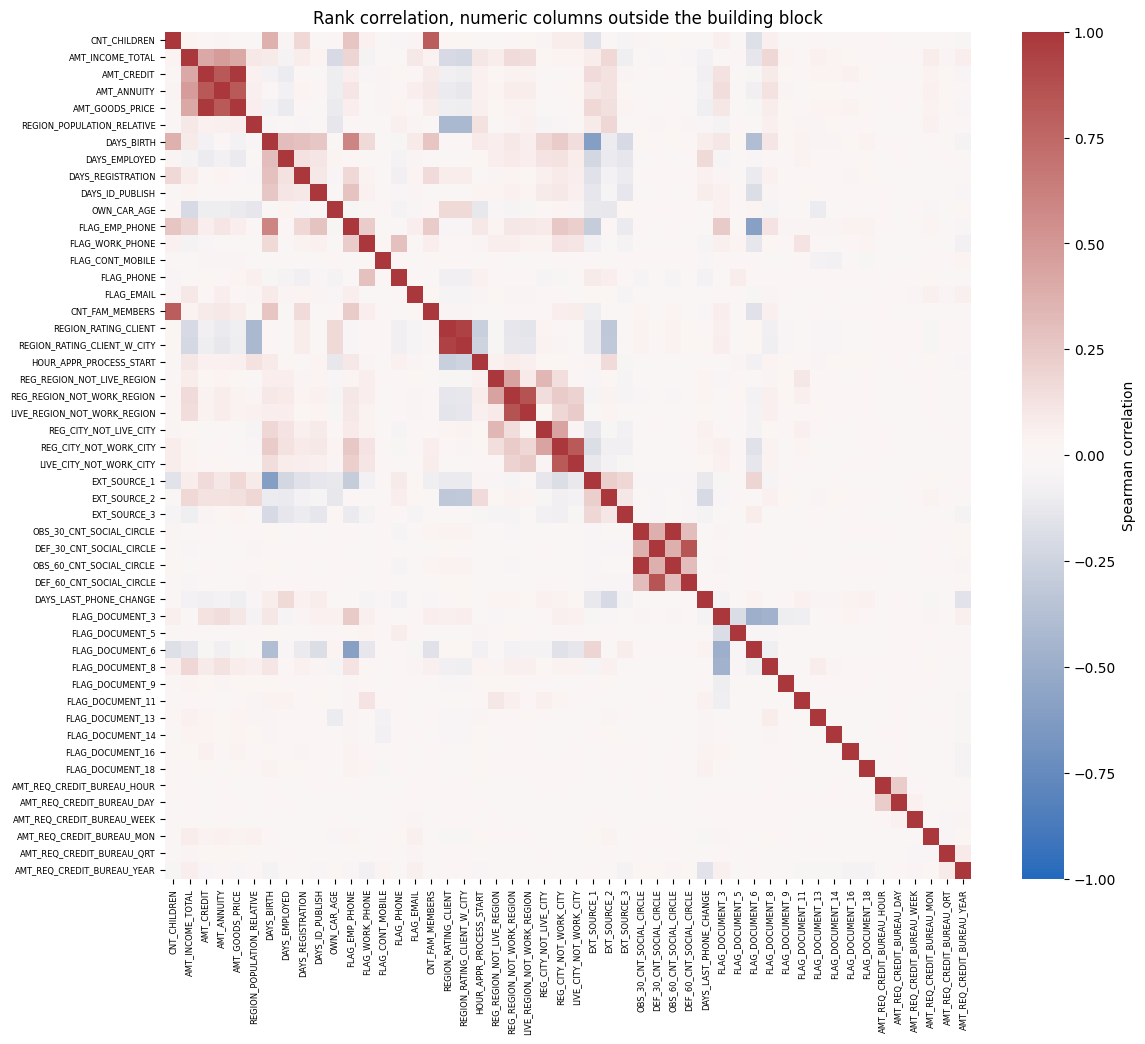

In [90]:
core_corr_cols = [c for c in corr_cols if col_info.loc[c, 'group'] != 'building']
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(rho.loc[core_corr_cols, core_corr_cols], cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={'label': 'Spearman correlation'})
ax.tick_params(labelsize=6)
ax.set_title('Rank correlation, numeric columns outside the building block')
plt.show()

### 9.2 Redundant clusters

Columns are clustered so that members of a cluster have an average absolute correlation of at least 0.8 with each other. Within each cluster, the member with the highest single-feature AUC from stage 8 is the natural one to keep.

In [91]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

distance = 1 - rho.abs().values
np.fill_diagonal(distance, 0)
labels = fcluster(linkage(squareform(distance, checks=False), method='average'), t=0.2, criterion='distance')

rows = []
for label in np.unique(labels):
    members = [c for c, l in zip(corr_cols, labels) if l == label]
    if len(members) < 2:
        continue
    sub = rho.loc[members, members].abs().values
    aucs = ranking.loc[members, 'oof_auc']
    rows.append({'size': len(members), 'group': ', '.join(sorted({col_info.loc[m, 'group'] for m in members})),
                 'lowest_pair_corr': sub[np.triu_indices(len(members), k=1)].min(),
                 'keep': aucs.idxmax(), 'best_auc': aucs.max(), 'worst_auc': aucs.min(),
                 'members': ', '.join(aucs.sort_values(ascending=False).index)})
clusters = pd.DataFrame(rows).sort_values('size', ascending=False).reset_index(drop=True)
print(f"{len(clusters)} clusters covering {clusters['size'].sum()} columns. Keeping one per cluster removes {clusters['size'].sum() - len(clusters)}.")
with pd.option_context('display.max_colwidth', 200):
    display(clusters.round(4))

17 clusters covering 58 columns. Keeping one per cluster removes 41.


,size,group,lowest_pair_corr,keep,best_auc,worst_auc,members
0,10,building,0.8532,TOTALAREA_MODE,0.5480,0.5274,"TOTALAREA_MODE, LIVINGAREA_AVG, LIVINGAREA_MEDI, LIVINGAREA_MODE, APARTMENTS_AVG, APARTMENTS_MEDI, APARTMENTS_MODE, LIVINGAPARTMENTS_MEDI, LIVINGAPARTMENTS_AVG, LIVINGAPARTMENTS_MODE"
1,6,building,0.8170,FLOORSMAX_AVG,0.5481,0.5434,"FLOORSMAX_AVG, FLOORSMAX_MEDI, FLOORSMAX_MODE, ELEVATORS_AVG, ELEVATORS_MEDI, ELEVATORS_MODE"
2,6,building,0.9690,YEARS_BEGINEXPLUATATION_MEDI,0.5441,0.5290,"YEARS_BEGINEXPLUATATION_MEDI, YEARS_BEGINEXPLUATATION_AVG, YEARS_BEGINEXPLUATATION_MODE, YEARS_BUILD_MEDI, YEARS_BUILD_MODE, YEARS_BUILD_AVG"
3,3,building,0.9826,FLOORSMIN_AVG,0.5283,0.5274,"FLOORSMIN_AVG, FLOORSMIN_MEDI, FLOORSMIN_MODE"
4,3,building,0.9323,NONLIVINGAPARTMENTS_MEDI,0.5241,0.5238,"NONLIVINGAPARTMENTS_MEDI, NONLIVINGAPARTMENTS_AVG, NONLIVINGAPARTMENTS_MODE"
5,3,building,0.9579,ENTRANCES_MEDI,0.5434,0.5430,"ENTRANCES_MEDI, ENTRANCES_AVG, ENTRANCES_MODE"
6,3,building,0.9599,BASEMENTAREA_MEDI,0.5366,0.5365,"BASEMENTAREA_MEDI, BASEMENTAREA_AVG, BASEMENTAREA_MODE"
7,3,building,0.9673,LANDAREA_AVG,0.5325,0.5320,"LANDAREA_AVG, LANDAREA_MEDI, LANDAREA_MODE"
8,3,building,0.9185,NONLIVINGAREA_AVG,0.5381,0.5378,"NONLIVINGAREA_AVG, NONLIVINGAREA_MODE, NONLIVINGAREA_MEDI"
9,3,loan,0.8281,AMT_GOODS_PRICE,0.5626,0.5433,"AMT_GOODS_PRICE, AMT_CREDIT, AMT_ANNUITY"


### 9.3 The building block

47 columns: 14 measures in three versions each (`_AVG`, `_MODE`, `_MEDI`), `TOTALAREA_MODE`, and four text columns.

In [92]:
# are the three versions of each measure the same thing?
measures = sorted({c.rsplit('_', 1)[0] for c in building_num if c != 'TOTALAREA_MODE'})
rows = []
for m in measures:
    trio = [f"{m}_AVG", f"{m}_MODE", f"{m}_MEDI"]
    r = rho.loc[trio, trio]
    present = app_clean[trio].dropna()
    rows.append({'measure': m, 'avg_vs_medi': r.loc[trio[0], trio[2]], 'avg_vs_mode': r.loc[trio[0], trio[1]],
                 'mode_vs_medi': r.loc[trio[1], trio[2]],
                 'avg_equals_medi_pct': (present[trio[0]] == present[trio[2]]).mean() * 100,
                 'auc_avg': ranking.loc[trio[0], 'oof_auc'], 'auc_mode': ranking.loc[trio[1], 'oof_auc'],
                 'auc_medi': ranking.loc[trio[2], 'oof_auc']})
versions = pd.DataFrame(rows).set_index('measure')
print(f"lowest correlation between any two versions of the same measure: {versions[['avg_vs_medi', 'avg_vs_mode', 'mode_vs_medi']].min().min():.3f}")
versions.round(4)

lowest correlation between any two versions of the same measure: 0.919


,avg_vs_medi,avg_vs_mode,mode_vs_medi,avg_equals_medi_pct,auc_avg,auc_mode,auc_medi
measure,,,,,,,
APARTMENTS,0.9952,0.9648,0.9700,1.9815,0.5449,0.5439,0.5447
BASEMENTAREA,0.9949,0.9599,0.9634,94.2368,0.5366,0.5365,0.5366
COMMONAREA,0.9957,0.9655,0.9709,25.3783,0.5255,0.5249,0.5255
ELEVATORS,0.9910,0.9688,0.9778,96.3034,0.5442,0.5434,0.5436
ENTRANCES,0.9934,0.9579,0.9652,95.0093,0.5433,0.5430,0.5434
FLOORSMAX,0.9949,0.9816,0.9865,96.4503,0.5481,0.5478,0.5480
FLOORSMIN,0.9962,0.9826,0.9864,96.9444,0.5283,0.5274,0.5282
LANDAREA,0.9963,0.9673,0.9708,13.1531,0.5325,0.5320,0.5321
LIVINGAPARTMENTS,0.9962,0.9697,0.9737,1.1787,0.5278,0.5274,0.5278


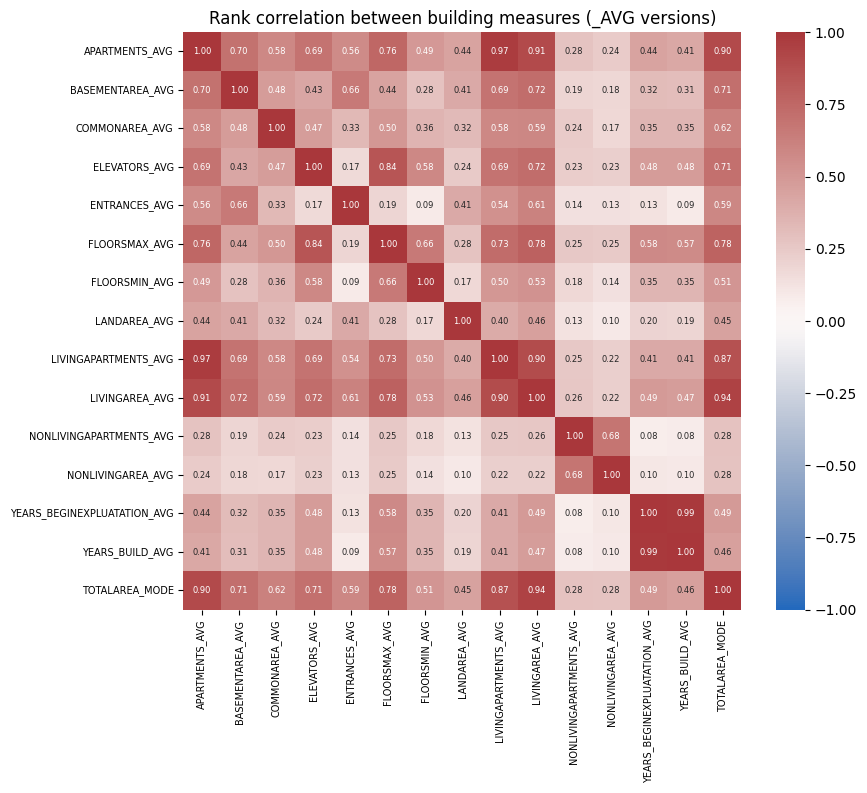

In [93]:
# and how much do the 14 different measures overlap with each other?
avg_only = [f"{m}_AVG" for m in measures] + ['TOTALAREA_MODE']
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(rho.loc[avg_only, avg_only], cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 6}, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title('Rank correlation between building measures (_AVG versions)')
plt.show()

In [94]:
# how many independent directions are there in the 43 numeric building columns?
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

complete = app_clean[building_num].dropna()
print(f"rows with all 43 numeric building columns present: {len(complete):,} ({len(complete) / len(app_clean):.1%})")
explained = np.cumsum(PCA().fit(StandardScaler().fit_transform(complete)).explained_variance_ratio_)
for share in [0.5, 0.8, 0.9, 0.95, 0.99]:
    print(f"  components needed for {share:.0%} of the variance: {np.argmax(explained >= share) + 1}")
print('  variance explained by the first five components:', np.round(explained[:5], 3).tolist())

rows with all 43 numeric building columns present: 81,552 (26.5%)
  components needed for 50% of the variance: 2
  components needed for 80% of the variance: 6
  components needed for 90% of the variance: 9
  components needed for 95% of the variance: 10
  components needed for 99% of the variance: 17
  variance explained by the first five components: [0.45, 0.569, 0.647, 0.718, 0.77]


**Model check.** A gradient boosting model is trained on building columns only, with the same five folds, using progressively smaller subsets. If a smaller subset scores the same, the dropped columns were redundant. `difference` is against the full block, fold by fold.

In [95]:
from sklearn.ensemble import HistGradientBoostingClassifier

def model_matrix(cols):
    X = app_clean[cols].copy()
    is_cat = [not pd.api.types.is_numeric_dtype(X[c]) for c in cols]
    for c, cat in zip(cols, is_cat):
        if cat:
            codes = pd.factorize(X[c])[0].astype(float)
            codes[codes < 0] = np.nan
            X[c] = codes
    return X.to_numpy(dtype=float), is_cat

def cv_auc(cols, extra=None, max_iter=200):
    # extra: optional array of additional numeric columns to append
    X, is_cat = model_matrix(cols) if cols else (np.empty((len(app_clean), 0)), [])
    if extra is not None:
        X = np.column_stack([X, extra])
        is_cat = is_cat + [False] * (X.shape[1] - len(is_cat))
    aucs = []
    for k in range(5):
        train, val = fold_id != k, fold_id == k
        model = HistGradientBoostingClassifier(max_iter=max_iter, learning_rate=0.1, early_stopping=False, random_state=0,
                                               categorical_features=is_cat if any(is_cat) else None)
        model.fit(X[train], y_arr[train])
        aucs.append(roc_auc_score(y_arr[val], model.predict_proba(X[val])[:, 1]))
    return np.array(aucs)

def compare(results, reference):
    out = pd.DataFrame({name: {'features': n, 'mean_auc': a.mean(), 'fold_std': a.std(ddof=1),
                               'difference': (a - results[reference][1]).mean(),
                               'folds_better': int((a > results[reference][1]).sum())}
                        for name, (n, a) in results.items()}).T
    return out

building_all = groups['building']
building_text = [c for c in building_all if c not in building_num]
n_building_missing_arr = app_clean[building_all].isna().sum(axis=1).values.reshape(-1, 1)
top3 = ['FLOORSMAX_AVG', 'LIVINGAREA_AVG', 'TOTALAREA_MODE']

building_tests = {
    'all 47 columns': (47, cv_auc(building_all)),
    '_AVG versions + total area + 4 text': (len(avg_only) + 4, cv_auc(avg_only + building_text)),
    '_AVG versions + total area': (len(avg_only), cv_auc(avg_only)),
    '3 best columns + missing count': (4, cv_auc(top3, extra=n_building_missing_arr)),
    'missing count only': (1, cv_auc([], extra=n_building_missing_arr)),
}
compare(building_tests, 'all 47 columns').round(4)

,features,mean_auc,fold_std,difference,folds_better
all 47 columns,47.0,0.5458,0.0035,0.0000,0.0
_AVG versions + total area + 4 text,19.0,0.5465,0.0036,0.0008,3.0
_AVG versions + total area,15.0,0.5471,0.0026,0.0013,4.0
3 best columns + missing count,4.0,0.5448,0.0030,-0.0010,2.0
missing count only,1.0,0.5395,0.0013,-0.0062,0.0


### 9.4 The amount columns

In [96]:
print('Spearman')
print(rho.loc[amounts, amounts].round(3))
print('\nPearson')
print(app_clean[amounts].corr().round(3))

ratio = app_clean['AMT_CREDIT'] / app_clean['AMT_GOODS_PRICE']
print(f"\ncredit equals goods price exactly: {(ratio == 1).mean():.1%}")
print(f"credit above goods price:          {(ratio > 1).mean():.1%}")
print(f"credit below goods price:          {(ratio < 1).mean():.1%}")
print(ratio.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(3).to_string())

Spearman
                  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE
AMT_INCOME_TOTAL             1.000       0.412        0.482            0.416
AMT_CREDIT                   0.412       1.000        0.830            0.985
AMT_ANNUITY                  0.482       0.830        1.000            0.828
AMT_GOODS_PRICE              0.416       0.985        0.828            1.000

Pearson
                  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE
AMT_INCOME_TOTAL             1.000       0.342        0.418            0.349
AMT_CREDIT                   0.342       1.000        0.770            0.987
AMT_ANNUITY                  0.418       0.770        1.000            0.775
AMT_GOODS_PRICE              0.349       0.987        0.775            1.000

credit equals goods price exactly: 35.2%
credit above goods price:          64.6%
credit below goods price:          0.1%
count    307233.000
mean          1.123
std           0.124
min           0.150
1%       

In [97]:
# when two columns are nearly the same, the information is in how they differ
band = pd.cut(ratio, [0, 0.999, 1.001, 1.05, 1.10, 1.15, 1.20, 1.30, 10], labels=['below 1', 'exactly 1', '1 to 1.05', '1.05 to 1.10', '1.10 to 1.15', '1.15 to 1.20', '1.20 to 1.30', 'over 1.30'])
by_ratio = y.groupby(band, observed=True).agg(rows='size', default_pct='mean')
by_ratio['default_pct'] = (by_ratio['default_pct'] * 100).round(2)
by_ratio.index.name = 'credit / goods price'
print(by_ratio)

ratios = {
    'AMT_CREDIT / AMT_GOODS_PRICE': ratio,
    'AMT_ANNUITY / AMT_CREDIT': app_clean['AMT_ANNUITY'] / app_clean['AMT_CREDIT'],
    'AMT_CREDIT / AMT_ANNUITY (term)': app_clean['AMT_CREDIT'] / app_clean['AMT_ANNUITY'],
    'AMT_CREDIT / AMT_INCOME_TOTAL': app_clean['AMT_CREDIT'] / app_clean['AMT_INCOME_TOTAL'],
    'AMT_ANNUITY / AMT_INCOME_TOTAL': app_clean['AMT_ANNUITY'] / app_clean['AMT_INCOME_TOTAL'],
    'AMT_GOODS_PRICE / AMT_INCOME_TOTAL': app_clean['AMT_GOODS_PRICE'] / app_clean['AMT_INCOME_TOTAL'],
}
amount_auc = pd.concat([
    pd.DataFrame({name: {'oof_auc': oof_auc(s)[0], 'kind': 'ratio'} for name, s in ratios.items()}).T,
    ranking.loc[amounts, ['oof_auc']].assign(kind='raw column'),
]).sort_values('oof_auc', ascending=False)
amount_auc['oof_auc'] = amount_auc['oof_auc'].astype(float).round(4)
amount_auc

                        rows  default_pct
credit / goods price                     
below 1                  260         5.00
exactly 1             108210         6.75
1 to 1.05               1687         2.61
1.05 to 1.10           25474         5.28
1.10 to 1.15           54799         7.07
1.15 to 1.20           52120         8.91
1.20 to 1.30           35159        10.80
over 1.30              29524        12.82


,oof_auc,kind
AMT_ANNUITY / AMT_CREDIT,0.6058,ratio
AMT_CREDIT / AMT_ANNUITY (term),0.5821,ratio
AMT_CREDIT / AMT_GOODS_PRICE,0.5707,ratio
AMT_GOODS_PRICE,0.5626,raw column
AMT_CREDIT,0.5605,raw column
AMT_ANNUITY,0.5433,raw column
AMT_GOODS_PRICE / AMT_INCOME_TOTAL,0.5323,ratio
AMT_CREDIT / AMT_INCOME_TOTAL,0.5286,ratio
AMT_INCOME_TOTAL,0.5245,raw column
AMT_ANNUITY / AMT_INCOME_TOTAL,0.5207,ratio


### 9.5 Other near-duplicate pairs

For each pair: how often the two columns hold the same value, the single-feature AUC of each, and the AUC of the difference between them. If the difference scores near 0.5, the second column adds nothing.

In [98]:
pairs_to_check = [
    ('REGION_RATING_CLIENT_W_CITY', 'REGION_RATING_CLIENT'),
    ('OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE'),
    ('DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE'),
    ('CNT_FAM_MEMBERS', 'CNT_CHILDREN'),
    ('REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION'),
    ('REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY'),
    ('AMT_CREDIT', 'AMT_GOODS_PRICE'),
]
rows = []
for a, b in pairs_to_check:
    both = app_clean[[a, b]].dropna()
    diff = app_clean[a] - app_clean[b]
    rows.append({'a': a, 'b': b, 'rho': rho.loc[a, b], 'identical_pct': (both[a] == both[b]).mean() * 100,
                 'auc_a': ranking.loc[a, 'oof_auc'], 'auc_b': ranking.loc[b, 'oof_auc'],
                 'auc_of_difference': oof_auc(diff)[0], 'distinct_differences': diff.nunique()})
pd.DataFrame(rows).round(4)

,a,b,rho,identical_pct,auc_a,auc_b,auc_of_difference,distinct_differences
0,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,0.9500,98.1406,0.5492,0.5481,0.5008,3
1,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.9973,98.3552,0.5089,0.5088,0.5017,4
2,DEF_30_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,0.8451,96.1186,0.5197,0.5166,0.5055,6
3,CNT_FAM_MEMBERS,CNT_CHILDREN,0.8116,0.0000,0.5186,0.5175,0.5099,2
4,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,0.8606,98.7327,0.5028,0.5010,0.5018,3
5,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,0.8256,93.9631,0.5394,0.5229,0.5178,3
6,AMT_CREDIT,AMT_GOODS_PRICE,0.9849,35.2208,0.5605,0.5626,0.5501,2911


In [99]:
# five columns that all say "this applicant has no employer"
no_employer = pd.DataFrame({
    'DAYS_EMPLOYED missing': app_clean['DAYS_EMPLOYED'].isna(),
    'ORGANIZATION_TYPE is XNA': app_clean['ORGANIZATION_TYPE'] == 'XNA',
    'FLAG_EMP_PHONE is 0': app_clean['FLAG_EMP_PHONE'] == 0,
    'OCCUPATION_TYPE missing': app_clean['OCCUPATION_TYPE'].isna(),
    'income type Pensioner or Unemployed': app_clean['NAME_INCOME_TYPE'].isin(['Pensioner', 'Unemployed']),
})
print(no_employer.sum().to_string())
print('\nagreement with "DAYS_EMPLOYED missing" (share of rows where the two indicators match)')
print(no_employer.apply(lambda s: (s == no_employer['DAYS_EMPLOYED missing']).mean()).round(5).to_string())

DAYS_EMPLOYED missing                  55374
ORGANIZATION_TYPE is XNA               55374
FLAG_EMP_PHONE is 0                    55386
OCCUPATION_TYPE missing                96391
income type Pensioner or Unemployed    55384

agreement with "DAYS_EMPLOYED missing" (share of rows where the two indicators match)
DAYS_EMPLOYED missing                  1.00000
ORGANIZATION_TYPE is XNA               1.00000
FLAG_EMP_PHONE is 0                    0.99996
OCCUPATION_TYPE missing                0.86660
income type Pensioner or Unemployed    0.99997


### 9.6 Associations between categorical columns

Cramér's V between every pair of text columns, with missing as a level. 0 means unrelated and 1 means one column determines the other.

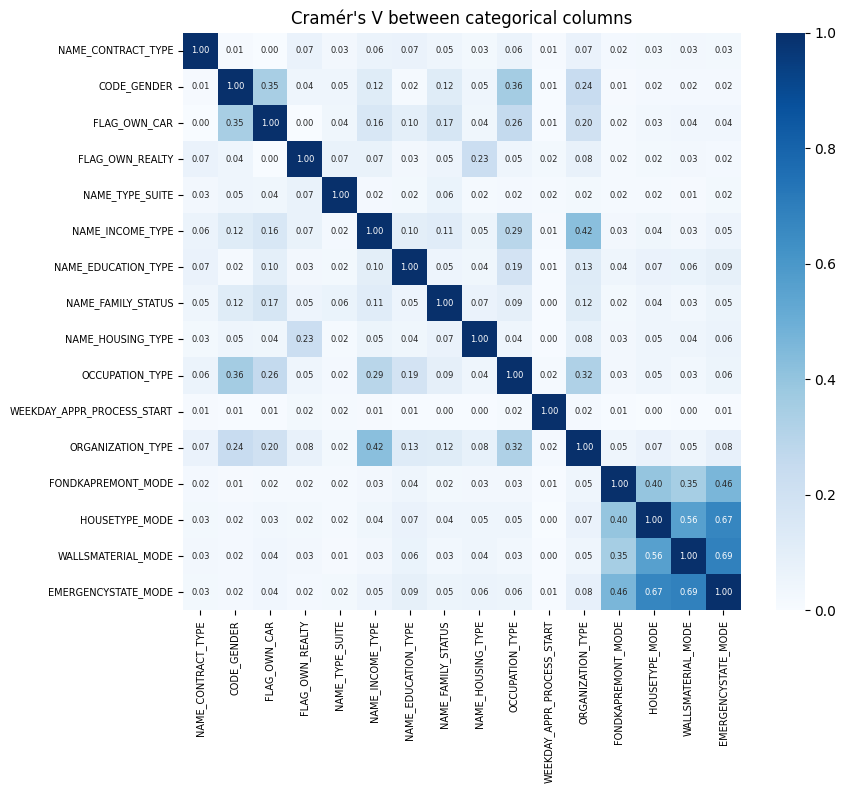

,a,b,cramers_v
0,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,0.689
1,HOUSETYPE_MODE,EMERGENCYSTATE_MODE,0.669
2,HOUSETYPE_MODE,WALLSMATERIAL_MODE,0.560
3,FONDKAPREMONT_MODE,EMERGENCYSTATE_MODE,0.461
4,NAME_INCOME_TYPE,ORGANIZATION_TYPE,0.422
5,FONDKAPREMONT_MODE,HOUSETYPE_MODE,0.396
6,CODE_GENDER,OCCUPATION_TYPE,0.359
7,FONDKAPREMONT_MODE,WALLSMATERIAL_MODE,0.350
8,CODE_GENDER,FLAG_OWN_CAR,0.346
9,OCCUPATION_TYPE,ORGANIZATION_TYPE,0.323


In [100]:
v = pd.DataFrame(np.eye(len(cat_cols)), index=cat_cols, columns=cat_cols)
for i, a in enumerate(cat_cols):
    for b in cat_cols[i + 1:]:
        v.loc[a, b] = v.loc[b, a] = cramers_v(cats[a], cats[b])[0]

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(v, cmap='Blues', vmin=0, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 6}, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title("Cramér's V between categorical columns")
plt.show()

v_pairs = v.where(np.triu(np.ones(v.shape, dtype=bool), k=1)).stack().rename('cramers_v').reset_index()
v_pairs.columns = ['a', 'b', 'cramers_v']
v_pairs[v_pairs['cramers_v'] >= 0.25].sort_values('cramers_v', ascending=False).round(3).reset_index(drop=True)

### 9.7 Does removing the redundant columns cost anything?

The same model on three feature sets, with identical folds:
- **all 120** features;
- **reduced**: the 20 columns dropped in stage 8 removed, plus the `_MODE` and `_MEDI` building versions, `OBS_60_CNT_SOCIAL_CIRCLE` and `REGION_RATING_CLIENT`;
- **compact**: as reduced, with the whole building block replaced by its three best columns and the count of missing building columns.

This is a check on the drop list, not the baseline model. No cleaning beyond stage 4 and no engineered features are used.

In [101]:
drop_stage8 = (flag_signal.index[flag_signal['verdict'].isin(['near-constant', 'no signal'])].tolist()
               + ['FLAG_OWN_REALTY', 'WEEKDAY_APPR_PROCESS_START',
                  'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK'])
drop_versions = [c for c in building_num if c.endswith(('_MODE', '_MEDI')) and c != 'TOTALAREA_MODE']
drop_pairs = ['OBS_60_CNT_SOCIAL_CIRCLE', 'REGION_RATING_CLIENT']

reduced = [c for c in features if c not in drop_stage8 + drop_versions + drop_pairs]
compact = [c for c in reduced if col_info.loc[c, 'group'] != 'building'] + top3
print(len(features), 'all,', len(reduced), 'reduced,', len(compact), 'compact (plus the missing count)')

set_tests = {
    'all 120': (len(features), cv_auc(features)),
    'reduced': (len(reduced), cv_auc(reduced)),
    'compact': (len(compact) + 1, cv_auc(compact, extra=n_building_missing_arr)),
}
print('fold AUCs')
print(pd.DataFrame({name: a for name, (n, a) in set_tests.items()}).round(4).to_string())
compare(set_tests, 'all 120').round(4)

120 all, 70 reduced, 54 compact (plus the missing count)


fold AUCs
   all 120  reduced  compact
0   0.7513   0.7505   0.7513
1   0.7622   0.7611   0.7623
2   0.7538   0.7533   0.7536
3   0.7604   0.7594   0.7589
4   0.7517   0.7525   0.7519


,features,mean_auc,fold_std,difference,folds_better
all 120,120.0,0.7559,0.0051,0.0000,0.0
reduced,70.0,0.7554,0.0046,-0.0005,1.0
compact,55.0,0.7556,0.0048,-0.0003,2.0


### Stage 9 findings

**How much redundancy there is**
- Among 93 numeric columns there are 105 pairs with a rank correlation of 0.8 or more. 96 of them are inside the building block.
- Clustering at an average correlation of 0.8 gives 17 clusters covering 58 columns. Keeping one column per cluster would remove 41.
- Outside the building block the table is mostly independent: only 9 pairs reach 0.8, and 3,344 of 3,375 pairs are below 0.3.

**The building block**
- The three versions of each measure are the same thing. `_AVG` and `_MEDI` correlate at 0.98 or more for every measure, the lowest correlation between any two versions is 0.92, and their single-feature AUCs agree to the third decimal.
- The measures also overlap with each other. Total area, living area, apartments and living apartments form one cluster of 10 columns. Maximum floors and elevators form another. The two "years" measures form a third.
- The 43 numeric columns behave like about 10: nine principal components hold 90% of the variance and two hold 57%.
- Model check, building columns only:

| Subset | Columns | AUC |
|---|---:|---:|
| All building columns | 47 | 0.5458 |
| `_AVG` versions, total area, 4 text columns | 19 | 0.5465 |
| `_AVG` versions and total area | 15 | 0.5471 |
| 3 best columns and the missing count | 4 | 0.5448 |
| Missing count only | 1 | 0.5395 |

- Cutting 47 columns to 15 loses nothing. Cutting to 4 costs 0.001, which is inside the fold-to-fold noise. The missing count alone gives up 0.006.
- The whole block is worth an AUC of about 0.546 on its own, which confirms stage 8: it is a weak group however it is sliced.

**The amount columns**
- `AMT_CREDIT` and `AMT_GOODS_PRICE` correlate at 0.985, and both correlate with `AMT_ANNUITY` at 0.83. Income is only loosely related to the other three (0.41 to 0.48).
- The information is in how they differ. Credit exactly equals the goods price for 35.2% of applicants and exceeds it for 64.6%. The default rate rises steadily with the excess: 6.8% when equal, 8.9% at 15% to 20% above, 12.8% beyond 30% above. The ratio scores 0.571 alone, better than either column.
- `AMT_ANNUITY / AMT_CREDIT` is the strongest thing found so far outside the external scores. It scores 0.58 to 0.61 with ten bins and 0.64 with fifty bins, against 0.53 as a straight score.
- The ratios to income are weak on their own (0.52 to 0.53).

**A caveat on the ten-bin measure**
- `AMT_ANNUITY / AMT_CREDIT` and its inverse hold identical information, yet they score 0.606 and 0.582 in the table. 9.5% of applicants (the revolving loans) sit at exactly 0.05, and which neighbours that block is binned with changes the result.
- So the stage 8 measure can understate columns with heavy ties or fine structure by a few hundredths. It is a ranking tool, not a precise score. A tree model is not limited to ten bins.

**Other near-duplicate pairs**

| Pair | Identical on | AUC of the difference | Verdict |
|---|---:|---:|---|
| The two region ratings | 98.1% | 0.501 | Keep `REGION_RATING_CLIENT_W_CITY` |
| `OBS_30` and `OBS_60` social circle | 98.4% | 0.502 | Keep `OBS_30` |
| `DEF_30` and `DEF_60` social circle | 96.1% | 0.506 | Keep `DEF_30` |
| The two "not work region" flags | 98.7% | 0.502 | Both already dropped or at the noise floor |
| The two "not work city" flags | 94.0% | 0.518 | Keep both, the difference has some signal |
| Family members and children | never | 0.510 | Keep both. The difference is the number of adults |

- Four columns say "no employer" and agree on at least 99.996% of rows: missing `DAYS_EMPLOYED`, `ORGANIZATION_TYPE = XNA`, `FLAG_EMP_PHONE = 0`, and income type pensioner or unemployed. Missing `OCCUPATION_TYPE` is broader (87% agreement).

**Categorical columns**
- No text column duplicates another. The highest associations are among the building text columns (0.35 to 0.69), which share their missing rows.
- Elsewhere: income type with organisation type 0.42, gender with occupation 0.36, gender with car ownership 0.35.

**Does removing the redundant columns cost anything?**

| Feature set | Columns | AUC | Against all 120 |
|---|---:|---:|---:|
| All features | 120 | 0.7559 | |
| Reduced | 70 | 0.7554 | -0.0005 |
| Compact (building block cut to 4) | 55 | 0.7556 | -0.0003 |

- Removing 50 to 65 columns changes the AUC by 0.0005 or less, against a fold-to-fold standard deviation of 0.005.
- The reduced set is lower in four of the five folds, so there is a real cost. It is just very small.
- An untuned model on the cleaned raw columns already scores 0.756, against the single-number baseline of 0.7165 from stage 2.

**Decisions**
- Building block: keep `FLOORSMAX_AVG`, `LIVINGAREA_AVG` and `TOTALAREA_MODE` plus the count of missing building columns, and drop the other 44. If a fuller version is wanted, the 15 `_AVG` columns are the limit. The `_MODE` and `_MEDI` versions are never needed.
- Drop `REGION_RATING_CLIENT`, `OBS_60_CNT_SOCIAL_CIRCLE` and `DEF_60_CNT_SOCIAL_CIRCLE`.
- Keep all four amount columns and add the ratios in stage 11: credit to goods price, annuity to credit, credit to income, annuity to income.
- Keep one "no employer" signal for linear models. Tree models are not harmed by the repeats.
- The compact set of 55 columns is the working feature list going into stage 11.
- Redundancy matters more for linear models, where correlated columns make coefficients unstable, and for explanations, where importance gets split across duplicates. For a tree model's accuracy alone it is nearly free either way.

## Stage 10: Train vs test

Distribution shift, and categories present in only one file.

The model is trained on `application_train.csv` and scored on `application_test.csv`. If the two files describe different populations, a validation score measured on train will not carry over. This stage measures how different they are, which columns drive the difference, and whether it matters for the target.

### 10.1 Structure and cleaning

In [102]:
test = pd.read_csv('../data/raw/application_test.csv')
test_clean = clean_application(test)

print('train:', app.shape, ' test:', test.shape)
print('columns only in train:', sorted(set(app.columns) - set(test.columns)))
print('columns only in test: ', sorted(set(test.columns) - set(app.columns)))
print('same column order:', list(app.columns.drop('TARGET')) == list(test.columns))
mismatched = [c for c in test.columns if app[c].dtype != test[c].dtype]
print('columns with a different dtype:', {c: (str(app[c].dtype), str(test[c].dtype)) for c in mismatched})
print('SK_ID_CURR unique in test:', test['SK_ID_CURR'].is_unique, ' shared with train:', len(set(app['SK_ID_CURR']) & set(test['SK_ID_CURR'])))
print(f"test is {len(test) / (len(app) + len(test)):.1%} of all applications")

changed = (test_clean.isna().sum() - test.isna().sum())
print('\ncells set to missing by clean_application on test:')
print(changed[changed > 0].to_string())
print(f"DAYS_EMPLOYED placeholder share: train {placeholder.mean():.2%}, test {(test['DAYS_EMPLOYED'] == 365243).mean():.2%}")

train: (307511, 122)  test: (48744, 121)
columns only in train: ['TARGET']
columns only in test:  []
same column order: True
columns with a different dtype: {}
SK_ID_CURR unique in test: True  shared with train: 0
test is 13.7% of all applications

cells set to missing by clean_application on test:
DAYS_EMPLOYED               9274
OBS_30_CNT_SOCIAL_CIRCLE       3
DEF_30_CNT_SOCIAL_CIRCLE       3
OBS_60_CNT_SOCIAL_CIRCLE       3
DEF_60_CNT_SOCIAL_CIRCLE       3
DAYS_EMPLOYED placeholder share: train 18.01%, test 19.03%


In [103]:
# values in test that never occur in train, for discrete and binary numeric columns
rows = []
for c in features:
    if col_info.loc[c, 'semantic_type'] in ('discrete', 'binary') and pd.api.types.is_numeric_dtype(app_clean[c]):
        unseen = sorted(set(test_clean[c].dropna().unique()) - set(app_clean[c].dropna().unique()))
        if unseen:
            rows.append({'column': c, 'values_unseen_in_train': unseen, 'test_rows': int(test_clean[c].isin(unseen).sum())})
print(pd.DataFrame(rows).to_string(index=False) if rows else 'none')

# continuous columns: test rows outside the train range
rows = []
for c in features:
    if col_info.loc[c, 'semantic_type'] == 'continuous':
        outside = (test_clean[c] < app_clean[c].min()) | (test_clean[c] > app_clean[c].max())
        if outside.any():
            rows.append({'column': c, 'test_rows_outside_train_range': int(outside.sum()),
                         'train_range': (app_clean[c].min(), app_clean[c].max()), 'test_range': (test_clean[c].min(), test_clean[c].max())})
print()
print(pd.DataFrame(rows).to_string(index=False) if rows else 'no continuous column goes outside the train range')

                     column values_unseen_in_train  test_rows
               CNT_CHILDREN                   [20]          1
            CNT_FAM_MEMBERS                 [21.0]          1
REGION_RATING_CLIENT_W_CITY                   [-1]          1

                    column  test_rows_outside_train_range                             train_range                               test_range
REGION_POPULATION_RELATIVE                              1                     (0.00029, 0.072508)           (0.0002529999999999, 0.072508)
                DAYS_BIRTH                              2                         (-25229, -7489)                          (-25195, -7338)
              EXT_SOURCE_1                              1 (0.0145681324124455, 0.962692770561306) (0.0134579104986917, 0.9391445326561508)
    DAYS_LAST_PHONE_CHANGE                              1                          (-4292.0, 0.0)                           (-4361.0, 0.0)


### 10.2 Missing values

In [104]:
miss_cmp = pd.DataFrame({
    'group': col_info.loc[features, 'group'],
    'train_missing_pct': app_clean[features].isna().mean() * 100,
    'test_missing_pct': test_clean[features].isna().mean() * 100,
})
miss_cmp['difference_pts'] = miss_cmp['test_missing_pct'] - miss_cmp['train_missing_pct']
print(f"cells missing overall: train {app_clean[features].isna().values.mean():.1%}, test {test_clean[features].isna().values.mean():.1%}")
print('columns missing in one file only:', miss_cmp.index[(miss_cmp['train_missing_pct'] == 0) != (miss_cmp['test_missing_pct'] == 0)].tolist())
print(miss_cmp.groupby('group')['difference_pts'].mean().round(2).sort_values().to_string())
miss_cmp.sort_values('difference_pts', key=abs, ascending=False).head(12).round(2)

cells missing overall: train 25.0%, test 24.2%
columns missing in one file only: ['CODE_GENDER', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'NAME_FAMILY_STATUS', 'CNT_FAM_MEMBERS', 'DAYS_LAST_PHONE_CHANGE']
group
external_scores     -5.50
building            -1.56
bureau_enquiries    -1.09
social_circle       -0.27
loan                -0.01
contact              0.00
documents            0.00
address_mismatch     0.00
region               0.00
timing              -0.00
assets_housing       0.07
demographics         0.21
income_employment    0.34


,group,train_missing_pct,test_missing_pct,difference_pts
EXT_SOURCE_1,external_scores,56.38,42.12,-14.26
EXT_SOURCE_3,external_scores,19.83,17.78,-2.04
ENTRANCES_AVG,building,50.35,48.37,-1.98
ENTRANCES_MODE,building,50.35,48.37,-1.98
ENTRANCES_MEDI,building,50.35,48.37,-1.98
FLOORSMAX_MEDI,building,49.76,47.84,-1.92
FLOORSMAX_MODE,building,49.76,47.84,-1.92
FLOORSMAX_AVG,building,49.76,47.84,-1.92
YEARS_BEGINEXPLUATATION_AVG,building,48.78,46.89,-1.89
YEARS_BEGINEXPLUATATION_MODE,building,48.78,46.89,-1.89


### 10.3 Categorical columns: levels in only one file

In [105]:
rows = []
for c in cat_cols:
    tr = app_clean[c].fillna('(missing)').value_counts(normalize=True)
    te = test_clean[c].fillna('(missing)').value_counts(normalize=True)
    shares = pd.DataFrame({'train': tr, 'test': te}).fillna(0)
    gap = (shares['test'] - shares['train'])
    only_train = sorted(set(app_clean[c].dropna()) - set(test_clean[c].dropna()))
    only_test = sorted(set(test_clean[c].dropna()) - set(app_clean[c].dropna()))
    rows.append({'column': c, 'levels_train': app_clean[c].nunique(), 'levels_test': test_clean[c].nunique(),
                 'only_in_train': ', '.join(only_train) or '-', 'train_rows_affected': int(app_clean[c].isin(only_train).sum()),
                 'only_in_test': ', '.join(only_test) or '-',
                 'biggest_shift_level': gap.abs().idxmax(), 'train_pct': shares.loc[gap.abs().idxmax(), 'train'] * 100,
                 'test_pct': shares.loc[gap.abs().idxmax(), 'test'] * 100})
level_cmp = pd.DataFrame(rows).set_index('column')
level_cmp.round(2)

,levels_train,levels_test,only_in_train,train_rows_affected,only_in_test,biggest_shift_level,train_pct,test_pct
column,,,,,,,,
NAME_CONTRACT_TYPE,2,2,-,0,-,Cash loans,90.48,99.10
CODE_GENDER,2,2,-,0,-,F,65.83,67.04
FLAG_OWN_CAR,2,2,-,0,-,N,65.99,66.29
FLAG_OWN_REALTY,2,2,-,0,-,N,30.63,30.95
NAME_TYPE_SUITE,7,7,-,0,-,(missing),0.42,1.87
NAME_INCOME_TYPE,8,7,Maternity leave,5,-,Working,51.63,50.33
NAME_EDUCATION_TYPE,5,5,-,0,-,Higher education,24.34,25.68
NAME_FAMILY_STATUS,5,5,-,0,-,Married,63.88,66.23
NAME_HOUSING_TYPE,6,6,-,0,-,House / apartment,88.73,89.54


### 10.4 Binary flags

In [106]:
flag_cmp = pd.DataFrame({
    'train_ones_pct': app_clean[flag_cols].mean() * 100,
    'test_ones_pct': test_clean[flag_cols].mean() * 100,
    'test_ones_rows': test_clean[flag_cols].sum(),
    'train_verdict': flag_signal['verdict'],
    'train_oof_auc': ranking.loc[flag_cols, 'oof_auc'],
})
flag_cmp['constant_in_test'] = test_clean[flag_cols].nunique() == 1
print('flags constant in test:', int(flag_cmp['constant_in_test'].sum()))
print(pd.crosstab(flag_cmp['train_verdict'], flag_cmp['constant_in_test']))
flag_cmp[flag_cmp['constant_in_test']].sort_values('train_ones_pct', ascending=False).round(4)

flags constant in test: 11
constant_in_test  False  True 
train_verdict                 
near-constant         3      8
no signal             4      0
signal               14      3


,train_ones_pct,test_ones_pct,test_ones_rows,train_verdict,train_oof_auc,constant_in_test
FLAG_DOCUMENT_16,0.9928,0.0,0,signal,0.5021,True
FLAG_DOCUMENT_13,0.3525,0.0,0,signal,0.5013,True
FLAG_DOCUMENT_14,0.2936,0.0,0,signal,0.5009,True
FLAG_DOCUMENT_15,0.1210,0.0,0,near-constant,0.5004,True
FLAG_DOCUMENT_19,0.0595,0.0,0,near-constant,0.5001,True
FLAG_DOCUMENT_20,0.0507,0.0,0,near-constant,0.4999,True
FLAG_DOCUMENT_21,0.0335,0.0,0,near-constant,0.5001,True
FLAG_DOCUMENT_17,0.0267,0.0,0,near-constant,0.5001,True
FLAG_DOCUMENT_2,0.0042,0.0,0,near-constant,0.5001,True
FLAG_DOCUMENT_10,0.0023,0.0,0,near-constant,0.5000,True


In [107]:
# default rate in train for the flags that vanish in test
gone = flag_cmp.index[flag_cmp['constant_in_test'] & (flag_cmp['train_verdict'] == 'signal')].tolist()
flag_signal.loc[gone, ['minority_rows', 'default_pct_when_1', 'default_pct_when_0', 'iv']].round(3)

,minority_rows,default_pct_when_1,default_pct_when_0,iv
flag,,,,
FLAG_DOCUMENT_13,1084,2.768,8.092,0.003
FLAG_DOCUMENT_14,903,3.322,8.087,0.002
FLAG_DOCUMENT_16,3053,4.913,8.105,0.002


### 10.5 Drift score for every feature

Two measures per feature:
- **PSI** (population stability index), the standard drift measure in credit scoring. Train is cut into ten bins (or its levels), and PSI compares the share of train and test in each. Under 0.1 is stable, 0.1 to 0.25 is a moderate shift, above 0.25 is a large shift.
- **Adversarial AUC**: how well the feature alone can tell a test row from a train row, measured out of fold in the same way as stage 8. 0.5 means it cannot.

In [108]:
both = pd.concat([app_clean[features], test_clean[features]], ignore_index=True)
is_test = np.r_[np.zeros(len(app_clean), dtype=int), np.ones(len(test_clean), dtype=int)]
adv_fold = np.empty(len(both), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(both, is_test)):
    adv_fold[val_idx] = k

def group_codes(s, reference):
    # ten bins from the reference rows for high-cardinality numeric columns, the levels otherwise; missing is its own group
    if pd.api.types.is_numeric_dtype(s) and reference.nunique() > 20:
        edges = np.unique(np.nanquantile(reference.values.astype(float), np.linspace(0, 1, 11)))[1:-1]
        values = s.values.astype(float)
        return np.where(np.isnan(values), -1, np.digitize(values, edges))
    return pd.factorize(s)[0]

def psi(col):
    codes = group_codes(both[col], app_clean[col])
    tr = pd.Series(codes[is_test == 0]).value_counts(normalize=True)
    te = pd.Series(codes[is_test == 1]).value_counts(normalize=True)
    shares = pd.DataFrame({'train': tr, 'test': te}).fillna(0) + 1e-4
    return ((shares['test'] - shares['train']) * np.log(shares['test'] / shares['train'])).sum()

def adversarial_auc(col, smoothing=50):
    s = both[col]
    aucs = []
    for k in range(5):
        train, val = adv_fold != k, adv_fold == k
        codes = group_codes(s, s[train])
        prior = is_test[train].mean()
        stats = pd.DataFrame({'code': codes[train], 't': is_test[train]}).groupby('code')['t'].agg(['sum', 'count'])
        rate = (stats['sum'] + smoothing * prior) / (stats['count'] + smoothing)
        aucs.append(roc_auc_score(is_test[val], pd.Series(codes[val]).map(rate).fillna(prior).values))
    return np.mean(aucs)

drift = pd.DataFrame({'group': col_info.loc[features, 'group'], 'type': col_info.loc[features, 'semantic_type'],
                      'psi': [psi(c) for c in features], 'adversarial_auc': [adversarial_auc(c) for c in features],
                      'target_auc': ranking.loc[features, 'oof_auc']}, index=features)
drift['shift'] = pd.cut(drift['psi'], [-1, 0.1, 0.25, 100], labels=['stable', 'moderate', 'large'])
print(drift['shift'].value_counts().to_string())
drift.sort_values('psi', ascending=False).head(25).round(4)

shift
stable      116
moderate      2
large         2


,group,type,psi,adversarial_auc,target_auc,shift
AMT_REQ_CREDIT_BUREAU_MON,bureau_enquiries,discrete,0.4278,0.5813,0.5236,large
AMT_REQ_CREDIT_BUREAU_QRT,bureau_enquiries,discrete,0.3112,0.6297,0.5296,large
NAME_CONTRACT_TYPE,loan,binary,0.2103,0.5431,0.5166,moderate
FLAG_EMAIL,contact,binary,0.1241,0.5530,0.5007,moderate
EXT_SOURCE_1,external_scores,continuous,0.0845,0.5760,0.5879,stable
AMT_GOODS_PRICE,loan,continuous,0.0814,0.5828,0.5626,stable
AMT_CREDIT,loan,continuous,0.0797,0.5752,0.5605,stable
DAYS_ID_PUBLISH,timing,continuous,0.0669,0.5525,0.5550,stable
AMT_REQ_CREDIT_BUREAU_WEEK,bureau_enquiries,discrete,0.0623,0.5197,0.5198,stable
DAYS_LAST_PHONE_CHANGE,timing,continuous,0.0521,0.5658,0.5574,stable


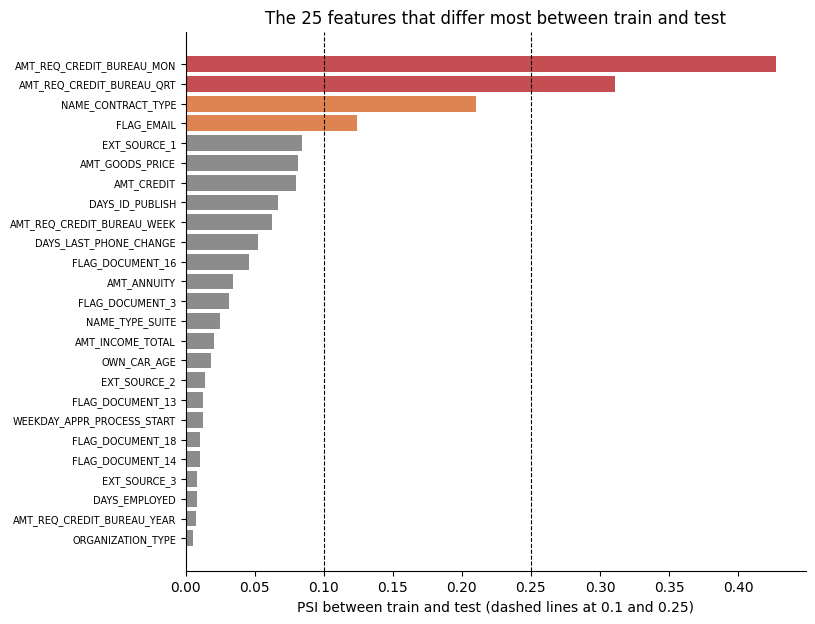

In [109]:
fig, ax = plt.subplots(figsize=(8, 7))
top = drift.sort_values('psi', ascending=False).head(25).iloc[::-1]
ax.barh(top.index, top['psi'], color=top['shift'].astype(str).map({'stable': '#8C8C8C', 'moderate': '#DD8452', 'large': '#C44E52'}))
for x in (0.1, 0.25):
    ax.axvline(x, color='black', linestyle='--', linewidth=0.8)
ax.set_xlabel('PSI between train and test (dashed lines at 0.1 and 0.25)')
ax.set_title('The 25 features that differ most between train and test')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

In [110]:
# the most shifted numeric columns, side by side
shifted_numeric = [c for c in drift.sort_values('psi', ascending=False).index if col_info.loc[c, 'semantic_type'] in ('continuous', 'discrete')][:8]
quantiles = [0.05, 0.25, 0.5, 0.75, 0.95]
rows = {}
for c in shifted_numeric:
    rows[(c, 'train')] = app_clean[c].quantile(quantiles).tolist() + [app_clean[c].isna().mean() * 100]
    rows[(c, 'test')] = test_clean[c].quantile(quantiles).tolist() + [test_clean[c].isna().mean() * 100]
pd.DataFrame(rows, index=['p5', 'p25', 'median', 'p75', 'p95', 'missing_pct']).T.round(3)

p5         p25      median  \
AMT_REQ_CREDIT_BUREAU_MON  train       0.000       0.000       0.000   
                           test        0.000       0.000       0.000   
AMT_REQ_CREDIT_BUREAU_QRT  train       0.000       0.000       0.000   
                           test        0.000       0.000       0.000   
EXT_SOURCE_1               train       0.158       0.334       0.506   
                           test        0.157       0.344       0.507   
AMT_GOODS_PRICE            train  135000.000  238500.000  450000.000   
                           test   103500.000  225000.000  396000.000   
AMT_CREDIT                 train  135000.000  270000.000  513531.000   
                           test   118512.000  260640.000  450000.000   
DAYS_ID_PUBLISH            train   -4944.000   -4299.000   -3254.000   
                           test    -5124.000   -4448.000   -3234.000   
AMT_REQ_CREDIT_BUREAU_WEEK train       0.000       0.000       0.000   
                           test        0.000       0.000       0.000   
DAYS_LAST_PHONE_CHANGE     train   -2522.000   -1570.000    -757.000   
                           test    -2729.850   -1766.250    -863.000   

                                         p75          p95  missing_pct  
AMT_REQ_CREDIT_BUREAU_MON  train       0.000        1.000       13.502  
                           test        0.000        0.000       12.410  
AMT_REQ_CREDIT_BUREAU_QRT  train       0.000        2.000       13.502  
                           test        1.000        2.000       12.410  
EXT_SOURCE_1               train       0.675        0.832       56.381  
                           test        0.666        0.821       42.122  
AMT_GOODS_PRICE            train  679500.000  1305000.000        0.090  
                           test   630000.000  1125000.000        0.000  
AMT_CREDIT                 train  808650.000  1350000.000        0.000  
                           test   675000.000  1258650.000        0.000  
DAYS_ID_PUBLISH            train   -1720.000     -375.000        0.000  
                           test    -1706.000     -381.000        0.000  
AMT_REQ_CREDIT_BUREAU_WEEK train       0.000        0.000       13.502  
                           test        0.000        0.000       12.410  
DAYS_LAST_PHONE_CHANGE     train    -274.000        0.000        0.000  
                           test     -363.000        0.000        0.000

### 10.6 Adversarial validation

A model is trained to tell test rows from train rows using all features together. An AUC of 0.5 would mean the files are indistinguishable. The model is then refitted without the most shifted features to see how much difference is left.

In [111]:
def combined_matrix(cols):
    X = both[cols].copy()
    is_cat = [not pd.api.types.is_numeric_dtype(X[c]) for c in cols]
    for c, cat in zip(cols, is_cat):
        if cat:
            codes = pd.factorize(X[c])[0].astype(float)
            codes[codes < 0] = np.nan
            X[c] = codes
    return X.to_numpy(dtype=float), is_cat

def adversarial_model(cols, max_iter=100):
    X, is_cat = combined_matrix(cols)
    propensity = np.empty(len(X))
    for k in range(5):
        train, val = adv_fold != k, adv_fold == k
        model = HistGradientBoostingClassifier(max_iter=max_iter, learning_rate=0.1, early_stopping=False, random_state=0,
                                               categorical_features=is_cat if any(is_cat) else None)
        model.fit(X[train], is_test[train])
        propensity[val] = model.predict_proba(X[val])[:, 1]
    return roc_auc_score(is_test, propensity), propensity

adv_auc_all, propensity = adversarial_model(features)
print(f"all {len(features)} features: adversarial AUC {adv_auc_all:.4f}")

order = drift.sort_values('adversarial_auc', ascending=False).index.tolist()
for n_removed in (1, 3, 10, 20):
    kept = [c for c in features if c not in order[:n_removed]]
    print(f"without the {n_removed:>2} most shifted: adversarial AUC {adversarial_model(kept)[0]:.4f}   (last removed: {order[n_removed - 1]})")

all 120 features: adversarial AUC 0.8811


without the  1 most shifted: adversarial AUC 0.8711   (last removed: AMT_REQ_CREDIT_BUREAU_QRT)


without the  3 most shifted: adversarial AUC 0.8384   (last removed: AMT_REQ_CREDIT_BUREAU_MON)


without the 10 most shifted: adversarial AUC 0.6738   (last removed: NAME_CONTRACT_TYPE)


without the 20 most shifted: adversarial AUC 0.5817   (last removed: NAME_TYPE_SUITE)


### 10.7 Does the shift matter for the target?

The files differ, but that only matters if the difference touches what predicts default. Three checks:
1. What default rate would test have, if each kind of applicant defaulted at the rate seen in train?
2. Does the model rank cash loans as well as it ranks everyone? Test is almost all cash loans.
3. What is the validation AUC when train rows are weighted by how much they look like test rows?

In [112]:
# 1. expected default rate in test from the contract type mix alone
mix = pd.DataFrame({
    'train_share_pct': app_clean['NAME_CONTRACT_TYPE'].value_counts(normalize=True) * 100,
    'test_share_pct': test_clean['NAME_CONTRACT_TYPE'].value_counts(normalize=True) * 100,
    'train_default_pct': y.groupby(app_clean['NAME_CONTRACT_TYPE']).mean() * 100,
})
print(mix.round(2))
print(f"\ntrain default rate:                              {default_rate:.2%}")
print(f"expected in test from the contract type mix:     {(mix['test_share_pct'] / 100 * mix['train_default_pct']).sum():.2f}%")

                    train_share_pct  test_share_pct  train_default_pct
NAME_CONTRACT_TYPE                                                    
Cash loans                    90.48            99.1               8.35
Revolving loans                9.52             0.9               5.48

train default rate:                              8.07%
expected in test from the contract type mix:     8.32%


In [113]:
# 2 and 3. out-of-fold predictions from the compact feature set of stage 9
X_compact = np.column_stack([model_matrix(compact)[0], n_building_missing_arr])
cat_compact = model_matrix(compact)[1] + [False]
oof_pred = np.empty(len(app_clean))
for k in range(5):
    train, val = fold_id != k, fold_id == k
    model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, early_stopping=False, random_state=0, categorical_features=cat_compact)
    model.fit(X_compact[train], y_arr[train])
    oof_pred[val] = model.predict_proba(X_compact[val])[:, 1]

# a model fitted on all of train, applied to test, gives the default rate it expects there
test_matrix = test_clean[compact].copy()
for c in compact:
    if not pd.api.types.is_numeric_dtype(app_clean[c]):
        levels = pd.factorize(app_clean[c])[1]
        codes = pd.Categorical(test_matrix[c], categories=levels).codes.astype(float)
        codes[codes < 0] = np.nan
        test_matrix[c] = codes
X_test = np.column_stack([test_matrix.to_numpy(dtype=float), test_clean[groups['building']].isna().sum(axis=1).values])
full_model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, early_stopping=False, random_state=0, categorical_features=cat_compact)
full_model.fit(X_compact, y_arr)
print(f"mean predicted default probability: train (out of fold) {oof_pred.mean():.2%}, test {full_model.predict_proba(X_test)[:, 1].mean():.2%}")

p_train = np.clip(propensity[is_test == 0], 1e-4, 1 - 1e-4)
weight = p_train / (1 - p_train)
weight = np.clip(weight, None, np.quantile(weight, 0.999))
cash = (app_clean['NAME_CONTRACT_TYPE'] == 'Cash loans').values

results = pd.DataFrame({
    'all train rows': {'rows': len(y_arr), 'default_pct': y_arr.mean() * 100, 'auc': roc_auc_score(y_arr, oof_pred)},
    'cash loans only': {'rows': cash.sum(), 'default_pct': y_arr[cash].mean() * 100, 'auc': roc_auc_score(y_arr[cash], oof_pred[cash])},
    'revolving loans only': {'rows': (~cash).sum(), 'default_pct': y_arr[~cash].mean() * 100, 'auc': roc_auc_score(y_arr[~cash], oof_pred[~cash])},
    'all rows, weighted to look like test': {'rows': weight.sum() ** 2 / (weight ** 2).sum(), 'default_pct': np.average(y_arr, weights=weight) * 100,
                                             'auc': roc_auc_score(y_arr, oof_pred, sample_weight=weight)},
}).T
print("('rows' on the weighted line is the effective sample size)")
results.round(4)

mean predicted default probability: train (out of fold) 8.02%, test 7.90%


('rows' on the weighted line is the effective sample size)


,rows,default_pct,auc
all train rows,307511.0000,8.0729,0.7556
cash loans only,278232.0000,8.3459,0.7542
revolving loans only,29279.0000,5.4783,0.7550
"all rows, weighted to look like test",85744.8394,8.0405,0.7561


In [114]:
# where the test-like train rows are: default rate and model AUC by fifth of test-likeness
fifth = pd.qcut(p_train, 5, labels=['least like test', '2', '3', '4', 'most like test'])
by_fifth = pd.DataFrame({'y': y_arr, 'pred': oof_pred, 'fifth': fifth}).groupby('fifth', observed=True)[['y', 'pred']].apply(
    lambda g: pd.Series({'rows': len(g), 'default_pct': g['y'].mean() * 100, 'auc': roc_auc_score(g['y'], g['pred'])}))
by_fifth.round(4)

,rows,default_pct,auc
fifth,,,
least like test,61503.0,6.9915,0.7523
2,61502.0,7.8160,0.7529
3,61502.0,9.1607,0.7608
4,61502.0,8.7119,0.7519
most like test,61502.0,7.6843,0.7537


### Stage 10 findings

**Structure**
- Test has the same 121 feature columns in the same order with the same dtypes. No application appears in both files. Test is 13.7% of all applications.
- `clean_application` runs on test unchanged. It finds the `DAYS_EMPLOYED` placeholder on 19.0% of rows (18.0% in train) and three applicants above the social circle limits.

**Values in only one file**
- Categorical levels: the only one missing from test is `Maternity leave` (5 train rows). No level appears in test only.
- Three numeric values never seen in train, one row each: `CNT_CHILDREN = 20`, `CNT_FAM_MEMBERS = 21` and `REGION_RATING_CLIENT_W_CITY = -1`. The last is outside the documented 1 to 3 scale.
- Continuous columns go outside the train range on at most two test rows.

**Missing values**
- Overall rates are close: 25.0% of cells in train, 24.2% in test.
- One column stands out. `EXT_SOURCE_1` is missing for 56.4% of train and 42.1% of test. Every other column is within 2 points.

**Flags that vanish in test**
- 11 document flags are zero on every test row: documents 2, 10, 12, 13, 14, 15, 16, 17, 19, 20 and 21.
- Eight of them were already near-constant in train. The other three, documents 13, 14 and 16, had signal in train (applicants providing them defaulted at 2.8% to 4.9%). They cannot affect any test prediction.

**Drift, feature by feature**
- 116 of 120 features are stable (PSI under 0.1).
- Large shift: `AMT_REQ_CREDIT_BUREAU_MON` (PSI 0.43) and `AMT_REQ_CREDIT_BUREAU_QRT` (0.31). Monthly enquiries are lower in test and quarterly enquiries higher.
- Moderate shift: `NAME_CONTRACT_TYPE` (0.21, cash loans are 90.5% of train and 99.1% of test) and `FLAG_EMAIL` (0.12).
- Test loans are somewhat smaller (median credit 450,000 against 513,531), though the amount columns stay under the 0.1 line.

**Adversarial validation**
- A model can tell test rows from train rows with an AUC of 0.881. The two files are clearly different populations.
- No single feature explains it. The best one alone reaches 0.63, so the model is using combinations.
- The difference is concentrated. Without the 10 most shifted features the AUC falls to 0.674, and without the top 20 it falls to 0.582.
- The 10 most shifted are the two enquiry counts, three of the amount columns, `EXT_SOURCE_1`, the phone change and ID dates, `FLAG_EMAIL` and `NAME_CONTRACT_TYPE`.

**Does it matter for the target?**
- No, as far as train can show.
- Reweighting train to the test mix of loan types gives an expected default rate of 8.32% against 8.07%.
- A model fitted on train predicts an average default probability of 7.90% on test, against 8.02% on train.
- The model ranks every slice equally well: AUC 0.7556 on all rows, 0.7542 on cash loans, 0.7550 on revolving loans.
- Weighting train rows by how much they resemble test gives 0.7561.
- Splitting train into fifths by resemblance to test gives AUCs from 0.752 to 0.761, with no trend.
- The features that shifted most are mostly weak predictors. The two enquiry counts score 0.52 to 0.53 for the target, and stage 8 showed that is mostly their missing group.

**Decisions**
- Validate with stratified cross-validation on train, as decided in stage 2. No adversarial weighting or test-like validation subset is needed.
- These checks can only use train labels. One Kaggle late submission is the real test of whether the validation score carries over.
- Drop documents 13, 14 and 16, along with the eight test-constant flags already dropped. This closes the question left open in stages 7 and 8.
- `AMT_REQ_CREDIT_BUREAU_MON` and `_QRT` shift a lot and predict little. Test dropping them in stage 12, keeping the "enquiries missing" indicator.
- Add a cleaning rule: `REGION_RATING_CLIENT_W_CITY` outside 1 to 3 becomes missing.
- The preprocessing code must cope with values it has not seen: unknown categorical levels and out-of-range numbers must not raise errors.
- Keep `EXT_SOURCE_1` despite its different missing rate. It is too valuable to drop, and a tree model handles the missing rows directly.

## Stage 11: Feature engineering

Ratios, external score combinations, missing flags and counts, each one scored against the target.

Every feature here comes from a finding in an earlier stage. None of them uses `TARGET`, so they can be computed for test in exactly the same way and carry no leakage. Whether they help a model when used together is stage 12. This stage scores them one at a time and checks that each adds something beyond the columns it is built from.

### 11.1 The features

| Family | Feature | Built from | Reason |
|---|---|---|---|
| Loan structure | `CREDIT_TO_GOODS` | credit / goods price | Stage 9: default rises with the excess of credit over the goods price |
| | `ANNUITY_TO_CREDIT` | annuity / credit | Stage 9: strongest ratio found. The share of the loan repaid each period |
| | `CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME` | credit or annuity / income | Stage 5: amounts need to be read against income |
| | `INCOME_PER_PERSON` | income / family members | Income spread over the household |
| Time | `EMPLOYED_TO_AGE` | days employed / days since birth | Share of life spent in the current job |
| | `AGE_AT_JOB_START` | age minus job tenure | Separates a young worker from an older recent hire |
| | `ID_PUBLISH_TO_AGE`, `REGISTRATION_TO_AGE` | document dates / days since birth | How recent the documents are for the person's age |
| External scores | `EXT_MEAN`, `EXT_MIN`, `EXT_MAX`, `EXT_STD`, `EXT_PROD` | the three external scores | Stage 2: the mean alone beats every single column |
| | `EXT_N_MISSING` | the three external scores | Stage 3: default rises with the number missing |
| Missingness | `N_MISSING`, `N_BUILDING_MISSING`, `ENQUIRIES_MISSING` | missing patterns | Stage 3: one indicator per pattern |
| Flags | `CAR_AGE_UNKNOWN` | car age of 64 or 65 | Stage 4: looks like a default value |
| | `PHONE_CHANGED_DAY_ZERO` | phone change of 0 days | Stage 4: 12% of rows, higher default |
| Counts | `N_CITY_MISMATCH` | three city-level address flags | Stage 7: best summary of the address flags |
| | `N_ADULTS`, `CHILDREN_SHARE` | family members and children | Stage 9: the difference is the number of adults |
| | `SOCIAL_DEFAULT_SHARE` | defaulted / observed in social circle | A rate instead of two counts |
| Encoding | `EDUCATION_LEVEL` | education | Stage 6: education is ordinal |

In [115]:
RAW_FEATURES = list(features)
EXT_COLS = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
BUILDING_COLS = list(groups['building'])
CITY_FLAGS = ['REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']
EDUCATION_LEVELS = {'Lower secondary': 0, 'Secondary / secondary special': 1, 'Incomplete higher': 2,
                    'Higher education': 3, 'Academic degree': 4}

def prepare_application(df):
    # stage 4 cleaning plus the rule found in stage 10
    df = clean_application(df)
    rating = df['REGION_RATING_CLIENT_W_CITY']
    df['REGION_RATING_CLIENT_W_CITY'] = rating.where(rating.isin([1, 2, 3]))
    return df

def engineer_features(df):
    # df must already be cleaned. Returns the new columns only.
    f = pd.DataFrame(index=df.index)

    # loan structure
    f['CREDIT_TO_GOODS'] = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']
    f['ANNUITY_TO_CREDIT'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    f['CREDIT_TO_INCOME'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
    f['ANNUITY_TO_INCOME'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    f['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']

    # time
    f['EMPLOYED_TO_AGE'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']
    f['AGE_AT_JOB_START'] = (df['DAYS_EMPLOYED'] - df['DAYS_BIRTH']) / 365.25
    f['ID_PUBLISH_TO_AGE'] = df['DAYS_ID_PUBLISH'] / df['DAYS_BIRTH']
    f['REGISTRATION_TO_AGE'] = df['DAYS_REGISTRATION'] / df['DAYS_BIRTH']

    # external scores
    ext_scores = df[EXT_COLS]
    f['EXT_MEAN'] = ext_scores.mean(axis=1)
    f['EXT_MIN'] = ext_scores.min(axis=1)
    f['EXT_MAX'] = ext_scores.max(axis=1)
    f['EXT_STD'] = ext_scores.std(axis=1)
    f['EXT_PROD'] = ext_scores.prod(axis=1, skipna=False)
    f['EXT_N_MISSING'] = ext_scores.isna().sum(axis=1)

    # missingness
    f['N_MISSING'] = df[RAW_FEATURES].isna().sum(axis=1)
    f['N_BUILDING_MISSING'] = df[BUILDING_COLS].isna().sum(axis=1)
    f['ENQUIRIES_MISSING'] = df['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().astype(int)

    # flags
    f['CAR_AGE_UNKNOWN'] = df['OWN_CAR_AGE'].isin([64, 65]).astype(int)
    f['PHONE_CHANGED_DAY_ZERO'] = (df['DAYS_LAST_PHONE_CHANGE'] == 0).astype(int)

    # counts
    f['N_CITY_MISMATCH'] = df[CITY_FLAGS].sum(axis=1)
    f['N_ADULTS'] = df['CNT_FAM_MEMBERS'] - df['CNT_CHILDREN']
    f['CHILDREN_SHARE'] = df['CNT_CHILDREN'] / df['CNT_FAM_MEMBERS']
    observed = df['OBS_30_CNT_SOCIAL_CIRCLE']
    f['SOCIAL_DEFAULT_SHARE'] = (df['DEF_30_CNT_SOCIAL_CIRCLE'] / observed).where(observed > 0)

    # encoding
    f['EDUCATION_LEVEL'] = df['NAME_EDUCATION_TYPE'].map(EDUCATION_LEVELS)

    return f.replace([np.inf, -np.inf], np.nan)

train_prepared = prepare_application(app)
test_prepared = prepare_application(test)
fe_train = engineer_features(train_prepared)
fe_test = engineer_features(test_prepared)

print(fe_train.shape, fe_test.shape, ' same columns:', list(fe_train.columns) == list(fe_test.columns))
print('infinite values:', int(np.isinf(fe_train.select_dtypes('number')).sum().sum()), 'train,', int(np.isinf(fe_test.select_dtypes('number')).sum().sum()), 'test')
fe_train.describe(percentiles=[0.01, 0.5, 0.99]).T.assign(missing_pct=fe_train.isna().mean() * 100).round(4)

(307511, 25) (48744, 25)  same columns: True
infinite values: 0 train, 0 test


,count,mean,std,min,1%,50%,99%,max,missing_pct
CREDIT_TO_GOODS,307233.0,1.1230,0.1240,0.1500,1.0000,1.1188,1.4752,6.000000e+00,0.0904
ANNUITY_TO_CREDIT,307499.0,0.0537,0.0225,0.0221,0.0265,0.0500,0.1148,1.244000e-01,0.0039
CREDIT_TO_INCOME,307510.0,3.9576,2.6897,0.0375,0.5957,3.2651,13.0273,8.473680e+01,0.0003
ANNUITY_TO_INCOME,307498.0,0.1809,0.0946,0.0033,0.0395,0.1628,0.4835,1.876000e+00,0.0042
INCOME_PER_PERSON,307508.0,92979.3565,73170.5933,2812.5000,18000.0000,75000.0000,337500.0000,6.750000e+06,0.0010
EMPLOYED_TO_AGE,252137.0,0.1569,0.1335,-0.0000,0.0075,0.1187,0.5906,7.288000e-01,18.0072
AGE_AT_JOB_START,252137.0,33.9082,9.8134,17.9165,18.5106,32.7228,57.6564,6.816430e+01,18.0072
ID_PUBLISH_TO_AGE,307511.0,0.1937,0.1014,-0.0000,0.0040,0.1915,0.3901,4.690000e-01,0.0000
REGISTRATION_TO_AGE,307511.0,0.3159,0.2144,-0.0000,0.0033,0.3024,0.9957,1.000000e+00,0.0000
EXT_MEAN,307339.0,0.5093,0.1498,0.0000,0.1096,0.5245,0.7726,8.789000e-01,0.0559


### 11.2 Each feature scored against the target

- `auc_10` is the stage 8 measure (ten bins). `auc_50` uses fifty bins, which matters for features with fine structure or heavy ties (stage 9).
- `best_parent` is the strongest column the feature is built from, scored the same way.
- `gain` is `auc_50` minus the best parent's `auc_50`. A feature with no gain only repackages what its parents already say.
- `psi` is the drift between train and test (stable under 0.1).

In [116]:
PARENTS = {
    'CREDIT_TO_GOODS': ['AMT_CREDIT', 'AMT_GOODS_PRICE'],
    'ANNUITY_TO_CREDIT': ['AMT_ANNUITY', 'AMT_CREDIT'],
    'CREDIT_TO_INCOME': ['AMT_CREDIT', 'AMT_INCOME_TOTAL'],
    'ANNUITY_TO_INCOME': ['AMT_ANNUITY', 'AMT_INCOME_TOTAL'],
    'INCOME_PER_PERSON': ['AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS'],
    'EMPLOYED_TO_AGE': ['DAYS_EMPLOYED', 'DAYS_BIRTH'],
    'AGE_AT_JOB_START': ['DAYS_EMPLOYED', 'DAYS_BIRTH'],
    'ID_PUBLISH_TO_AGE': ['DAYS_ID_PUBLISH', 'DAYS_BIRTH'],
    'REGISTRATION_TO_AGE': ['DAYS_REGISTRATION', 'DAYS_BIRTH'],
    'EXT_MEAN': EXT_COLS, 'EXT_MIN': EXT_COLS, 'EXT_MAX': EXT_COLS, 'EXT_STD': EXT_COLS, 'EXT_PROD': EXT_COLS, 'EXT_N_MISSING': EXT_COLS,
    'N_MISSING': ['FLOORSMAX_AVG', 'EXT_SOURCE_1', 'OCCUPATION_TYPE'],
    'N_BUILDING_MISSING': ['FLOORSMAX_AVG', 'TOTALAREA_MODE'],
    'ENQUIRIES_MISSING': ['AMT_REQ_CREDIT_BUREAU_YEAR'],
    'CAR_AGE_UNKNOWN': ['OWN_CAR_AGE'],
    'PHONE_CHANGED_DAY_ZERO': ['DAYS_LAST_PHONE_CHANGE'],
    'N_CITY_MISMATCH': CITY_FLAGS,
    'N_ADULTS': ['CNT_FAM_MEMBERS', 'CNT_CHILDREN'],
    'CHILDREN_SHARE': ['CNT_FAM_MEMBERS', 'CNT_CHILDREN'],
    'SOCIAL_DEFAULT_SHARE': ['DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_30_CNT_SOCIAL_CIRCLE'],
    'EDUCATION_LEVEL': ['NAME_EDUCATION_TYPE'],
}
assert set(PARENTS) == set(fe_train.columns)

FAMILY = {**dict.fromkeys(['CREDIT_TO_GOODS', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'INCOME_PER_PERSON'], 'loan structure'),
          **dict.fromkeys(['EMPLOYED_TO_AGE', 'AGE_AT_JOB_START', 'ID_PUBLISH_TO_AGE', 'REGISTRATION_TO_AGE'], 'time'),
          **dict.fromkeys(['EXT_MEAN', 'EXT_MIN', 'EXT_MAX', 'EXT_STD', 'EXT_PROD', 'EXT_N_MISSING'], 'external scores'),
          **dict.fromkeys(['N_MISSING', 'N_BUILDING_MISSING', 'ENQUIRIES_MISSING'], 'missingness'),
          **dict.fromkeys(['CAR_AGE_UNKNOWN', 'PHONE_CHANGED_DAY_ZERO'], 'flags'),
          **dict.fromkeys(['N_CITY_MISMATCH', 'N_ADULTS', 'CHILDREN_SHARE', 'SOCIAL_DEFAULT_SHARE'], 'counts'),
          'EDUCATION_LEVEL': 'encoding'}

def psi_between(train_s, test_s):
    combined = pd.concat([train_s, test_s], ignore_index=True)
    if pd.api.types.is_numeric_dtype(train_s) and train_s.nunique() > 20:
        edges = np.unique(np.nanquantile(train_s.values.astype(float), np.linspace(0, 1, 11)))[1:-1]
        values = combined.values.astype(float)
        codes = np.where(np.isnan(values), -1, np.digitize(values, edges))
    else:
        codes = pd.factorize(combined)[0]
    tr = pd.Series(codes[:len(train_s)]).value_counts(normalize=True)
    te = pd.Series(codes[len(train_s):]).value_counts(normalize=True)
    shares = pd.DataFrame({'train': tr, 'test': te}).fillna(0) + 1e-4
    return ((shares['test'] - shares['train']) * np.log(shares['test'] / shares['train'])).sum()

parent_cols = sorted({p for ps in PARENTS.values() for p in ps})
parent_auc50 = {p: oof_auc(app_clean[p], n_bins=50)[0] for p in parent_cols}

rows = []
for c in fe_train.columns:
    s = fe_train[c]
    a10, std10 = oof_auc(s)
    a50, _ = oof_auc(s, n_bins=50)
    best_parent = max(PARENTS[c], key=lambda p: parent_auc50[p])
    rows.append({'feature': c, 'family': FAMILY[c], 'missing_pct': s.isna().mean() * 100,
                 'auc_10': a10, 'fold_std': std10, 'auc_50': a50, 'raw_auc': raw_auc(s),
                 'best_parent': best_parent, 'parent_auc_50': parent_auc50[best_parent],
                 'gain': a50 - parent_auc50[best_parent], 'psi': psi_between(s, fe_test[c])})
fe_scores = pd.DataFrame(rows).set_index('feature').sort_values('auc_50', ascending=False)
fe_scores.round(4)

,family,missing_pct,auc_10,fold_std,auc_50,raw_auc,best_parent,parent_auc_50,gain,psi
feature,,,,,,,,,,
EXT_MEAN,external scores,0.0559,0.7128,0.0059,0.7159,0.7165,EXT_SOURCE_3,0.6579,0.0580,0.0111
EXT_MIN,external scores,0.0559,0.6879,0.0058,0.6903,0.6910,EXT_SOURCE_3,0.6579,0.0324,0.0156
EXT_MAX,external scores,0.0559,0.6831,0.0051,0.6856,0.6862,EXT_SOURCE_3,0.6579,0.0277,0.0045
ANNUITY_TO_CREDIT,loan structure,0.0039,0.6058,0.0053,0.6469,0.5321,AMT_CREDIT,0.5729,0.0740,0.9991
EXT_PROD,external scores,64.3626,0.6088,0.0054,0.6089,0.7402,EXT_SOURCE_3,0.6579,-0.0490,0.0694
EMPLOYED_TO_AGE,time,18.0072,0.5832,0.0028,0.5827,0.5697,DAYS_EMPLOYED,0.5920,-0.0093,0.0064
CREDIT_TO_GOODS,loan structure,0.0904,0.5707,0.0027,0.5807,0.5692,AMT_GOODS_PRICE,0.5885,-0.0078,0.0443
N_MISSING,missingness,0.0000,0.5477,0.0023,0.5630,0.5438,EXT_SOURCE_1,0.5892,-0.0262,0.0127
EXT_STD,external scores,12.0025,0.5524,0.0056,0.5517,0.5486,EXT_SOURCE_3,0.6579,-0.1062,0.0227


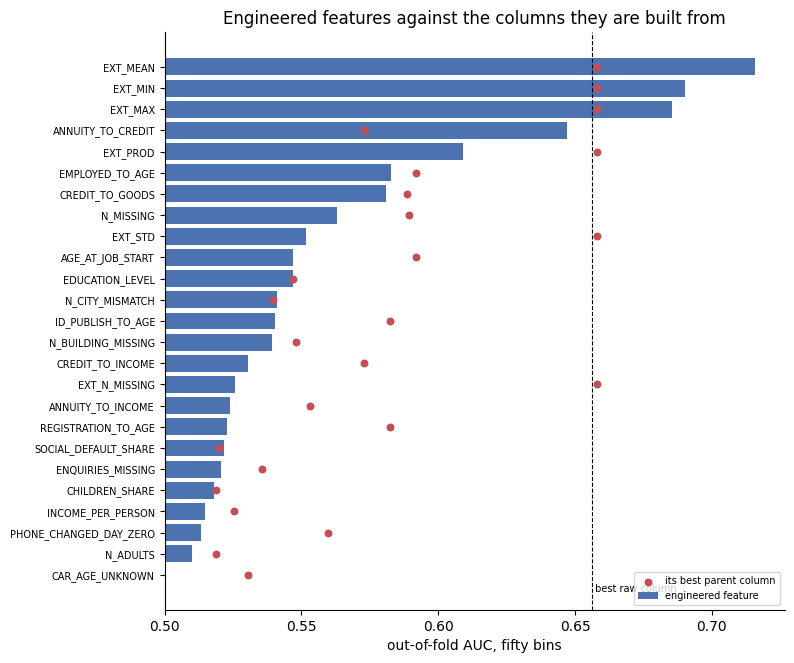

In [117]:
fig, ax = plt.subplots(figsize=(8, 7.5))
plot = fe_scores.sort_values('auc_50')
ax.barh(plot.index, plot['auc_50'] - 0.5, left=0.5, color='#4C72B0', label='engineered feature')
ax.scatter(plot['parent_auc_50'], plot.index, color='#C44E52', zorder=3, s=22, label='its best parent column')
ax.axvline(ranking['oof_auc'].max(), color='black', linestyle='--', linewidth=0.8)
ax.text(ranking['oof_auc'].max(), -0.9, ' best raw column', fontsize=7, va='bottom')
ax.set_xlabel('out-of-fold AUC, fifty bins')
ax.set_title('Engineered features against the columns they are built from')
ax.tick_params(axis='y', labelsize=7)
ax.legend(fontsize=7, loc='lower right')
sns.despine()
plt.show()

### 11.3 Default rate across bins for the strongest new features

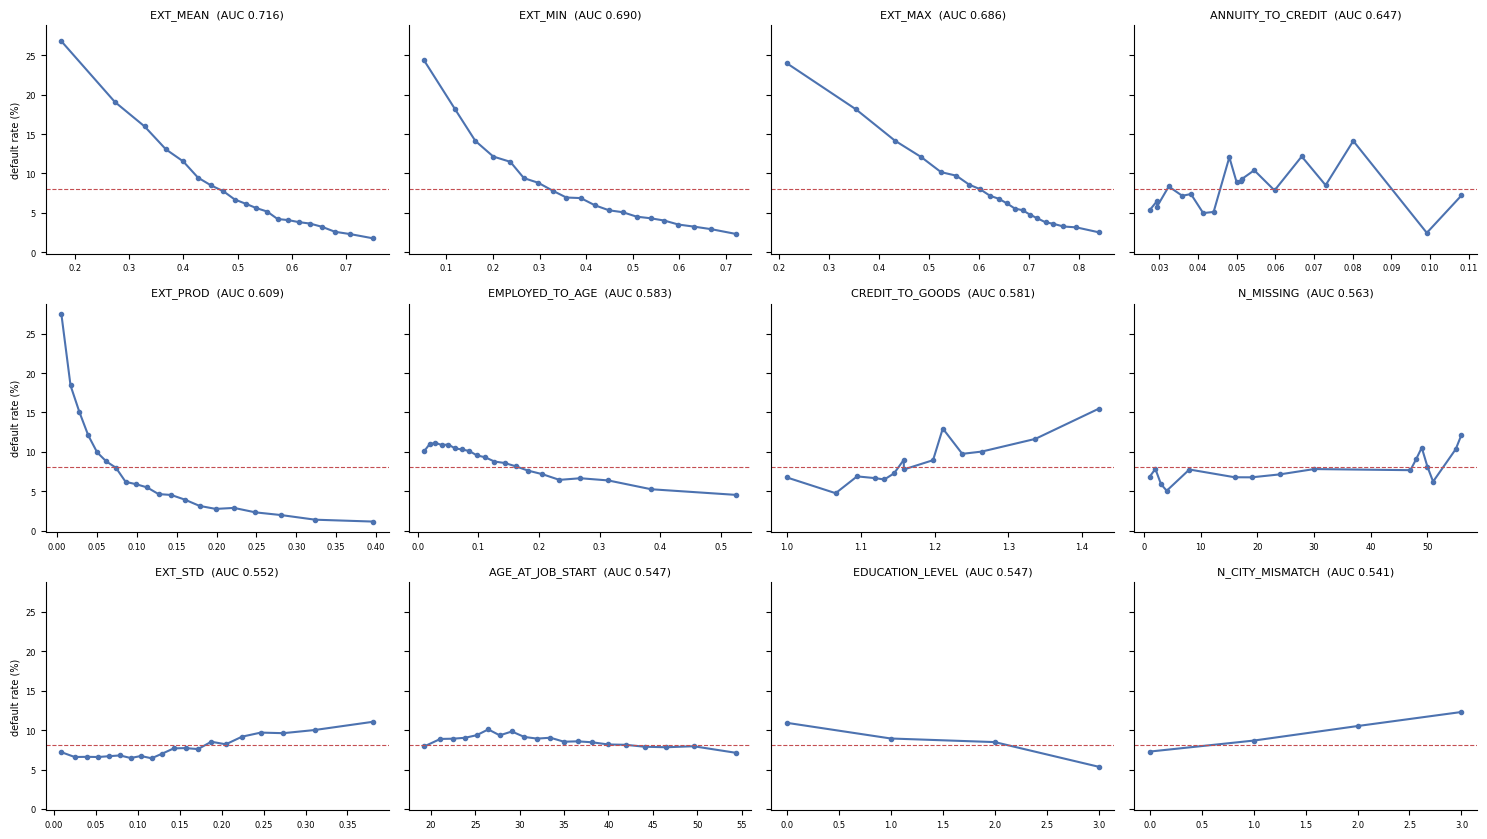

EXT_MEAN
  bin median: [0.235, 0.349, 0.414, 0.462, 0.505, 0.544, 0.583, 0.623, 0.667, 0.725]
  default %:  [22.9, 14.5, 10.5, 8.1, 6.4, 5.4, 4.2, 3.7, 2.9, 2.0]
EXT_MIN
  bin median: [0.089, 0.182, 0.254, 0.313, 0.373, 0.434, 0.494, 0.553, 0.614, 0.691]
  default %:  [21.2, 13.1, 10.5, 8.3, 6.9, 5.6, 4.8, 4.2, 3.4, 2.6]
ANNUITY_TO_CREDIT
  bin median: [0.029, 0.032, 0.037, 0.042, 0.05, 0.051, 0.053, 0.064, 0.079, 0.105]
  default %:  [5.9, 7.1, 7.3, 5.0, 9.7, 9.1, 9.9, 10.0, 11.3, 4.8]
CREDIT_TO_GOODS
  bin median: [1.0, 1.066, 1.106, 1.132, 1.158, 1.198, 1.238, 1.396]
  default %:  [6.7, 4.7, 6.8, 6.7, 8.8, 10.0, 9.9, 12.7]


EMPLOYED_TO_AGE
  bin median: [0.015, 0.034, 0.056, 0.079, 0.104, 0.135, 0.171, 0.219, 0.289, 0.442]
  default %:  [10.5, 11.0, 10.7, 10.2, 9.4, 8.7, 7.9, 6.8, 6.5, 4.9]
AGE_AT_JOB_START
  bin median: [20.266, 23.168, 25.818, 28.433, 31.244, 34.229, 37.339, 40.931, 45.262, 51.532]
  default %:  [8.4, 9.0, 9.7, 9.6, 9.0, 8.8, 8.5, 8.2, 7.9, 7.5]


In [118]:
def rate_table(s, q=10, min_rows=500):
    if s.nunique() <= 20:
        keys = s
    else:
        keys = pd.qcut(s, q, duplicates='drop')
    out = y.groupby(keys, observed=True).agg(rows='size', default_pct='mean')
    out['default_pct'] *= 100
    out['x'] = s.groupby(keys, observed=True).median().values
    return out[out['rows'] >= min_rows].reset_index(drop=True)

top_new = fe_scores.index[:12].tolist()
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5), sharey=True)
for ax, c in zip(axes.ravel(), top_new):
    t = rate_table(fe_train[c], q=20)
    ax.plot(t['x'], t['default_pct'], marker='o', markersize=3, color='#4C72B0')
    ax.axhline(default_rate * 100, color='#C44E52', linestyle='--', linewidth=0.8)
    ax.set_title(f"{c}  (AUC {fe_scores.loc[c, 'auc_50']:.3f})", fontsize=8)
    ax.tick_params(labelsize=6)
for ax in axes[:, 0]:
    ax.set_ylabel('default rate (%)', fontsize=7)
sns.despine()
plt.tight_layout()
plt.show()

for c in ['EXT_MEAN', 'EXT_MIN', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'EMPLOYED_TO_AGE', 'AGE_AT_JOB_START']:
    t = rate_table(fe_train[c], q=10)
    print(c)
    print('  bin median:', np.round(t['x'].values, 3).tolist())
    print('  default %: ', t['default_pct'].round(1).tolist())

In [119]:
# the low-cardinality features, value by value
for c in ['EXT_N_MISSING', 'N_CITY_MISMATCH', 'N_ADULTS', 'EDUCATION_LEVEL', 'ENQUIRIES_MISSING', 'CAR_AGE_UNKNOWN', 'PHONE_CHANGED_DAY_ZERO']:
    t = y.groupby(fe_train[c]).agg(rows='size', default_pct='mean')
    t['default_pct'] = (t['default_pct'] * 100).round(2)
    print(t.T.to_string())
    print()

EXT_N_MISSING         0          1         2       3
rows           109589.0  161013.00  36737.00  172.00
default_pct         7.3       8.18      9.92    8.14

N_CITY_MISMATCH          0        1         2       3
rows             233394.00  1925.00  68380.00  3812.0
default_pct           7.28     8.68     10.52    12.3

N_ADULTS          1.0        2.0
rows         81302.00  226207.00
default_pct      8.63       7.87

EDUCATION_LEVEL        0          1         2         3       4
rows             3816.00  218391.00  10277.00  74863.00  164.00
default_pct        10.93       8.94      8.48      5.36    1.83

ENQUIRIES_MISSING          0         1
rows               265992.00  41519.00
default_pct             7.72     10.34

CAR_AGE_UNKNOWN          0        1
rows             304177.00  3334.00
default_pct           8.07     8.37

PHONE_CHANGED_DAY_ZERO          0         1
rows                    269839.00  37672.00
default_pct                  7.85      9.67



### 11.4 Redundancy among the new features

Two checks: how strongly each new feature correlates with an existing column, and how strongly the new features correlate with each other.

In [120]:
fe_numeric = fe_train.select_dtypes('number')
existing = app_clean[corr_cols]
ranked = pd.concat([existing, fe_numeric], axis=1).rank()
rho_fe = ranked.corr()

rows = []
for c in fe_numeric.columns:
    to_existing = rho_fe.loc[c, corr_cols].abs()
    to_new = rho_fe.loc[c, [x for x in fe_numeric.columns if x != c]].abs()
    rows.append({'feature': c, 'closest_existing': to_existing.idxmax(), 'rho_existing': to_existing.max(),
                 'closest_new': to_new.idxmax(), 'rho_new': to_new.max()})
closest = pd.DataFrame(rows).set_index('feature').join(fe_scores[['auc_50', 'gain']])
closest.sort_values('rho_existing', ascending=False).round(3)

,closest_existing,rho_existing,closest_new,rho_new,auc_50,gain
feature,,,,,,
CHILDREN_SHARE,CNT_CHILDREN,0.994,INCOME_PER_PERSON,0.462,0.518,-0.001
SOCIAL_DEFAULT_SHARE,DEF_30_CNT_SOCIAL_CIRCLE,0.987,EXT_MEAN,0.060,0.522,0.002
N_CITY_MISMATCH,REG_CITY_NOT_WORK_CITY,0.976,N_BUILDING_MISSING,0.264,0.541,0.002
EMPLOYED_TO_AGE,DAYS_EMPLOYED,0.966,AGE_AT_JOB_START,0.465,0.583,-0.009
REGISTRATION_TO_AGE,DAYS_REGISTRATION,0.928,AGE_AT_JOB_START,0.075,0.523,-0.060
ID_PUBLISH_TO_AGE,DAYS_ID_PUBLISH,0.822,AGE_AT_JOB_START,0.249,0.540,-0.042
AGE_AT_JOB_START,DAYS_BIRTH,0.777,EMPLOYED_TO_AGE,0.465,0.547,-0.045
CREDIT_TO_INCOME,AMT_CREDIT,0.752,ANNUITY_TO_INCOME,0.794,0.531,-0.042
EXT_MEAN,EXT_SOURCE_1,0.745,EXT_PROD,0.982,0.716,0.058


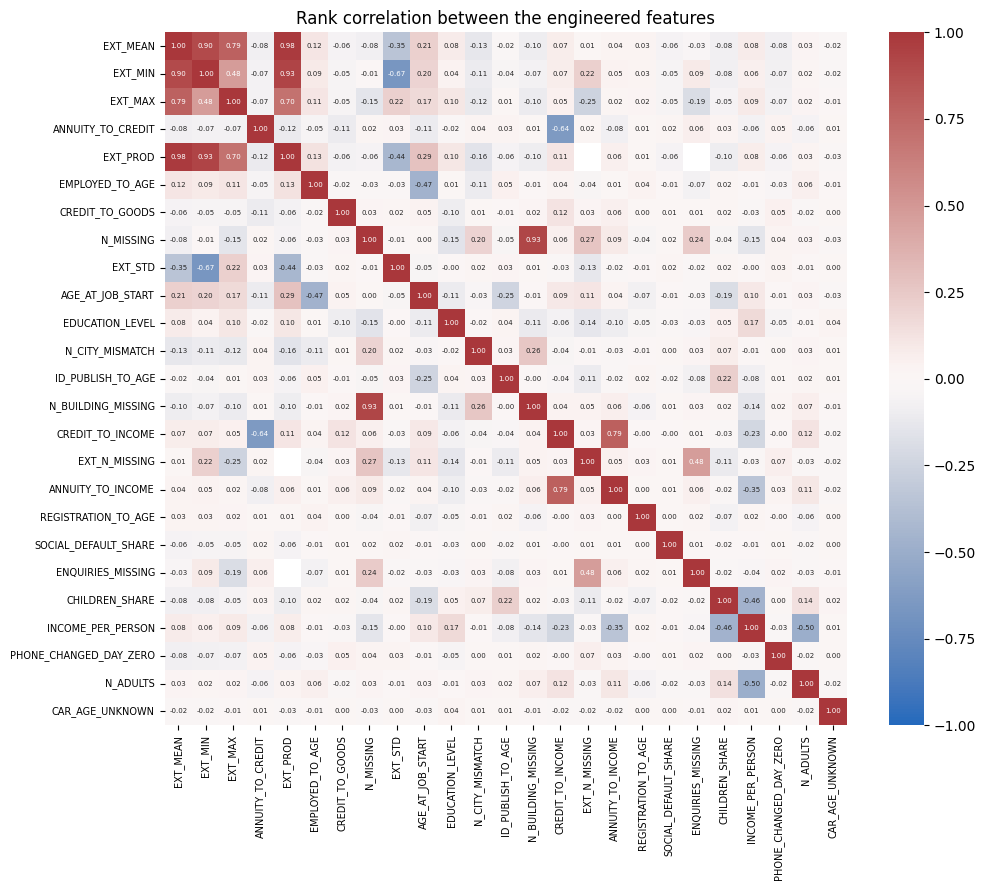

In [121]:
fig, ax = plt.subplots(figsize=(11, 9))
order = fe_scores.index.tolist()
sns.heatmap(rho_fe.loc[order, order], cmap='vlag', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 5}, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title('Rank correlation between the engineered features')
plt.show()

### 11.5 The external score combinations compared

Six features are built from the same three scores. The check is which of them a model would actually need.

In [122]:
ext_family = ['EXT_MEAN', 'EXT_MIN', 'EXT_MAX', 'EXT_STD', 'EXT_PROD', 'EXT_N_MISSING']
print(fe_scores.loc[ext_family, ['missing_pct', 'auc_10', 'auc_50', 'raw_auc', 'gain', 'psi']].round(4))
print()
print(rho_fe.loc[ext_family, ext_family].round(2))

# is the mean still the best simple combination once all three scores are present?
complete_ext = app_clean[EXT_COLS].notna().all(axis=1)
print(f"\nrows with all three scores: {complete_ext.sum():,} ({complete_ext.mean():.1%})")
def auc_on(rows, s):
    a = roc_auc_score(y[rows], s[rows])
    return max(a, 1 - a)

print(pd.Series({c: auc_on(complete_ext, fe_train[c]) for c in ['EXT_MEAN', 'EXT_MIN', 'EXT_MAX', 'EXT_PROD']}).round(4).to_string())

               missing_pct  auc_10  auc_50  raw_auc    gain     psi
feature                                                            
EXT_MEAN            0.0559  0.7128  0.7159   0.7165  0.0580  0.0111
EXT_MIN             0.0559  0.6879  0.6903   0.6910  0.0324  0.0156
EXT_MAX             0.0559  0.6831  0.6856   0.6862  0.0277  0.0045
EXT_STD            12.0025  0.5524  0.5517   0.5486 -0.1062  0.0227
EXT_PROD           64.3626  0.6088  0.6089   0.7402 -0.0490  0.0694
EXT_N_MISSING       0.0000  0.5259  0.5259   0.5259 -0.1320  0.0699

               EXT_MEAN  EXT_MIN  EXT_MAX  EXT_STD  EXT_PROD  EXT_N_MISSING
EXT_MEAN           1.00     0.90     0.79    -0.35      0.98           0.01
EXT_MIN            0.90     1.00     0.48    -0.67      0.93           0.22
EXT_MAX            0.79     0.48     1.00     0.22      0.70          -0.25
EXT_STD           -0.35    -0.67     0.22     1.00     -0.44          -0.13
EXT_PROD           0.98     0.93     0.70    -0.44      1.00            NaN

### 11.6 Summary

In [123]:
def verdict_fe(r):
    if r['psi'] >= 0.25:
        return 'drifts'
    if r['gain'] >= 0.005:
        return 'adds signal'
    if r['gain'] > -0.005:
        return 'same as parent'
    return 'weaker than parent'

fe_scores['verdict'] = fe_scores.apply(verdict_fe, axis=1)
print(fe_scores['verdict'].value_counts().to_string())
print(f"\nengineered features that beat the best raw column ({ranking.index[0]}, {ranking['oof_auc'].iloc[0]:.4f} with ten bins):")
print(fe_scores.loc[fe_scores['auc_10'] > ranking['oof_auc'].iloc[0], ['auc_10', 'auc_50']].round(4).to_string())
fe_scores[['family', 'auc_50', 'best_parent', 'parent_auc_50', 'gain', 'psi', 'verdict']].round(4)

verdict
weaker than parent    17
same as parent         4
adds signal            3
drifts                 1



engineered features that beat the best raw column (EXT_SOURCE_3, 0.6563 with ten bins):
          auc_10  auc_50
feature                 
EXT_MEAN  0.7128  0.7159
EXT_MIN   0.6879  0.6903
EXT_MAX   0.6831  0.6856


,family,auc_50,best_parent,parent_auc_50,gain,psi,verdict
feature,,,,,,,
EXT_MEAN,external scores,0.7159,EXT_SOURCE_3,0.6579,0.0580,0.0111,adds signal
EXT_MIN,external scores,0.6903,EXT_SOURCE_3,0.6579,0.0324,0.0156,adds signal
EXT_MAX,external scores,0.6856,EXT_SOURCE_3,0.6579,0.0277,0.0045,adds signal
ANNUITY_TO_CREDIT,loan structure,0.6469,AMT_CREDIT,0.5729,0.0740,0.9991,drifts
EXT_PROD,external scores,0.6089,EXT_SOURCE_3,0.6579,-0.0490,0.0694,weaker than parent
EMPLOYED_TO_AGE,time,0.5827,DAYS_EMPLOYED,0.5920,-0.0093,0.0064,weaker than parent
CREDIT_TO_GOODS,loan structure,0.5807,AMT_GOODS_PRICE,0.5885,-0.0078,0.0443,weaker than parent
N_MISSING,missingness,0.5630,EXT_SOURCE_1,0.5892,-0.0262,0.0127,weaker than parent
EXT_STD,external scores,0.5517,EXT_SOURCE_3,0.6579,-0.1062,0.0227,weaker than parent


### Stage 11 findings

25 features were built. None uses the target, none produces infinite values, and the same function runs on test.

**What clearly works**

| Feature | AUC (50 bins) | Best parent column | Gain |
|---|---:|---:|---:|
| `EXT_MEAN` | 0.716 | 0.658 | +0.058 |
| `EXT_MIN` | 0.690 | 0.658 | +0.032 |
| `EXT_MAX` | 0.686 | 0.658 | +0.028 |
| `ANNUITY_TO_CREDIT` | 0.647 | 0.573 | +0.074 |

- These four are the only engineered features that beat the columns they are built from when scored alone. The three external score summaries also beat every raw column in the table.
- `EXT_MEAN` separates the classes from 22.9% default in the lowest tenth to 2.0% in the highest. It is available for 99.9% of applicants, where the individual scores are missing for 20% and 56%.
- `ANNUITY_TO_CREDIT` has the largest gain of all. Its relationship with default is not a straight line: about 5% to 7% at the low end, 10% to 11% in the middle, and 4.8% at the top.

**`ANNUITY_TO_CREDIT` shifts heavily between train and test**
- Its PSI is 1.0, far above the 0.25 line and far above anything in stage 10.
- A check run outside this notebook shows why. Test loans carry higher payment rates: the median ratio is 0.061 in test against 0.050 in train. 13.4% of train loans have a ratio under 0.03 and no test loan does. Ratios above 0.07 cover 19% of train and 41% of test. The gap is the same within cash loans, so it is not the loan type mix.
- Stage 10 did not catch this because it scored columns one at a time, and `AMT_ANNUITY` and `AMT_CREDIT` each look stable. The shift is in how they relate. This is one of the combinations the adversarial model was using.
- Every ratio band seen in test also exists in train, so the model is not asked to extrapolate. What changes is how much weight each band carries.
- `CREDIT_TO_INCOME` shows a moderate shift (PSI 0.11). Every other engineered feature is stable.

**Restatements of existing columns**
- Five features correlate above 0.9 with a column that already exists and gain nothing: `CHILDREN_SHARE` (0.99 with `CNT_CHILDREN`), `SOCIAL_DEFAULT_SHARE` (0.99), `N_CITY_MISMATCH` (0.98 with `REG_CITY_NOT_WORK_CITY`), `EMPLOYED_TO_AGE` (0.97 with `DAYS_EMPLOYED`) and `REGISTRATION_TO_AGE` (0.93).
- `EXT_PROD` correlates 0.98 with `EXT_MEAN` and is missing for 64% of applicants, since it needs all three scores. On the rows that have all three, the two score the same (0.740 against 0.741).
- `EDUCATION_LEVEL` scores exactly as the text column does. It is an encoding, not new information.

**New information, but not strong alone**
- Several features have little correlation with any existing column, so they describe something the table did not already hold, even though they do not outscore their parents: `CREDIT_TO_GOODS` (highest correlation with an existing column 0.20, AUC 0.581), `N_MISSING` (0.20, AUC 0.563), `EXT_STD` (0.19, AUC 0.552), `EXT_N_MISSING` (0.19), `N_BUILDING_MISSING` (0.26) and `ENQUIRIES_MISSING` (0.09).
- Whether these help can only be judged inside a model, which is stage 12.

**No value**
- `CAR_AGE_UNKNOWN`: 8.4% default against 8.1%, AUC 0.500. The stage 4 suspicion that a car age of 64 or 65 is a default value may be right, but it says nothing about default.
- `PHONE_CHANGED_DAY_ZERO`: the gap is real (9.7% against 7.9%), but `DAYS_LAST_PHONE_CHANGE` already contains it and scores higher (0.560 against 0.513).
- `AGE_AT_JOB_START`, `ID_PUBLISH_TO_AGE`, `ANNUITY_TO_INCOME`, `INCOME_PER_PERSON` and `N_ADULTS` are all weaker than a column they are built from.

**A limit of this stage**
- The verdict column compares single-feature strength. 17 of 25 features come out "weaker than parent", but that does not make them useless. A ratio can add information to a model while being weaker alone than its strongest ingredient, and the parent chosen for comparison is sometimes a very strong column such as `EXT_SOURCE_3`.
- The reverse also holds. A tree model can rebuild a restatement from its parents, so those are safe to drop.

**Decisions**
- Keep for stage 12: `EXT_MEAN`, `EXT_MIN`, `EXT_MAX`, `EXT_STD`, `EXT_N_MISSING`, `ANNUITY_TO_CREDIT`, `CREDIT_TO_GOODS`, `CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME`, `N_MISSING`, `N_BUILDING_MISSING`, `ENQUIRIES_MISSING`, `N_CITY_MISMATCH` and `EDUCATION_LEVEL`.
- Drop: `EXT_PROD`, `CAR_AGE_UNKNOWN`, `PHONE_CHANGED_DAY_ZERO`, `CHILDREN_SHARE`, `SOCIAL_DEFAULT_SHARE`, `EMPLOYED_TO_AGE`, `REGISTRATION_TO_AGE`, `ID_PUBLISH_TO_AGE`, `AGE_AT_JOB_START`, `INCOME_PER_PERSON` and `N_ADULTS`.
- Keep `ANNUITY_TO_CREDIT` despite the shift, because it is the strongest feature outside the external scores. Stage 12 must test the model with and without it, and score it on train rows weighted to resemble test.
- The stage 10 conclusion that the train and test difference does not affect prediction was reached without this feature. It needs to be rechecked once the feature is in the model.

## Stage 12: Quick model check

The same cross-validation folds on raw and engineered features, to confirm the new features help.

Stage 11 scored the engineered features one at a time. This stage puts them in a model. Every run uses the same five folds from stage 2 and the same untuned gradient boosting model from stage 9, so the only thing that changes between runs is the feature list. This is a check on the features, not the final model.

### 12.1 Setup

In [124]:
train_frame = pd.concat([train_prepared[RAW_FEATURES], fe_train], axis=1)
test_frame = pd.concat([test_prepared[RAW_FEATURES], fe_test], axis=1)
TEXT_LEVELS = {c: sorted(train_frame[c].dropna().unique()) for c in train_frame.columns
               if not pd.api.types.is_numeric_dtype(train_frame[c])}

def design_matrix(frame, cols):
    # text columns become integer codes using the levels seen in train. Unseen levels become missing.
    X = np.empty((len(frame), len(cols)), dtype=float)
    for j, c in enumerate(cols):
        if c in TEXT_LEVELS:
            codes = pd.Categorical(frame[c], categories=TEXT_LEVELS[c]).codes.astype(float)
            codes[codes < 0] = np.nan
            X[:, j] = codes
        else:
            X[:, j] = frame[c].to_numpy(dtype=float)
    return X, [c in TEXT_LEVELS for c in cols]

def new_model(is_cat, max_iter=200):
    return HistGradientBoostingClassifier(max_iter=max_iter, learning_rate=0.1, early_stopping=False, random_state=0,
                                          categorical_features=is_cat if any(is_cat) else None)

def cv_fit(cols):
    X, is_cat = design_matrix(train_frame, cols)
    oof, aucs = np.empty(len(X)), []
    for k in range(5):
        train, val = fold_id != k, fold_id == k
        model = new_model(is_cat).fit(X[train], y_arr[train])
        oof[val] = model.predict_proba(X[val])[:, 1]
        aucs.append(roc_auc_score(y_arr[val], oof[val]))
    return np.array(aucs), oof

def add(base, extra):
    return base + [c for c in extra if c not in base]

KEPT = ['EXT_MEAN', 'EXT_MIN', 'EXT_MAX', 'EXT_STD', 'EXT_N_MISSING', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS',
        'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'N_MISSING', 'N_BUILDING_MISSING', 'ENQUIRIES_MISSING',
        'N_CITY_MISMATCH', 'EDUCATION_LEVEL']
EXT_NEW = ['EXT_MEAN', 'EXT_MIN', 'EXT_MAX', 'EXT_STD', 'EXT_N_MISSING']
LOAN_NEW = ['ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME']

# pending drops from stages 8 to 11: test-constant documents, noise-floor flags, the shifted enquiry counts,
# the duplicate social circle count, and the education text column now replaced by EDUCATION_LEVEL
FINAL_DROPS = ['DEF_60_CNT_SOCIAL_CIRCLE', 'FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_13',
               'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_16', 'FLAG_DOCUMENT_18', 'REG_REGION_NOT_LIVE_REGION',
               'REG_REGION_NOT_WORK_REGION', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'NAME_EDUCATION_TYPE']

raw_set = add(list(compact), ['N_BUILDING_MISSING'])
kept_set = add(raw_set, KEPT)
feature_sets = {
    'raw': raw_set,
    'raw + all 25 engineered': add(raw_set, list(fe_train.columns)),
    'raw + 14 kept': kept_set,
    'raw + 14 kept, no ANNUITY_TO_CREDIT': [c for c in kept_set if c != 'ANNUITY_TO_CREDIT'],
    'raw + external score features only': add(raw_set, EXT_NEW),
    'raw + loan ratios only': add(raw_set, LOAN_NEW),
    'final': [c for c in kept_set if c not in FINAL_DROPS],
}
missing_drops = [c for c in FINAL_DROPS if c not in kept_set]
print('pending drops not in the working set anyway:', missing_drops)
pd.Series({name: len(cols) for name, cols in feature_sets.items()}, name='features')

pending drops not in the working set anyway: []


raw                                    55
raw + all 25 engineered                79
raw + 14 kept                          68
raw + 14 kept, no ANNUITY_TO_CREDIT    67
raw + external score features only     60
raw + loan ratios only                 59
final                                  55
Name: features, dtype: int64

### 12.2 Raw against engineered

`difference` is the mean AUC change against the raw set, fold by fold. `folds_better` counts how many of the five folds improved.

In [125]:
runs = {name: cv_fit(cols) for name, cols in feature_sets.items()}

base_aucs = runs['raw'][0]
comparison = pd.DataFrame({name: {
    'features': len(feature_sets[name]), 'mean_auc': aucs.mean(), 'fold_std': aucs.std(ddof=1),
    'difference': (aucs - base_aucs).mean(), 'difference_std': (aucs - base_aucs).std(ddof=1),
    'folds_better': int((aucs > base_aucs).sum()),
} for name, (aucs, _) in runs.items()}).T

print('AUC by fold')
print(pd.DataFrame({name: aucs for name, (aucs, _) in runs.items()}).round(4).T.to_string())
comparison.round(4)

AUC by fold
                                          0       1       2       3       4
raw                                  0.7513  0.7623  0.7536  0.7589  0.7519
raw + all 25 engineered              0.7601  0.7684  0.7589  0.7667  0.7594
raw + 14 kept                        0.7611  0.7685  0.7592  0.7664  0.7595
raw + 14 kept, no ANNUITY_TO_CREDIT  0.7529  0.7618  0.7541  0.7606  0.7531
raw + external score features only   0.7529  0.7605  0.7530  0.7601  0.7516
raw + loan ratios only               0.7599  0.7698  0.7612  0.7668  0.7591
final                                0.7598  0.7678  0.7592  0.7675  0.7580


,features,mean_auc,fold_std,difference,difference_std,folds_better
raw,55.0,0.7556,0.0048,0.0000,0.0000,0.0
raw + all 25 engineered,79.0,0.7627,0.0045,0.0071,0.0014,5.0
raw + 14 kept,68.0,0.7629,0.0042,0.0073,0.0016,5.0
"raw + 14 kept, no ANNUITY_TO_CREDIT",67.0,0.7565,0.0043,0.0009,0.0009,4.0
raw + external score features only,60.0,0.7556,0.0043,0.0000,0.0014,2.0
raw + loan ratios only,59.0,0.7634,0.0047,0.0078,0.0006,5.0
final,55.0,0.7625,0.0048,0.0069,0.0016,5.0


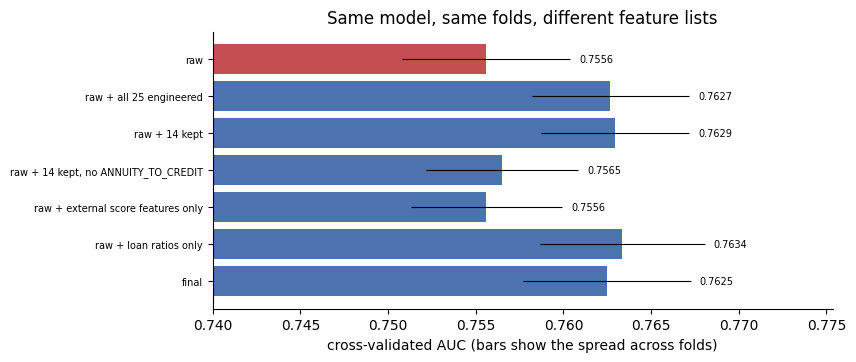

In [126]:
fig, ax = plt.subplots(figsize=(8, 3.6))
plot = comparison.iloc[::-1]
ax.barh(plot.index, plot['mean_auc'], xerr=plot['fold_std'], color=['#C44E52' if n == 'raw' else '#4C72B0' for n in plot.index],
        error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
ax.set_xlim(0.74, plot['mean_auc'].max() + 0.012)
for i, (name, r) in enumerate(plot.iterrows()):
    ax.text(r['mean_auc'] + r['fold_std'] + 0.0005, i, f"{r['mean_auc']:.4f}", va='center', fontsize=7)
ax.set_xlabel('cross-validated AUC (bars show the spread across folds)')
ax.set_title('Same model, same folds, different feature lists')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

### 12.3 Against the stage 2 baselines

In [127]:
def all_metrics(pred):
    return {'roc_auc': roc_auc_score(y_arr, pred), 'pr_auc': average_precision_score(y_arr, pred),
            'log_loss': log_loss_clipped(y_arr, pred), 'brier': brier_score_loss(y_arr, pred)}

metrics = pd.DataFrame({
    'predict the default rate for everyone': all_metrics(np.full(len(y_arr), default_rate)),
    'mean external score alone (stage 2)': {'roc_auc': roc_auc_score(y_arr, risk), 'pr_auc': average_precision_score(y_arr, risk),
                                            'log_loss': np.nan, 'brier': np.nan},
    'model on raw features': all_metrics(runs['raw'][1]),
    'model on final features': all_metrics(runs['final'][1]),
}).T
metrics.round(4)

,roc_auc,pr_auc,log_loss,brier
predict the default rate for everyone,0.5000,0.0807,0.2805,0.0742
mean external score alone (stage 2),0.7165,0.1893,NaN,NaN
model on raw features,0.7556,0.2393,0.2469,0.0680
model on final features,0.7624,0.2466,0.2450,0.0676


In [128]:
# how the final model sorts applicants: default rate by tenth of predicted risk
final_pred = runs['final'][1]
tenth = pd.qcut(final_pred, 10, labels=[f"D{i}" for i in range(1, 11)])
lift = pd.DataFrame({'y': y_arr, 'pred': final_pred}).groupby(tenth, observed=True).agg(rows=('y', 'size'), defaults=('y', 'sum'),
                                                                                         default_pct=('y', 'mean'), mean_predicted_pct=('pred', 'mean'))
lift[['default_pct', 'mean_predicted_pct']] *= 100
lift['share_of_all_defaults_pct'] = lift['defaults'] / lift['defaults'].sum() * 100
print(f"the riskiest tenth holds {lift['share_of_all_defaults_pct'].iloc[-1]:.1f}% of all defaults; the riskiest three tenths hold {lift['share_of_all_defaults_pct'].iloc[-3:].sum():.1f}%")
lift.round(2)

the riskiest tenth holds 34.1% of all defaults; the riskiest three tenths hold 65.5%


,rows,defaults,default_pct,mean_predicted_pct,share_of_all_defaults_pct
D1,30752,331,1.08,1.13,1.33
D2,30751,590,1.92,1.94,2.38
D3,30751,873,2.84,2.66,3.52
D4,30751,1048,3.41,3.45,4.22
D5,30751,1416,4.60,4.41,5.70
D6,30751,1831,5.95,5.68,7.38
D7,30751,2485,8.08,7.44,10.01
D8,30751,3181,10.34,10.11,12.81
D9,30751,4615,15.01,14.84,18.59
D10,30751,8455,27.50,28.54,34.06


### 12.4 Which features the model relies on

Permutation importance on one held-out fold: each feature is shuffled in turn and the drop in AUC is recorded. This measures what the fitted model actually uses, which is the model-based confirmation stage 8 asked for.

In [129]:
from sklearn.inspection import permutation_importance

final_set = feature_sets['final']
X_final, cat_final = design_matrix(train_frame, final_set)
held_out = fold_id == 0
importance_model = new_model(cat_final).fit(X_final[~held_out], y_arr[~held_out])
perm = permutation_importance(importance_model, X_final[held_out], y_arr[held_out], scoring='roc_auc', n_repeats=3, random_state=0)

importance = pd.DataFrame({'auc_drop': perm.importances_mean, 'std': perm.importances_std,
                           'engineered': [c in fe_train.columns for c in final_set]}, index=final_set).sort_values('auc_drop', ascending=False)
importance['rank'] = np.arange(1, len(importance) + 1)
positive = importance['auc_drop'].clip(lower=0)
print(f"engineered features: {importance['engineered'].sum()} of {len(importance)} features, {positive[importance['engineered']].sum() / positive.sum():.0%} of total importance")
print(f"features whose shuffling costs less than 0.0002 AUC: {(importance['auc_drop'] < 0.0002).sum()}")
print('engineered features by rank:', importance.loc[importance['engineered'], 'rank'].to_dict())
importance.head(25).round(4)

engineered features: 14 of 55 features, 69% of total importance
features whose shuffling costs less than 0.0002 AUC: 18
engineered features by rank: {'EXT_MEAN': 1, 'ANNUITY_TO_CREDIT': 2, 'CREDIT_TO_GOODS': 6, 'EDUCATION_LEVEL': 13, 'EXT_MIN': 14, 'EXT_MAX': 15, 'CREDIT_TO_INCOME': 21, 'EXT_STD': 28, 'EXT_N_MISSING': 30, 'N_MISSING': 32, 'ANNUITY_TO_INCOME': 34, 'N_BUILDING_MISSING': 42, 'N_CITY_MISMATCH': 47, 'ENQUIRIES_MISSING': 48}


,auc_drop,std,engineered,rank
EXT_MEAN,0.0822,0.0020,True,1
ANNUITY_TO_CREDIT,0.0159,0.0013,True,2
EXT_SOURCE_3,0.0067,0.0003,False,3
DAYS_BIRTH,0.0056,0.0003,False,4
AMT_ANNUITY,0.0056,0.0005,False,5
CREDIT_TO_GOODS,0.0045,0.0004,True,6
EXT_SOURCE_1,0.0038,0.0004,False,7
CODE_GENDER,0.0038,0.0001,False,8
AMT_GOODS_PRICE,0.0035,0.0002,False,9
ORGANIZATION_TYPE,0.0033,0.0002,False,10


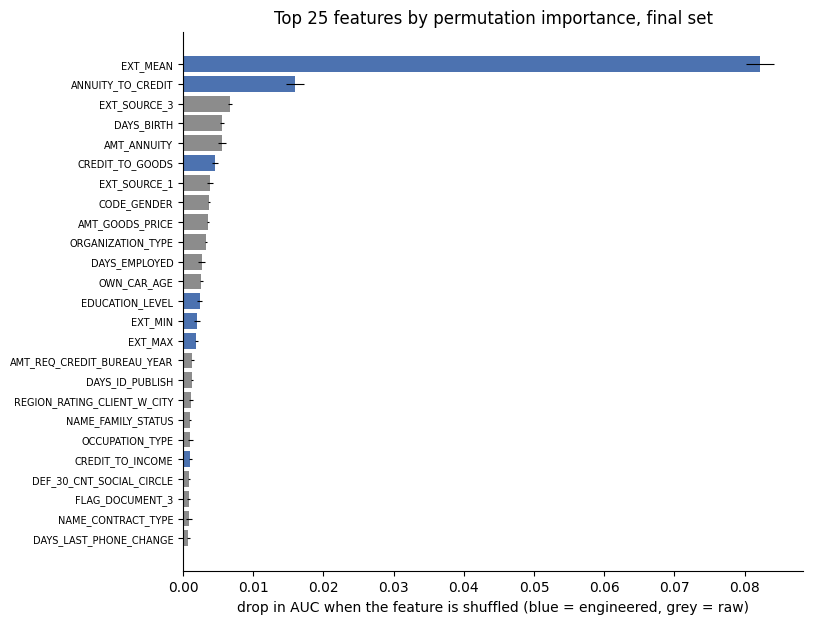

least important 15:
                         auc_drop  engineered
HOUR_APPR_PROCESS_START   0.00011       False
N_BUILDING_MISSING        0.00010        True
CNT_FAM_MEMBERS           0.00008       False
CNT_CHILDREN              0.00004       False
FLAG_DOCUMENT_6           0.00003       False
REG_CITY_NOT_WORK_CITY    0.00002       False
N_CITY_MISMATCH           0.00001        True
ENQUIRIES_MISSING         0.00000        True
FLAG_EMP_PHONE            0.00000       False
AMT_INCOME_TOTAL         -0.00002       False
LIVE_CITY_NOT_WORK_CITY  -0.00002       False
NAME_INCOME_TYPE         -0.00002       False
FLAG_OWN_CAR             -0.00003       False
FLAG_PHONE               -0.00011       False
NAME_TYPE_SUITE          -0.00015       False


In [130]:
fig, ax = plt.subplots(figsize=(8, 7))
top = importance.head(25).iloc[::-1]
ax.barh(top.index, top['auc_drop'], xerr=top['std'], color=np.where(top['engineered'], '#4C72B0', '#8C8C8C'),
        error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
ax.set_xlabel('drop in AUC when the feature is shuffled (blue = engineered, grey = raw)')
ax.set_title('Top 25 features by permutation importance, final set')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

print('least important 15:')
print(importance.tail(15)[['auc_drop', 'engineered']].round(5).to_string())

### 12.5 The `ANNUITY_TO_CREDIT` shift, and whether it matters

Stage 11 found this ratio distributed very differently in test. First the shift itself, then what it does to the model.

In [131]:
edges = [0, 0.03, 0.04, 0.05 - 1e-9, 0.05 + 1e-9, 0.06, 0.07, 0.09, 1]
names = ['under 0.03', '0.03 to 0.04', '0.04 to 0.05', 'exactly 0.05', '0.05 to 0.06', '0.06 to 0.07', '0.07 to 0.09', 'over 0.09']

def band_table(train_rows, test_rows):
    tr_band = pd.cut(fe_train.loc[train_rows, 'ANNUITY_TO_CREDIT'], edges, labels=names)
    te_band = pd.cut(fe_test.loc[test_rows, 'ANNUITY_TO_CREDIT'], edges, labels=names)
    t = pd.DataFrame({
        'train_share_pct': tr_band.value_counts(normalize=True) * 100,
        'test_share_pct': te_band.value_counts(normalize=True) * 100,
        'train_default_pct': y[train_rows].groupby(tr_band, observed=False).mean() * 100,
    }).reindex(names)
    expected = (t['test_share_pct'] / 100 * t['train_default_pct']).sum()
    return t, expected

all_rows_train, all_rows_test = pd.Series(True, index=fe_train.index), pd.Series(True, index=fe_test.index)
t, expected = band_table(all_rows_train, all_rows_test)
print(f"median ratio: train {fe_train['ANNUITY_TO_CREDIT'].median():.4f}, test {fe_test['ANNUITY_TO_CREDIT'].median():.4f}")
print(t.round(2))
print(f"\ntrain default rate {default_rate:.2%}; expected in test if each band defaults as in train: {expected:.2f}%")

cash_train = train_prepared['NAME_CONTRACT_TYPE'] == 'Cash loans'
cash_test = test_prepared['NAME_CONTRACT_TYPE'] == 'Cash loans'
t_cash, expected_cash = band_table(cash_train, cash_test)
print('\ncash loans only')
print(t_cash.round(2))
print(f"\ncash loans: train default rate {y[cash_train].mean():.2%}; expected in test {expected_cash:.2f}%")

median ratio: train 0.0500, test 0.0614
                   train_share_pct  test_share_pct  train_default_pct
ANNUITY_TO_CREDIT                                                    
under 0.03                   13.42            0.00               5.84
0.03 to 0.04                 18.62           11.92               7.07
0.04 to 0.05                 16.86           13.52              10.10
exactly 0.05                  9.51            0.90               5.49
0.05 to 0.06                 14.14           22.91               8.75
0.06 to 0.07                  7.99            9.97              11.46
0.07 to 0.09                  8.20           20.09              12.20
over 0.09                    11.26           20.69               5.28

train default rate 8.07%; expected in test if each band defaults as in train: 8.95%

cash loans only
                   train_share_pct  test_share_pct  train_default_pct
ANNUITY_TO_CREDIT                                                    
under 0.03        

In [132]:
# adversarial validation again, now with the engineered features in
both_frame = pd.concat([train_frame, test_frame], ignore_index=True)

def adversarial_fit(cols):
    X, is_cat = design_matrix(both_frame, cols)
    p = np.empty(len(X))
    for k in range(5):
        train, val = adv_fold != k, adv_fold == k
        p[val] = new_model(is_cat, max_iter=100).fit(X[train], is_test[train]).predict_proba(X[val])[:, 1]
    return roc_auc_score(is_test, p), p

adv_with, propensity_fe = adversarial_fit(feature_sets['raw + 14 kept'])
adv_without, _ = adversarial_fit(feature_sets['raw + 14 kept, no ANNUITY_TO_CREDIT'])
print(f"adversarial AUC, stage 10 (all 120 raw features):          {adv_auc_all:.4f}")
print(f"adversarial AUC, raw + 14 kept:                            {adv_with:.4f}")
print(f"adversarial AUC, raw + 14 kept without ANNUITY_TO_CREDIT:  {adv_without:.4f}")

adversarial AUC, stage 10 (all 120 raw features):          0.8811
adversarial AUC, raw + 14 kept:                            0.9386
adversarial AUC, raw + 14 kept without ANNUITY_TO_CREDIT:  0.9196


In [133]:
# validation AUC with train rows weighted to resemble test, using the new propensities
p_fe = np.clip(propensity_fe[is_test == 0], 1e-4, 1 - 1e-4)
w_fe = p_fe / (1 - p_fe)
w_fe = np.clip(w_fe, None, np.quantile(w_fe, 0.999))
print(f"effective sample size of the weighted train set: {w_fe.sum() ** 2 / (w_fe ** 2).sum():,.0f} of {len(w_fe):,}")
print(f"default rate: train {y_arr.mean():.2%}, train weighted to resemble test {np.average(y_arr, weights=w_fe):.2%}")

rows = {}
for name in ['raw', 'raw + 14 kept', 'raw + 14 kept, no ANNUITY_TO_CREDIT', 'final']:
    pred = runs[name][1]
    rows[name] = {'auc': roc_auc_score(y_arr, pred), 'auc_weighted_to_test': roc_auc_score(y_arr, pred, sample_weight=w_fe)}
weighted = pd.DataFrame(rows).T
weighted['change'] = weighted['auc_weighted_to_test'] - weighted['auc']
print(weighted.round(4))

fifth_fe = pd.qcut(p_fe, 5, labels=['least like test', '2', '3', '4', 'most like test'])
by_fifth_fe = pd.DataFrame({
    'rows': pd.Series(y_arr).groupby(fifth_fe, observed=True).size(),
    'default_pct': pd.Series(y_arr).groupby(fifth_fe, observed=True).mean() * 100,
    **{name: pd.DataFrame({'y': y_arr, 'p': runs[name][1]}).groupby(fifth_fe, observed=True)[['y', 'p']].apply(lambda g: roc_auc_score(g['y'], g['p']))
       for name in ['raw', 'raw + 14 kept', 'raw + 14 kept, no ANNUITY_TO_CREDIT']},
})
by_fifth_fe.round(4)

effective sample size of the weighted train set: 51,350 of 307,511
default rate: train 8.07%, train weighted to resemble test 7.98%


                                        auc  auc_weighted_to_test  change
raw                                  0.7556                0.7518 -0.0038
raw + 14 kept                        0.7629                0.7636  0.0007
raw + 14 kept, no ANNUITY_TO_CREDIT  0.7565                0.7515 -0.0050
final                                0.7624                0.7628  0.0003


,rows,default_pct,raw,raw + 14 kept,"raw + 14 kept, no ANNUITY_TO_CREDIT"
least like test,61503,6.1217,0.7264,0.7324,0.7287
2,61502,8.4729,0.7669,0.7710,0.7672
3,61502,9.3216,0.7661,0.7730,0.7685
4,61502,8.4940,0.7518,0.7598,0.7522
most like test,61502,7.9542,0.7468,0.7591,0.7463


In [134]:
# what the fitted models expect on test
X_test_final, _ = design_matrix(test_frame, final_set)
test_pred_final = new_model(cat_final).fit(X_final, y_arr).predict_proba(X_test_final)[:, 1]

no_ratio = [c for c in final_set if c != 'ANNUITY_TO_CREDIT']
X_nr, cat_nr = design_matrix(train_frame, no_ratio)
test_pred_no_ratio = new_model(cat_nr).fit(X_nr, y_arr).predict_proba(design_matrix(test_frame, no_ratio)[0])[:, 1]

print(f"mean predicted default probability on train (out of fold), final set: {runs['final'][1].mean():.2%}")
print(f"mean predicted default probability on test, final set:                {test_pred_final.mean():.2%}")
print(f"mean predicted default probability on test, without the ratio:        {test_pred_no_ratio.mean():.2%}")
print(f"rank correlation between the two sets of test predictions:            {pd.Series(test_pred_final).corr(pd.Series(test_pred_no_ratio), method='spearman'):.4f}")

mean predicted default probability on train (out of fold), final set: 8.02%
mean predicted default probability on test, final set:                8.10%
mean predicted default probability on test, without the ratio:        8.10%
rank correlation between the two sets of test predictions:            0.9246


### Stage 12 findings

**The engineered features help**

| Feature list | Features | AUC | Against raw | Folds better |
|---|---:|---:|---:|---:|
| Raw | 55 | 0.7556 | | |
| Raw + all 25 engineered | 79 | 0.7627 | +0.0071 | 5 of 5 |
| Raw + 14 kept | 68 | 0.7629 | +0.0073 | 5 of 5 |
| Final (pending drops applied) | 55 | 0.7625 | +0.0069 | 5 of 5 |

- The gain is 0.007 AUC and it appears in every fold. The fold-by-fold difference has a standard deviation of 0.0016, so the gain is about four times its own noise.
- The 14 kept features do as well as all 25. The 11 dropped in stage 11 added nothing.
- The final list has the same number of features as the raw list (55) and scores 0.007 higher. Removing the 13 pending columns cost 0.0004.

**Almost all of the gain is one feature**

| Feature list | AUC | Against raw |
|---|---:|---:|
| Raw + loan ratios only | 0.7634 | +0.0078 |
| Raw + 14 kept, without `ANNUITY_TO_CREDIT` | 0.7565 | +0.0009 |
| Raw + external score features only | 0.7556 | 0.0000 |

- Without `ANNUITY_TO_CREDIT`, the other 13 engineered features together add 0.0009.
- The four loan ratios alone do slightly better than all 14.
- The external score summaries add nothing to accuracy. A tree model already combines the three raw scores by itself.

**What the model relies on**
- `EXT_MEAN` is by far the most important feature (shuffling it costs 0.082 AUC), then `ANNUITY_TO_CREDIT` (0.016), `EXT_SOURCE_3` (0.007), `DAYS_BIRTH`, `AMT_ANNUITY` and `CREDIT_TO_GOODS`.
- The 14 engineered features hold 69% of the total importance.
- This does not contradict the point above. Given `EXT_MEAN`, the model uses it in place of the three raw scores. It moves the importance into one column without adding accuracy.
- 18 of the 55 features cost less than 0.0002 AUC when shuffled, including `N_BUILDING_MISSING`, `N_CITY_MISMATCH`, `ENQUIRIES_MISSING`, `FLAG_EMP_PHONE`, `AMT_INCOME_TOTAL` and `NAME_INCOME_TYPE`.
- Permutation importance understates features that have a close substitute in the table, and this was measured on one fold. Treat the bottom of the list as candidates for removal, not as proven useless.

**Against the baselines**

| | ROC AUC | PR AUC | Log loss |
|---|---:|---:|---:|
| Predict the default rate for everyone | 0.500 | 0.081 | 0.2805 |
| Mean external score alone | 0.717 | 0.189 | |
| Model on raw features | 0.756 | 0.239 | 0.2469 |
| Model on final features | 0.762 | 0.247 | 0.2450 |

- The riskiest tenth of applicants by predicted score defaults at 27.5% and holds 34% of all defaults. The riskiest three tenths hold 66%. The safest tenth defaults at 1.1%.
- Predicted and actual default rates agree closely in every tenth, so the untuned model is reasonably calibrated.

**The `ANNUITY_TO_CREDIT` shift**
- The shift is confirmed in this notebook. The median ratio is 0.050 in train and 0.061 in test. 13.4% of train loans are under 0.03 and no test loan is. Ratios above 0.07 cover 19.5% of train and 40.8% of test. The pattern is the same within cash loans.
- With the engineered features, a model separates test from train with an AUC of 0.939, up from 0.881 on raw features. It is 0.920 without the ratio, so other engineered features add to the difference as well.

**Does the shift hurt? No, as far as train can show. The ratio helps most where train resembles test.**

| Feature list | AUC | AUC weighted to resemble test |
|---|---:|---:|
| Raw | 0.7556 | 0.7518 |
| Raw + 14 kept, without `ANNUITY_TO_CREDIT` | 0.7565 | 0.7515 |
| Raw + 14 kept | 0.7629 | 0.7636 |
| Final | 0.7624 | 0.7628 |

- Without the ratio, the model loses 0.004 to 0.005 on test-like applicants. With it, there is no loss.
- On the fifth of train that most resembles test, the ratio lifts AUC from 0.746 to 0.759. That is a gain of 0.013, about twice the overall gain.
- This revises stage 10. The raw model does score slightly lower on test-like rows (0.752 against 0.756). Stage 10 did not see it because its weights came from a weaker description of the difference.
- The weighted figures rest on an effective sample of about 51,000 rows, so they are less precise than the unweighted ones.

**What is still unknown**
- Reweighting the ratio bands to the test mix predicts a test default rate of 8.95%. The fitted model predicts 8.10%. These disagree, and without test labels there is no way to tell which is closer.
- Removing the ratio changes the test predictions noticeably: the rank correlation between the two sets of test predictions is 0.925. The feature matters for test, in a direction that cannot be checked here.
- A Kaggle late submission with and without the ratio is the only real test.

**Decisions**
- Use the final list of 55 features (41 raw and 14 engineered) as the application-table input to the baseline model.
- Keep `ANNUITY_TO_CREDIT`.
- Keep the external score summaries. They cost nothing for a tree model, and `EXT_MEAN` is what a linear model or a scorecard would need.
- Stop engineering on this table. 0.007 came from one ratio, and the remaining candidates added 0.001 between them. Further gains should come from the six history tables and from tuning.
- These numbers come from an untuned model with default settings. They compare feature lists. They are not the project's baseline score.

## Stage 13: Conclusions

Cleaning rules, columns to drop, and features to keep.

The three cells below build the outcome from the notebook's own variables, so the lists cannot drift from the analysis: a disposition for every column with the reason and the stage that decided it, the kept features by group, and one function that turns a raw application file into the final feature table. The written summary follows.

### 13.1 What happens to every column

In [135]:
final_set = feature_sets['final']
dropped_raw = [c for c in RAW_FEATURES if c not in final_set]

# reasons are assigned in stage order, and the first one that applies is kept
reason = {}
def assign(cols, text):
    for c in cols:
        if c in dropped_raw:
            reason.setdefault(c, text)

assign(flag_signal.index[flag_signal['verdict'] == 'near-constant'], 'near-constant flag (stage 7)')
assign(flag_signal.index[flag_signal['verdict'] == 'no signal'], 'flag with no signal (stages 7 and 8)')
assign(['FLAG_OWN_REALTY', 'WEEKDAY_APPR_PROCESS_START'], 'no signal (stages 6 and 8)')
assign(['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK'],
       'signal only through missingness, replaced by ENQUIRIES_MISSING (stage 8)')
assign(drop_versions, 'duplicate of the _AVG version (stage 9)')
assign(BUILDING_COLS, 'building block reduced to 3 columns and a missing count (stage 9)')
assign(['OBS_60_CNT_SOCIAL_CIRCLE', 'REGION_RATING_CLIENT', 'DEF_60_CNT_SOCIAL_CIRCLE'], 'near-duplicate of a kept column (stage 9)')
assign(['FLAG_DOCUMENT_13', 'FLAG_DOCUMENT_14', 'FLAG_DOCUMENT_16'], 'zero on every test row (stage 10)')
assign(['AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT'], 'large train and test shift with weak signal (stage 10)')
assign(['FLAG_DOCUMENT_8', 'FLAG_DOCUMENT_9', 'FLAG_DOCUMENT_11', 'FLAG_DOCUMENT_18', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION'],
       'at the noise floor (stage 8)')
assign(['NAME_EDUCATION_TYPE'], 'replaced by EDUCATION_LEVEL (stages 6 and 11)')
assert set(reason) == set(dropped_raw), set(dropped_raw) ^ set(reason)

engineered_reason = {
    'EXT_PROD': 'duplicate of EXT_MEAN and 64% missing (stage 11)',
    'CAR_AGE_UNKNOWN': 'no signal (stage 11)',
    'PHONE_CHANGED_DAY_ZERO': 'already contained in DAYS_LAST_PHONE_CHANGE (stage 11)',
    'CHILDREN_SHARE': 'restates an existing column (stage 11)',
    'SOCIAL_DEFAULT_SHARE': 'restates an existing column (stage 11)',
    'EMPLOYED_TO_AGE': 'restates an existing column (stage 11)',
    'REGISTRATION_TO_AGE': 'restates an existing column (stage 11)',
    'ID_PUBLISH_TO_AGE': 'weaker than its parent column, no gain in the model (stages 11 and 12)',
    'AGE_AT_JOB_START': 'weaker than its parent column, no gain in the model (stages 11 and 12)',
    'INCOME_PER_PERSON': 'weaker than its parent column, no gain in the model (stages 11 and 12)',
    'N_ADULTS': 'weaker than its parent column, no gain in the model (stages 11 and 12)',
}
assert set(engineered_reason) == set(fe_train.columns) - set(final_set)

engineered_group = {'loan structure': 'loan', 'time': 'timing', 'external scores': 'external_scores', 'missingness': 'missingness',
                    'flags': 'flags', 'counts': 'counts', 'encoding': 'demographics'}
rows = []
for c in RAW_FEATURES + list(fe_train.columns):
    is_new = c in fe_train.columns
    rows.append({
        'feature': c, 'kind': 'engineered' if is_new else 'raw',
        'group': engineered_group[FAMILY[c]] if is_new else col_info.loc[c, 'group'],
        'status': 'keep' if c in final_set else 'drop',
        'reason': '' if c in final_set else (engineered_reason[c] if is_new else reason[c]),
        'single_feature_auc': fe_scores.loc[c, 'auc_10'] if is_new else ranking.loc[c, 'oof_auc'],
        'importance_rank': importance.loc[c, 'rank'] if c in final_set else np.nan,
    })
disposition = pd.DataFrame(rows).set_index('feature')

print(pd.crosstab(disposition['kind'], disposition['status'], margins=True))
print()
print(disposition[disposition['status'] == 'drop'].groupby(['kind', 'reason']).size().rename('columns').to_string())

status      drop  keep  All
kind                       
engineered    11    14   25
raw           79    41  120
All           90    55  145

kind        reason                                                                  
engineered  already contained in DAYS_LAST_PHONE_CHANGE (stage 11)                       1
            duplicate of EXT_MEAN and 64% missing (stage 11)                             1
            no signal (stage 11)                                                         1
            restates an existing column (stage 11)                                       4
            weaker than its parent column, no gain in the model (stages 11 and 12)       4
raw         at the noise floor (stage 8)                                                 6
            building block reduced to 3 columns and a missing count (stage 9)           16
            duplicate of the _AVG version (stage 9)                                     28
            flag with no signal (stages 7 and 

In [136]:
with pd.option_context('display.max_rows', 200, 'display.max_colwidth', 90):
    display(disposition[disposition['status'] == 'drop'][['kind', 'group', 'reason', 'single_feature_auc']].round(4))

,kind,group,reason,single_feature_auc
feature,,,,
FLAG_OWN_REALTY,raw,assets_housing,no signal (stages 6 and 8),0.5052
NAME_EDUCATION_TYPE,raw,demographics,replaced by EDUCATION_LEVEL (stages 6 and 11),0.5468
FLAG_MOBIL,raw,contact,near-constant flag (stage 7),0.5000
FLAG_CONT_MOBILE,raw,contact,flag with no signal (stages 7 and 8),0.4998
FLAG_EMAIL,raw,contact,flag with no signal (stages 7 and 8),0.5007
REGION_RATING_CLIENT,raw,region,near-duplicate of a kept column (stage 9),0.5481
WEEKDAY_APPR_PROCESS_START,raw,timing,no signal (stages 6 and 8),0.5040
REG_REGION_NOT_LIVE_REGION,raw,address_mismatch,at the noise floor (stage 8),0.5012
REG_REGION_NOT_WORK_REGION,raw,address_mismatch,at the noise floor (stage 8),0.5028


### 13.2 The features that are kept

In [137]:
kept = disposition[disposition['status'] == 'keep'].sort_values('importance_rank')
print(f"{len(kept)} features: {(kept['kind'] == 'raw').sum()} raw and {(kept['kind'] == 'engineered').sum()} engineered")
print(f"text columns among them: {[c for c in kept.index if c in TEXT_LEVELS]}")
print()
for g, members in kept.groupby('group', sort=False):
    print(f"{g} ({len(members)}): {', '.join(members.index)}")
kept[['kind', 'group', 'single_feature_auc', 'importance_rank']].round(4)

55 features: 41 raw and 14 engineered
text columns among them: ['CODE_GENDER', 'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'OCCUPATION_TYPE', 'NAME_CONTRACT_TYPE', 'NAME_HOUSING_TYPE', 'NAME_INCOME_TYPE', 'FLAG_OWN_CAR', 'NAME_TYPE_SUITE']

external_scores (8): EXT_MEAN, EXT_SOURCE_3, EXT_SOURCE_1, EXT_MIN, EXT_MAX, EXT_SOURCE_2, EXT_STD, EXT_N_MISSING
loan (8): ANNUITY_TO_CREDIT, AMT_ANNUITY, CREDIT_TO_GOODS, AMT_GOODS_PRICE, CREDIT_TO_INCOME, NAME_CONTRACT_TYPE, AMT_CREDIT, ANNUITY_TO_INCOME
demographics (7): DAYS_BIRTH, CODE_GENDER, EDUCATION_LEVEL, NAME_FAMILY_STATUS, CNT_FAM_MEMBERS, CNT_CHILDREN, NAME_TYPE_SUITE
income_employment (5): ORGANIZATION_TYPE, DAYS_EMPLOYED, OCCUPATION_TYPE, AMT_INCOME_TOTAL, NAME_INCOME_TYPE
assets_housing (3): OWN_CAR_AGE, NAME_HOUSING_TYPE, FLAG_OWN_CAR
bureau_enquiries (1): AMT_REQ_CREDIT_BUREAU_YEAR
timing (4): DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE, DAYS_REGISTRATION, HOUR_APPR_PROCESS_START
region (2): REGION_RATING_CLIENT_W_CITY, REGION_POPULATI

,kind,group,single_feature_auc,importance_rank
feature,,,,
EXT_MEAN,engineered,external_scores,0.7128,1.0
ANNUITY_TO_CREDIT,engineered,loan,0.6058,2.0
EXT_SOURCE_3,raw,external_scores,0.6563,3.0
DAYS_BIRTH,raw,demographics,0.5817,4.0
AMT_ANNUITY,raw,loan,0.5433,5.0
CREDIT_TO_GOODS,engineered,loan,0.5707,6.0
EXT_SOURCE_1,raw,external_scores,0.5879,7.0
CODE_GENDER,raw,demographics,0.5476,8.0
AMT_GOODS_PRICE,raw,loan,0.5626,9.0


### 13.3 One function from raw file to feature table

In [138]:
FINAL_FEATURES = list(final_set)

def build_application_features(raw):
    # raw application_train or application_test -> the final feature table, indexed by SK_ID_CURR
    prepared = prepare_application(raw)
    table = pd.concat([prepared[RAW_FEATURES], engineer_features(prepared)], axis=1)[FINAL_FEATURES]
    table.index = raw['SK_ID_CURR'].values
    table.index.name = 'SK_ID_CURR'
    return table

X_train_final = build_application_features(app)
X_test_final = build_application_features(test)

print('train:', X_train_final.shape, ' test:', X_test_final.shape)
print('same columns in the same order:', list(X_train_final.columns) == list(X_test_final.columns))
print('rows kept:', len(X_train_final) == len(app), len(X_test_final) == len(test))
print('identical to the table scored in stage 12:', X_train_final.reset_index(drop=True).equals(train_frame[FINAL_FEATURES].reset_index(drop=True)))
print(f"cells missing: train {X_train_final.isna().values.mean():.1%}, test {X_test_final.isna().values.mean():.1%}")
print(f"memory: train {X_train_final.memory_usage(deep=True).sum() / 1e6:.0f} MB (raw file was {app.memory_usage(deep=True).sum() / 1e6:.0f} MB)")
X_train_final.head()

train: (307511, 55)  test: (48744, 55)
same columns in the same order: True
rows kept: True True


identical to the table scored in stage 12: True
cells missing: train 6.7%, test 6.2%


memory: train 275 MB (raw file was 530 MB)


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_3,FLAG_DOCUMENT_6,AMT_REQ_CREDIT_BUREAU_YEAR,FLOORSMAX_AVG,LIVINGAREA_AVG,TOTALAREA_MODE,N_BUILDING_MISSING,EXT_MEAN,EXT_MIN,EXT_MAX,EXT_STD,EXT_N_MISSING,ANNUITY_TO_CREDIT,CREDIT_TO_GOODS,CREDIT_TO_INCOME,ANNUITY_TO_INCOME,N_MISSING,ENQUIRIES_MISSING,N_CITY_MISMATCH,EDUCATION_LEVEL
SK_ID_CURR,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
100002,Cash loans,M,N,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,0,1,Laborers,1.0,2,10,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,2.0,2.0,-1134.0,1,0,1.0,0.0833,0.0190,0.0149,0,0.161787,0.083037,0.262949,0.092026,0,0.060749,1.158397,2.007889,0.121978,1,0,0,1
100003,Cash loans,F,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,NaN,1,0,1,Core staff,2.0,1,11,0,0,0,School,0.311267,0.622246,NaN,1.0,0.0,-828.0,1,0,0.0,0.2917,0.0549,0.0714,0,0.466757,0.311267,0.622246,0.219895,1,0.027598,1.145199,4.790750,0.132217,2,0,0,3
100004,Revolving loans,M,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Single / not married,House / apartment,0.010032,-19046,-225.0,-4260.0,-2531,26.0,1,1,1,Laborers,1.0,2,9,0,0,0,Government,NaN,0.555912,0.729567,0.0,0.0,-815.0,0,0,0.0,NaN,NaN,NaN,47,0.642739,0.555912,0.729567,0.122792,1,0.050000,1.000000,2.000000,0.100000,48,0,0,1
100006,Cash loans,F,N,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Civil marriage,House / apartment,0.008019,-19005,-3039.0,-9833.0,-2437,NaN,1,0,0,Laborers,2.0,2,17,0,0,0,Business Entity Type 3,NaN,0.650442,NaN,2.0,0.0,-617.0,1,0,NaN,NaN,NaN,NaN,47,0.650442,0.650442,0.650442,NaN,2,0.094941,1.052803,2.316167,0.219900,56,1,0,1
100007,Cash loans,M,N,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Single / not married,House / apartment,0.028663,-19932,-3038.0,-4311.0,-3458,NaN,1,0,0,Core staff,1.0,2,11,0,1,1,Religion,NaN,0.322738,NaN,0.0,0.0,-1106.0,0,0,0.0,NaN,NaN,NaN,47,0.322738,0.322738,0.322738,NaN,2,0.042623,1.000000,4.222222,0.179963,50,0,2,1


### 13.3b Save the feature tables

The final tables are written to `data/processed` as Parquet, which keeps the column types and missing values exactly as they are here. Both files are indexed by `SK_ID_CURR`. The train file carries `TARGET` as its last column. Each file is read back and compared with the table in memory.

In [139]:
from pathlib import Path

processed_dir = Path('../data/processed')
processed_dir.mkdir(parents=True, exist_ok=True)
train_path = processed_dir / 'application_train_features.parquet'
test_path = processed_dir / 'application_test_features.parquet'

train_out = X_train_final.assign(TARGET=y.values)
train_out.to_parquet(train_path)
X_test_final.to_parquet(test_path)

train_back, test_back = pd.read_parquet(train_path), pd.read_parquet(test_path)
print(f"{train_path.name}: {train_back.shape}, {train_path.stat().st_size / 1e6:.1f} MB, identical after reload: {train_back.equals(train_out)}")
print(f"{test_path.name}:  {test_back.shape}, {test_path.stat().st_size / 1e6:.1f} MB, identical after reload: {test_back.equals(X_test_final)}")
print('index:', train_back.index.name, '| unique:', train_back.index.is_unique and test_back.index.is_unique)
print('feature columns match between the files:', list(train_back.columns.drop('TARGET')) == list(test_back.columns))
print(f"TARGET: {int(train_back['TARGET'].sum()):,} defaults in {len(train_back):,} rows ({train_back['TARGET'].mean():.2%})")
print('column types:', train_back.dtypes.astype(str).value_counts().to_dict())

application_train_features.parquet: (307511, 56), 26.1 MB, identical after reload: True
application_test_features.parquet:  (48744, 55), 5.0 MB, identical after reload: True
index: SK_ID_CURR | unique: True
feature columns match between the files: True
TARGET: 24,825 defaults in 307,511 rows (8.07%)
column types: {'float64': 27, 'int64': 20, 'object': 9}


### 13.4 Conclusions

**The table in brief**
- 307,511 applications, one row each, 120 feature columns and a target with an 8.07% default rate.
- The table is clean in structure: unique key, no duplicates, almost no impossible values. Its problems are missing data (24% of cells), one placeholder value, heavy redundancy in the building block, and columns that are close to constant.
- Predictive signal is concentrated. Three external scores and one ratio carry most of it. Of the 120 raw columns, 108 score below 0.55 AUC alone.
- From 120 raw columns the analysis arrives at 55 features (41 raw and 14 engineered). An untuned model scores 0.7625 on them, against 0.7559 on all 120 raw columns and 0.7165 for the mean external score used alone.

**Cleaning rules**

| # | Rule | Cells affected in train | From |
|---|---|---:|---|
| 1 | `DAYS_EMPLOYED = 365243` becomes missing | 55,374 | Stage 4 |
| 2 | `CODE_GENDER = XNA` becomes missing | 4 | Stage 4 |
| 3 | `NAME_FAMILY_STATUS = Unknown` becomes missing | 2 | Stage 4 |
| 4 | `AMT_INCOME_TOTAL` above 20 million becomes missing | 1 | Stage 4 |
| 5 | Social circle counts above 100 (observed) or 20 (defaulted) become missing | 4 | Stage 4 |
| 6 | `AMT_REQ_CREDIT_BUREAU_QRT` above 100 becomes missing | 1 | Stage 4 |
| 7 | `REGION_RATING_CLIENT_W_CITY` outside 1 to 3 becomes missing | 0 (1 in test) | Stage 10 |

- No rows are dropped, in train or test.
- Thresholds are fixed constants, so train and test get identical treatment.
- Kept as they are, on purpose: `ORGANIZATION_TYPE = XNA` (it means no employer), the remaining large values (they are real applicants who default less), and the car age spike at 64 and 65 (it carries no signal either way).
- Missing values are not imputed. Never fill `DAYS_EMPLOYED` with a number: applicants with no employer default at 5.4%, like long-tenured workers, not like new starters.

**Columns to drop: 79 of the 120 raw columns**

| Reason | Columns | Decided in |
|---|---:|---|
| Duplicate of the `_AVG` version (building `_MODE` and `_MEDI`) | 28 | Stage 9 |
| Building block reduced to 3 columns and a missing count | 16 | Stage 9 |
| Near-constant flag (`FLAG_MOBIL` and ten document flags) | 11 | Stage 7 |
| At the noise floor (four document flags, two region flags) | 6 | Stage 8 |
| Flag with no signal | 4 | Stages 7 and 8 |
| Enquiry counts with signal only through missingness (hour, day, week) | 3 | Stage 8 |
| Near-duplicate of a kept column | 3 | Stage 9 |
| Zero on every test row (documents 13, 14, 16) | 3 | Stage 10 |
| No signal (`FLAG_OWN_REALTY`, `WEEKDAY_APPR_PROCESS_START`) | 2 | Stages 6 and 8 |
| Large train and test shift with weak signal (enquiries per month and quarter) | 2 | Stage 10 |
| Replaced by an encoded version (`NAME_EDUCATION_TYPE`) | 1 | Stages 6 and 11 |

- The building block accounts for 44 of the 79.
- Dropping all 79 was tested, not assumed. The 55-feature final list scores 0.0069 above the raw list in every fold.
- The full list with a reason for every column is in section 13.1.

**Features to keep: 55**

| Group | Features |
|---|---|
| External scores (8) | `EXT_SOURCE_1`, `EXT_SOURCE_2`, `EXT_SOURCE_3`, `EXT_MEAN`, `EXT_MIN`, `EXT_MAX`, `EXT_STD`, `EXT_N_MISSING` |
| Loan (8) | `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`, `NAME_CONTRACT_TYPE`, `ANNUITY_TO_CREDIT`, `CREDIT_TO_GOODS`, `CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME` |
| Demographics (7) | `DAYS_BIRTH`, `CODE_GENDER`, `EDUCATION_LEVEL`, `NAME_FAMILY_STATUS`, `CNT_FAM_MEMBERS`, `CNT_CHILDREN`, `NAME_TYPE_SUITE` |
| Income and employment (5) | `AMT_INCOME_TOTAL`, `DAYS_EMPLOYED`, `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`, `NAME_INCOME_TYPE` |
| Timing (4) | `DAYS_ID_PUBLISH`, `DAYS_LAST_PHONE_CHANGE`, `DAYS_REGISTRATION`, `HOUR_APPR_PROCESS_START` |
| Address and region (6) | `REG_CITY_NOT_LIVE_CITY`, `REG_CITY_NOT_WORK_CITY`, `LIVE_CITY_NOT_WORK_CITY`, `N_CITY_MISMATCH`, `REGION_RATING_CLIENT_W_CITY`, `REGION_POPULATION_RELATIVE` |
| Assets and housing (3) | `OWN_CAR_AGE`, `FLAG_OWN_CAR`, `NAME_HOUSING_TYPE` |
| Building (4) | `FLOORSMAX_AVG`, `LIVINGAREA_AVG`, `TOTALAREA_MODE`, `N_BUILDING_MISSING` |
| Contact and documents (5) | `FLAG_EMP_PHONE`, `FLAG_WORK_PHONE`, `FLAG_PHONE`, `FLAG_DOCUMENT_3`, `FLAG_DOCUMENT_6` |
| Social circle and enquiries (4) | `OBS_30_CNT_SOCIAL_CIRCLE`, `DEF_30_CNT_SOCIAL_CIRCLE`, `AMT_REQ_CREDIT_BUREAU_YEAR`, `ENQUIRIES_MISSING` |
| Missingness (1) | `N_MISSING` |

- The 14 engineered features are the five external score summaries, the four loan ratios, the three missingness features, `N_CITY_MISMATCH` and `EDUCATION_LEVEL`.
- `build_application_features()` in section 13.3 produces this table from a raw file. It gives 307,511 by 55 for train and 48,744 by 55 for test, with 6.7% and 6.2% of cells missing.
- The model relies most on `EXT_MEAN`, `ANNUITY_TO_CREDIT`, `EXT_SOURCE_3`, `DAYS_BIRTH`, `AMT_ANNUITY` and `CREDIT_TO_GOODS`.

**How to use these features in a model**
- Tree models: use the table as it is. Leave missing values missing and pass the nine text columns as categorical. No scaling or transforms are needed.
- Linear models need more work: impute and add missing indicators, apply `log1p` to the four amounts and `OWN_CAR_AGE`, turn zero-heavy counts into "more than zero" flags, one-hot the text columns, merge the 17 rare `ORGANIZATION_TYPE` levels, and keep only one of the columns that say "no employer".
- Any encoding that uses the target must be learned inside each training fold.
- The preprocessing must accept values it has not seen. Test contains one `REGION_RATING_CLIENT_W_CITY` of -1 and lacks the `Maternity leave` income type.

**Validation**
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, the same folds for every experiment.
- ROC AUC as the primary metric, with PR AUC alongside.
- Compare models fold by fold. A single fixed score varies by 0.006 between folds, while differences between feature lists were measured to within 0.002.
- The bar to beat is 0.7165, not 0.50.

**What was learned**
1. Accuracy is the wrong metric. Predicting "repaid" for everyone scores 91.9% and finds no defaults.
2. Missingness is information. Applicants with missing building data default at 9.2% against 7.0%, and the default rate rises from 6.1% for complete rows to 11.3% for the least complete.
3. `365243` in `DAYS_EMPLOYED` marks 55,374 applicants with no employer, and four other columns say the same thing.
4. Correlation undersells the amount columns. `AMT_ANNUITY` has a correlation near zero while its default rate nearly doubles across its range.
5. The building block is 47 columns that behave like about 10 and can be cut to 4 at a cost of 0.001 AUC.
6. Half the columns can be removed for a cost of 0.0005 AUC or less.
7. Train and test are different populations (a model tells them apart with an AUC of 0.94), mainly because test loans have higher payment rates.
8. One engineered feature, `ANNUITY_TO_CREDIT`, accounts for nearly all of the engineering gain. The other 13 kept features add 0.0009 between them.

**Open questions**
- Whether the validation score carries over to test. Every check here uses train labels. Reweighting by payment rate predicts a test default rate of 8.95%, the model predicts 8.10%, and only a Kaggle submission can settle it.
- Whether `ANNUITY_TO_CREDIT` helps on test as much as it does in validation. It helps most on the train rows that resemble test, which is encouraging, but it is also the feature that shifts most.
- 18 of the 55 kept features barely matter to the fitted model. They were measured on one fold, so they are candidates for removal, to be confirmed once the model is tuned.
- The single-feature ranking in stage 8 uses ten bins and can understate features with heavy ties by a few hundredths.
- Gender, age and family status are among the predictors. That is fine for the competition and a fair lending question for any real use.

**Next steps**
1. Move `clean_application`, `prepare_application`, `engineer_features` and the final feature list into `src`, with tests for the cleaning rules.
2. Build the baseline model on these 55 features with the validation scheme above, and record the score.
3. Make one Kaggle late submission to check that the validation score carries over, and one without `ANNUITY_TO_CREDIT`.
4. Add the six history tables one at a time, starting with `bureau`, scoring each addition on the same folds.